# CQF Exam Three
## Machine Learning in Finance

June 2026 Cohort

## Instructions

The submitted report must present work and outputs clearly separated by Question. Submit **ONLY ONE** zip file named `LASTNAME.zip` that includes your compiled PDF analytical report, clean production-grade code files (`.py` scripts), HTML reports, data tracking links, and any other supporting working files.

A raw Python notebook with auxiliary output (data plots, unformatted text) alone is **not** an analytical report; such submissions will receive a strict deduction. Please do not discuss this assignment in groups or messaging channels. Raise a support ticket for your queries. Only clarifying questions are allowed.

## Introduction

Short-term asset returns are exceptionally challenging to predict. Efficient markets produce near-normal daily returns with no significant autocorrelation between $r_t$ and $r_{t-1}$. This exam is a rigorous exercise in supervised and unsupervised machine learning. You are expected to explore a diverse and comprehensive universe of initial features of your choice, with both the original feature pool and the final selected feature subset being sufficiently numerous to justify an institutional-grade quantitative pipeline.

## Objective

Your objective is to develop a predictive framework to forecast positive market moves (uptrends) utilizing advanced ensemble gradient boosting techniques. Your proposed solution must be comprehensive, including detailed feature engineering, robust handling of time-series constraints, and structural model architecture comparisons.

- **Asset Universe:** Choose one liquid ticker of your choice from an index, individual equity, ETF, crypto token, or commodity.

- **Target Variable:** Predict the trend for short-term returns using binomial classification. The dependent variable must be labeled strictly as $Y \in \{0,1\}$, where 1 represents a meaningful positive market move and 0 aggregates flat/downward moves.

- **Noise Handling & Labeling:** Devise your own mathematically sound approach for categorizing extremely small, near-zero returns (e.g., dropping them from the training sample or grouping them with the negative/flat returns class). The threshold choice will depend on the structural volatility of your chosen ticker.

- **Dimensions:** The number of features to include is a design choice; there is no universally recommended set of features for all assets. The length of the historical dataset is also a design choice, though training and testing over a period of up to 5 years should be sufficient for daily moves.

## Study setup

I use **SPY**, the US-listed ETF that tracks the S&P 500, with daily data from 1 October 2021 to 30 September 2026. I download the data through Quantmod. The same selected features will be used for XGBoost, LightGBM and CatBoost in Question 2.

One **tree** asks a series of questions and ends with leaf outputs. A **boosted-tree model** adds the outputs from many trees. Papers call this collection an ensemble. In these notes, I usually just call it the model.

The starting point is Python Labs **12, 13 and 14**:

| Stage | Methods used | What happens and when | Connection to the labs |
|---|---|---|---|
| **1. Filter** | Stationarity tests<br>Mutual information<br>Correlation pruning | Use the **first CV training window** to remove constant features and apply the stationarity tests.<br><br>Rank the remaining features by mutual information with the target. Remove highly correlated features using the **0.90 threshold**, keeping the higher-ranked one.<br><br>Keep this filtered pool fixed for later comparisons. | **Lab 12:** correlation pruning.<br><br>Mutual information and stationarity screening are added for this exam. |
| **2. Wrapper** | Forward selection using logistic regression | **After filtering**, fit logistic regression separately for different candidate feature subsets.<br><br>Compare them using the **same chronological CV folds**. Add the feature giving the lowest average validation log loss at each step, continuing to the chosen feature limit. | **Lab 13:** scaled logistic-regression model.<br><br>**Lab 14:** time-series CV.<br><br>Forward selection is added for this exam. |
| **3. Embedded** | L1-regularised logistic regression | **After the wrapper**, compare L1 penalty strengths using the same CV folds.<br><br>The penalty can shrink feature weights to zero during fitting. Keep features with nonzero weights in the selected model fitted on the full training sample. | **Lab 12:** Lasso’s idea of shrinking weights to zero.<br><br>**Lab 13:** logistic regression, adapted here to use an L1 penalty. |

I calculate the features directly with pandas so I can follow what each one uses and when that information is available. The labs are the starting point, with changes for this exam. SPY reference: [State Street](https://www.ssga.com/us/en/intermediary/etfs/state-street-spdr-sp-500-etf-trust-spy).

Run the notebook from top to bottom. Q1(a)–(c) contain the method, mathematical
justification and code that produces the actual pruning results and final list.
The final test set is reserved for Question 2.

### 1. Install and import

I keep the package versions close to the recorded run so the code and results are easier to compare. The API key is read from the Colab secret named `WANDB_API_KEY`; it is not written into the notebook.

Quantmod 0.1.5 requires `urllib3==1.26.15`. Blobfile 3.2 and 3.3 require `urllib3>=2`, which caused the earlier installation conflict. I pin **Blobfile 3.1.0**, whose requirement is `urllib3>=1.25.3,<3`, alongside Quantmod. Blobfile is an environment dependency, not part of our financial model. I do not suppress installation errors. Run this setup first in a fresh Colab runtime, before importing the packages.


In [30]:
%pip install -q "quantmod==0.1.5" "blobfile==3.1.0" "wandb==0.28.1" "pandas==2.2.3" "numpy==2.1.3" joblib "scikit-learn==1.7.2" "statsmodels==0.14.6"


In [31]:
import json
import os
import warnings
from datetime import datetime, timezone
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import joblib
import numpy as np
import pandas as pd
# Reduce W&B progress messages while keeping experiment tracking enabled.
os.environ["WANDB_QUIET"] = "true"
import wandb
from IPython.display import Markdown, display
from quantmod.markets import getTicker
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss
from sklearn.model_selection import TimeSeriesSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import mutual_info_classif
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.tools.sm_exceptions import InterpolationWarning


### 2. Settings

The label threshold is 0.2 times the previous 20 days’ daily volatility. I choose this rule before comparing models. The filter keeps at most 24 features, and the wrapper keeps at most 12. The L1 stage must keep at least eight, or all the available features if there are fewer than eight. These are limits I set for this exam.

`data` and `results` are folders inside the notebook’s current working directory. Each run downloads the same date range again and saves a CSV. W&B Artifacts keep a version of that run’s data. There is no extra local cache or metadata file.

In [32]:
TICKER = "SPY"
START_DATE = "2021-10-01"
END_DATE = "2026-10-01"  # Exclusive: the final requested day is 30 September.
RANDOM_SEED = 42

WINDOWS = [7, 14, 28, 60]
RETURN_LAGS = [1, 2, 3, 5, 10] # past returns used as input features
LABEL_VOL_WINDOW = 20
LABEL_VOL_MULTIPLIER = 0.2
TEST_FRACTION = 0.2
N_SPLITS = 4
CV_GAP = 1 # separation between training and validation

STATIONARITY_ALPHA = 0.05
CORR_THRESHOLD = 0.90
FILTER_MAX_FEATURES = 24
WRAPPER_MAX_FEATURES = 12
MIN_FINAL_FEATURES = 8
WRAPPER_C = 1.0
L1_C_GRID = [0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0, 100.0]
COEF_TOL = 1e-6

WANDB_PROJECT = "cqf-exam3-spy"
WANDB_ENTITY = None  # Set this only if using a specific W&B team.
DATA_DIR = Path("data")
RESULTS_DIR = Path("results")
DATA_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)
RAW_FILE = DATA_DIR / "SPY_raw.csv"


### 3. Retrieve SPY with Quantmod

`getTicker()` creates the ticker object, and `history()` downloads the daily data. `auto_adjust=False` gives the original OHLC prices and a separate adjusted close. I use adjusted close for returns, as in Lab 14, to account for distributions and splits.

The daily index labels the exchange's trading date. Removing its timezone keeps
that date and lets us use ordinary date comparisons. Only a basic empty-download
check is needed here.

In [33]:
df_raw = getTicker(TICKER).history(
    start=START_DATE,
    end=END_DATE,
    interval="1d",
    auto_adjust=False,
    actions=True,
)

if df_raw.empty:
    raise ValueError("The SPY download is empty. Try the download cell again later.")

df_raw.index = pd.to_datetime(df_raw.index).tz_localize(None).normalize()
df_raw.index.name = "Date"
df_raw = df_raw.sort_index()
df_raw.to_csv(RAW_FILE, index_label="Date")

print(f"Downloaded {len(df_raw)} daily observations.")
print(f"Dates: {df_raw.index.min().date()} to {df_raw.index.max().date()}")
display(df_raw.head())
display(df_raw.isna().sum().rename("Missing values").to_frame())


Downloaded 1254 daily observations.
Dates: 2021-10-01 to 2026-09-30


,Open,High,Low,Close,Adj Close,Volume,Dividends,Stock Splits,Capital Gains
Date,,,,,,,,,
2021-10-01,430.980011,436.029999,427.230011,434.239990,406.145721,129240100,0.0,0.0,0.0
2021-10-04,433.000000,433.959991,426.359985,428.640015,400.907990,128570000,0.0,0.0,0.0
2021-10-05,430.239990,435.489990,429.390015,433.100006,405.079498,90682500,0.0,0.0,0.0
2021-10-06,429.269989,435.119995,427.540009,434.899994,406.763031,113032200,0.0,0.0,0.0
2021-10-07,438.390015,441.679993,438.200012,438.660004,410.279877,72437500,0.0,0.0,0.0


,Missing values
Open,0
High,0
Low,0
Close,0
Adj Close,0
Volume,0
Dividends,0
Stock Splits,0
Capital Gains,0


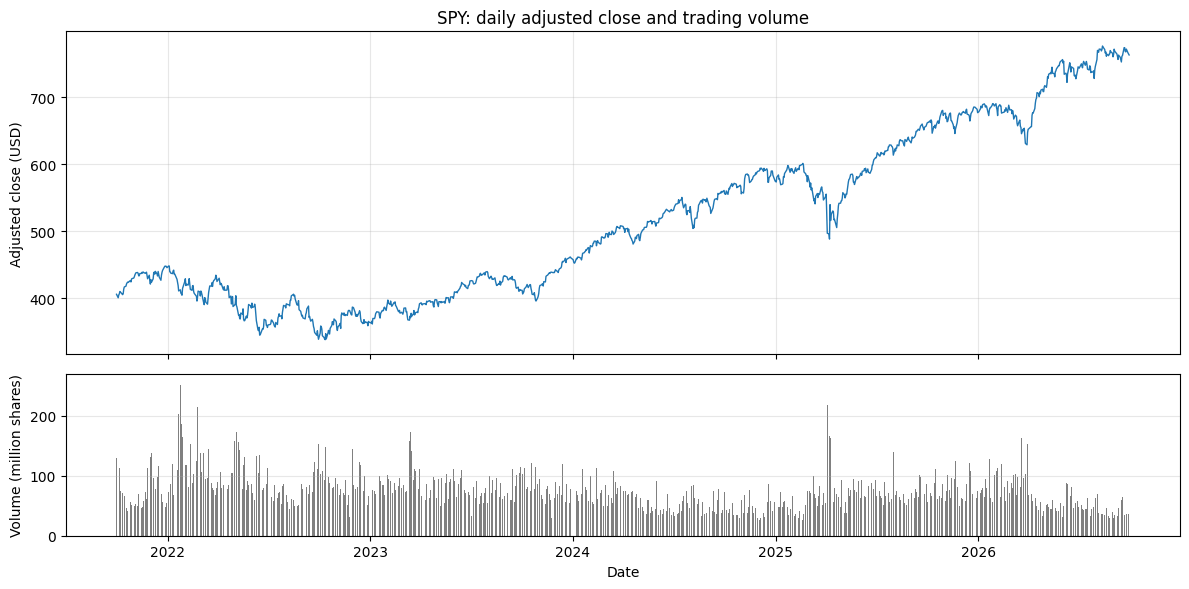

In [34]:
fig_raw, axes = plt.subplots(
    2, 1,
    figsize=(12, 6),
    sharex=True,
    gridspec_kw={"height_ratios": [2, 1]},
)

# Adjusted closing price
axes[0].plot(
    df_raw.index, df_raw["Adj Close"],
    color="tab:blue", linewidth=1,
)
axes[0].set_title(f"{TICKER}: daily adjusted close and trading volume")
axes[0].set_ylabel("Adjusted close (USD)")
axes[0].grid(alpha=0.3)

# Daily trading volume, displayed in millions of shares
axes[1].bar(
    df_raw.index, df_raw["Volume"] / 1_000_000,
    color="grey", width=0.8,
)
axes[1].set_ylabel("Volume (million shares)")
axes[1].set_xlabel("Date")
axes[1].grid(axis="y", alpha=0.3)

fig_raw.tight_layout()

# Save the plot for W&B logging in Section 4.
RAW_PLOT_FILE = DATA_DIR / f"{TICKER}_price_and_volume.png"
fig_raw.savefig(RAW_PLOT_FILE, dpi=150, bbox_inches="tight")

plt.show()
plt.close(fig_raw)

### 4. Record the downloaded sample with W&B

The CSV is the data used in this run. W&B stores it as an Artifact with a version number, so later runs can record exactly which dataset they used. The API key is not saved in the notebook.

Opening the notebook does not run the code. Running the cells again downloads or fits again where those operations appear. In a normal complete execution, W&B creates new run IDs even if the display names repeat. Changed Artifact contents get another version; older versions remain available. Local files with the same paths are overwritten. The Q2(c) plotting cell also records a W&B evaluation run, even though it reuses predictions already in memory. The quieter console setting changes the amount of progress text, not what we track.

In [35]:
from google.colab import userdata
wandb.login(key=userdata.get('WANDB_API_KEY'))

data_config = {
    "ticker": TICKER,
    "source": "quantmod.markets.getTicker / Yahoo Finance",
    "start_date": START_DATE,
    "end_date_exclusive": END_DATE,
    "interval": "1d",
    "auto_adjust": False,
    "retrieved_at_utc": datetime.now(timezone.utc).isoformat(),
    "package_versions": {
        name: version(name)
        for name in ["quantmod", "yfinance", "pandas", "numpy", "scikit-learn", "statsmodels", "wandb"]
    },
}

with wandb.init(
    project=WANDB_PROJECT, entity=WANDB_ENTITY,
    job_type="data-preparation", config=data_config,
) as data_run:
    raw_artifact = wandb.Artifact("spy-raw", type="dataset", metadata=data_config)
    raw_artifact.add_file(str(RAW_FILE))
    raw_artifact.add_file(str(RAW_PLOT_FILE))
    data_run.log({"raw_price_and_volume": wandb.Image(str(RAW_PLOT_FILE))})
    logged_raw = data_run.log_artifact(raw_artifact)
    logged_raw.wait()
    DATASET_ARTIFACT_REF = f"{data_run.entity}/{data_run.project}/spy-raw:{logged_raw.version}"
    data_run.summary["observations"] = len(df_raw)
    data_run.summary["first_date"] = str(df_raw.index.min().date())
    data_run.summary["last_date"] = str(df_raw.index.max().date())
    WANDB_DATA_RUN_URL = data_run.url

print("Data run:", WANDB_DATA_RUN_URL)
print("Dataset version:", DATASET_ARTIFACT_REF)


wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: WARNING [wandb.login()] Changing session credentials to explicit value for https://api.wandb.ai.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: Currently logged in as: leon-shawn (leon-shawn-123) to https://api.wandb.ai. Use `wandb login --relogin` to force relogin


wandb: WARNING Artifact "spy-raw" already exists with the same content. No new version will be created.


Data run: https://wandb.ai/leon-shawn-123/cqf-exam3-spy/runs/dt6vrbpa
Dataset version: leon-shawn-123/cqf-exam3-spy/spy-raw:v8


### 5. Create candidate features

I start with **54 features across seven groups**: returns, earlier returns, intraday changes, volatility, trend, volume and Bollinger-band measures. These describe different aspects of SPY’s price movements and trading activity. Different windows also let us look over a few days or several weeks. Some features overlap on purpose; for example, cumulative log return and percentage change both describe a price move. The funnel compares which versions to keep.

All these features come from SPY’s daily open, high, low, close and volume (OHLCV). This gives a broad starting set within price and volume data, although 54 features do not mean 54 independent sources of information.

`MA_DIST` replaces an absolute moving average with price relative to its average.
`BB_POS` and `BB_WIDTH` replace raw Bollinger-band price levels. Volume is used
through changes or relative activity. Every window ends at the current date,
and every lag points backward. The decision is assumed to be made after that
day's close for the following trading day's adjusted-close return.

Q1(b) gives the formulas and explains why these transformations may help with stationarity. `feature_info` also records the formula for each column.

News articles and financial reports could add another type of information. Text-processing libraries can turn their wording into numerical features, such as scores for positive or negative tone. I leave this out of the project. It would mean collecting relevant documents, cleaning the text, choosing an extraction method and matching each feature to when the information became public. For reports, that means using the release date and time rather than the financial period the report describes. This would be a substantial extra piece of work. Here I keep the scope to one consistent daily market dataset and focus on the feature-selection and tree-model comparison requested by the exam. I have not tested whether text features would improve the results.


In [36]:
def create_features(raw):
    price = raw["Adj Close"]
    adjustment = price / raw["Close"]
    open_price = raw["Open"] * adjustment
    high = raw["High"] * adjustment
    low = raw["Low"] * adjustment
    volume = raw["Volume"].replace(0, np.nan)
    returns = np.log(price).diff()

    features = pd.DataFrame(index=raw.index)
    descriptions = []

    def add(name, values, family, formula):
        features[name] = values
        descriptions.append({"feature": name, "family": family, "formula": formula})

    add("RET", returns, "return", "log(P_t / P_(t-1))")
    add("OC", price / open_price - 1, "intraday", "P_t / O_t - 1")
    add("HL", high / low - 1, "intraday", "H_t / L_t - 1")
    add("GAP", open_price / price.shift(1) - 1, "intraday", "O_t / P_(t-1) - 1")
    add("VRET", np.log(volume).diff(), "volume", "log(V_t / V_(t-1))")

    for lag in RETURN_LAGS:
        add(f"RET_LAG{lag}", returns.shift(lag), "lag", f"r_(t-{lag})")

    for window in WINDOWS:
        ma = price.rolling(window).mean()
        price_std = price.rolling(window).std()
        lower = ma - 2 * price_std
        upper = ma + 2 * price_std

        add(f"PCHG{window}", price.pct_change(window, fill_method=None), "return", f"P_t / P_(t-{window}) - 1")
        add(f"RET{window}", returns.rolling(window).sum(), "return", f"sum of the last {window} log returns")
        add(f"STD{window}", returns.rolling(window).std(), "volatility", f"sample std of the last {window} log returns")
        add(f"MA_DIST{window}", price / ma - 1, "trend", f"P_t / SMA_{window}(P)_t - 1")
        add(f"VCHG{window}", volume.pct_change(window, fill_method=None), "volume", f"V_t / V_(t-{window}) - 1")
        add(f"VMA_DIST{window}", volume / volume.rolling(window).mean() - 1, "volume", f"V_t / SMA_{window}(V)_t - 1")

        for name in ["OC", "HL", "GAP"]:
            add(f"{name}{window}", features[name].rolling(window).mean(), "intraday", f"mean of the last {window} {name} values")

        add(f"BB_WIDTH{window}", (upper - lower) / ma, "band", f"(upper_{window} - lower_{window}) / SMA_{window}(P)")
        add(f"BB_POS{window}", (price - lower) / (upper - lower), "band", f"(P_t - lower_{window}) / (upper_{window} - lower_{window})")

    return features, pd.DataFrame(descriptions).set_index("feature")


features, feature_info = create_features(df_raw)
print("Candidate features:", features.shape[1])
display(feature_info)


Candidate features: 54


,family,formula
feature,,
RET,return,log(P_t / P_(t-1))
OC,intraday,P_t / O_t - 1
HL,intraday,H_t / L_t - 1
GAP,intraday,O_t / P_(t-1) - 1
VRET,volume,log(V_t / V_(t-1))
RET_LAG1,lag,r_(t-1)
RET_LAG2,lag,r_(t-2)
RET_LAG3,lag,r_(t-3)
RET_LAG5,lag,r_(t-5)


### 6. Create one binary label

Let $r_{t+1}=\log(P_{t+1}/P_t)$ and let $\hat\sigma_{20,t}$ be the sample standard
deviation of the 20 daily log returns ending at $t$. Define

$$\tau_t=0.2\hat\sigma_{20,t},\qquad
Y_t=\mathbf{1}\{r_{t+1}>\tau_t\}.$$

Label 1 means the next trading day’s positive return is larger than the threshold. Label 0 includes downward, flat and small positive moves. The cutoff gets smaller in quiet periods and larger in volatile periods. For example, daily volatility of 1% gives a cutoff of about 0.2% in log-return units. This excludes very small positive moves relative to recent fluctuations. Volatility includes both random and information-driven moves, so passing this cutoff does not prove that a return contains a genuine signal.

The general idea of scaling return barriers with volatility has related support in financial-ML literature [10]. Lab 13 also gives examples of threshold-based binary labels. Our exact one-day rule is a project choice; it is not copied from that reference or prescribed by the lab, and it is not triple-barrier labeling.

I use **20 trading days** as a recent window of roughly one trading month. It uses more than a few observations while still responding to changing conditions. I choose **0.2** as a modest cutoff that groups tiny positive returns with label 0 while keeping a substantial positive class. These choices were fixed before comparing models. I have not shown that they are optimal for SPY. The threshold uses volatility already known at $t$; it is neither a significance test nor an estimate of trading costs.

We use `shift(-1)` to match each day’s row with the next trading day’s return and date. These are used to create and record the label. The model’s input features use only information from the current day or earlier days. We remove the early rows that do not yet have enough history to calculate rolling features, and the final row because its next-day return is unknown. We remove these incomplete rows before assigning labels of 0 or 1, without filling missing values using information from later days.

In [37]:
price = df_raw["Adj Close"]
returns = np.log(price).diff()
label_threshold = LABEL_VOL_MULTIPLIER * returns.rolling(LABEL_VOL_WINDOW).std()
future_return = returns.shift(-1)
target_date = pd.Series(df_raw.index, index=df_raw.index).shift(-1)

df_model = features.copy()
df_model["future_return"] = future_return
df_model["label_threshold"] = label_threshold
df_model["target_date"] = target_date
df_model = df_model.replace([np.inf, -np.inf], np.nan).dropna()
df_model["Label"] = (df_model["future_return"] > df_model["label_threshold"]).astype(int)

feature_names = list(features.columns)
X = df_model[feature_names]
y = df_model["Label"]

print(f"Usable labelled rows: {len(df_model)}")
print(f"Warm-up/incomplete rows removed: {len(df_raw) - len(df_model)}")
display(df_model[["RET", "future_return", "label_threshold", "Label", "target_date"]].head())


Usable labelled rows: 1193
Warm-up/incomplete rows removed: 61


,RET,future_return,label_threshold,Label,target_date
Date,,,,,
2021-12-28,-0.000817,0.001278,0.002425,0,2021-12-29
2021-12-29,0.001278,-0.002768,0.002212,0,2021-12-30
2021-12-30,-0.002768,-0.002523,0.002133,0,2021-12-31
2021-12-31,-0.002523,0.005773,0.002065,1,2022-01-03
2022-01-03,0.005773,-0.000335,0.002006,0,2022-01-04


### 7. Chronological training and final-test split

We keep the last 20% of usable dates for the final test. The earlier training data is also called **development data** below. We leave out one row between training and testing because that row’s next-day label would use the first test day’s price. This keeps all training labels based on prices from before testing starts.

Features use only information available at the prediction date, including earlier history from the training period. We select features using training data and CV, and keep the final test period for evaluation. We also report the proportions of training labels 0 and 1 to show whether the classes are balanced.

In [38]:
split = int(len(X) * (1 - TEST_FRACTION))
X_train = X.iloc[:split - 1].copy()
y_train = y.iloc[:split - 1].copy()
X_test = X.iloc[split:].copy()
y_test = y.iloc[split:].copy()

split_table = pd.DataFrame([
    {"sample": "Training / development", "rows": len(X_train), "start": str(X_train.index.min().date()), "end": str(X_train.index.max().date())},
    {"sample": "Final test (reserved)", "rows": len(X_test), "start": str(X_test.index.min().date()), "end": str(X_test.index.max().date())},
])
display(split_table)
display(y_train.value_counts().sort_index().rename("training_rows").to_frame())


,sample,rows,start,end
0,Training / development,953,2021-12-28,2025-10-14
1,Final test (reserved),239,2025-10-16,2026-09-29


,training_rows
Label,
0,536
1,417


## A. Feature Engineering & Selection Using the Funneling Approach [30 Marks]

### Question 1

Perform feature selection for your machine learning models using a multi-step funneling process by combining techniques from Filter, Wrapper, and Embedded methods.

#### (a)

Explain the feature selection funnel using the three distinct categories of feature selection methods, step by step. You must provide the exact mathematical formulation for the metric or objective used in each stage (e.g., the formula for Mutual Information score, the optimization objective of the Wrapper baseline, and the regularized loss function of the Embedded method).

**Answer — the three-stage feature funnel**

I start with the 54 features above and narrow them down in three stages [1, §4]:

- **Filter:** use statistics to remove constants, check stationarity, rank features by MI and remove highly correlated alternatives.
- **Wrapper:** fit logistic regression with different feature combinations and compare their validation scores.
- **Embedded:** fit logistic regression with an L1 penalty, which can set feature coefficients to zero.

The filter runs once on the first CV training window, about the earliest 60% of the development data. Its feature list then stays the same for all four CV folds. The wrapper and L1 comparisons use those four expanding training windows and their later validation windows, with a one-row gap. Each fit starts again, and `StandardScaler` learns its mean and standard deviation from that fold’s training rows.

These CV scores help us choose features and settings. The separate final test in Question 2 checks how the resulting models perform on later data.

In [39]:
tscv = TimeSeriesSplit(
    n_splits=N_SPLITS,
    test_size=len(X_train) // 10,
    gap=CV_GAP,
)
cv_splits = list(tscv.split(X_train))
screen_indices = cv_splits[0][0]
X_screen = X_train.iloc[screen_indices]
y_screen = y_train.iloc[screen_indices]

fold_table = pd.DataFrame([
    {
        "fold": fold,
        "train_start": str(X_train.index[train_idx[0]].date()),
        "train_end": str(X_train.index[train_idx[-1]].date()),
        "validation_start": str(X_train.index[val_idx[0]].date()),
        "validation_end": str(X_train.index[val_idx[-1]].date()),
        "train_rows": len(train_idx), "validation_rows": len(val_idx),
        "gap_rows": CV_GAP,
    }
    for fold, (train_idx, val_idx) in enumerate(cv_splits, start=1)
])
display(fold_table)
print("Filter screening dates:", X_screen.index.min().date(), "to", X_screen.index.max().date())


,fold,train_start,train_end,validation_start,validation_end,train_rows,validation_rows,gap_rows
0,1,2021-12-28,2024-04-08,2024-04-10,2024-08-23,572,95,1
1,2,2021-12-28,2024-08-22,2024-08-26,2025-01-10,667,95,1
2,3,2021-12-28,2025-01-08,2025-01-13,2025-05-29,762,95,1
3,4,2021-12-28,2025-05-28,2025-05-30,2025-10-14,857,95,1


Filter screening dates: 2021-12-28 to 2024-04-08


In [40]:
selection_config = {
    "stage": "Q1_feature_engineering_and_selection",
    "dataset_artifact": DATASET_ARTIFACT_REF,
    "windows": WINDOWS, "return_lags": RETURN_LAGS,
    "return_price": "Adj Close",
    "label_rule": "next log return > multiplier * trailing daily volatility",
    "label_vol_window": LABEL_VOL_WINDOW,
    "label_vol_multiplier": LABEL_VOL_MULTIPLIER,
    "test_fraction": TEST_FRACTION, "split_gap_rows": 1,
    "cv_n_splits": N_SPLITS, "cv_gap": CV_GAP,
    "cv_test_size": len(X_train) // 10,
    "filter_fit_start": str(X_screen.index.min().date()),
    "filter_fit_end": str(X_screen.index.max().date()),
    "stationarity_alpha": STATIONARITY_ALPHA,
    "stationarity_rule": "ADF p < alpha and KPSS p >= alpha",
    "adf_regression": "c", "adf_autolag": "AIC",
    "kpss_regression": "c", "kpss_nlags": "auto",
    "corr_threshold": CORR_THRESHOLD,
    "filter_max_features": FILTER_MAX_FEATURES,
    "mi_n_neighbors": 3,
    "wrapper": "forward selection with L2 logistic regression",
    "wrapper_max_features": WRAPPER_MAX_FEATURES,
    "wrapper_C": WRAPPER_C, "wrapper_solver": "lbfgs",
    "embedded": "L1 logistic regression", "embedded_solver": "saga",
    "embedded_C_grid": L1_C_GRID,
    "min_final_features": MIN_FINAL_FEATURES, "coefficient_tolerance": COEF_TOL,
    "cv_metric": "mean unweighted log loss", "random_seed": RANDOM_SEED,
    "scaler": "StandardScaler", "logistic_max_iter": 5000,
    "logistic_tol": 1e-4, "class_weight": None,
    "package_versions": data_config["package_versions"],
    "planned_models": ["XGBoost", "LightGBM", "CatBoost"],
}

selection_run = wandb.init(
    project=WANDB_PROJECT, entity=WANDB_ENTITY,
    job_type="feature-selection", config=selection_config,
)
selection_run.use_artifact(DATASET_ARTIFACT_REF, type="dataset")


<Artifact QXJ0aWZhY3Q6NDAzMzc4OTA3MA==>

**Stage 1 — Filter: stationarity screening, mutual information and redundancy**

I first remove features that never change in the screening sample. Next, I apply the ADF and KPSS tests explained in Q1(b). A feature passes when its ADF $p$-value is below $0.05$ and its KPSS $p$-value is at least $0.05$.

Next, I rank the remaining features by their estimated **mutual information (MI)** with the next-day binary label. MI measures how strongly a feature and the label are related, including relationships that are not linear [1, §2.4]. For a continuous feature $X_j$ and binary label $Y$,

$$
I(X_j;Y)=
\sum_{y\in\{0,1\}}\int
p_j(x,y)\log\left(
\frac{p_j(x,y)}{p_j(x)p_Y(y)}
\right)\,dx.
$$

Here, $p_j(x)$ is the density of feature values, $p_Y(y)$ is the probability of each label, and $p_j(x,y)$ describes the feature value and label together. If they are independent, the joint distribution equals the product of the two separate distributions, so MI is zero.

I estimate MI with `mutual_info_classif`, using `n_neighbors=3` and `random_state=42` [3]. It looks at nearby **feature values**, not nearby dates, to estimate how the feature and label are related. Three neighbours is the default. We have not added a separate `StandardScaler` here; the MI function rescales the continuous inputs internally using this screening sample. It also adds tiny random adjustments to handle repeated values. The fixed seed makes those adjustments repeatable. I keep estimated zero scores in the ranking because an estimate of zero does not prove independence.

I go through the MI ranking from highest to lowest and remove very similar features as I go. Pearson correlation measures their linear relationship:

$$
\hat{\rho}_{jk}=
\frac{\sum_t(x_{tj}-\bar{x}_j)(x_{tk}-\bar{x}_k)}
{\sqrt{
\sum_t(x_{tj}-\bar{x}_j)^2
\sum_t(x_{tk}-\bar{x}_k)^2
}}.
$$

Here, $x_{tj}$ is feature $j$’s value on date $t$, and $\bar{x}_j$ is its sample mean.

I discard a candidate if its absolute correlation with **any feature already kept** exceeds $0.90$. Otherwise, I keep it, stopping when I have retained 24 features or reached the end of the list. Processing higher-MI features first gives them priority when two features are strongly correlated. Equal MI scores are ordered alphabetically by feature name.

The $0.90$ cutoff follows the labs as a simple rule for removing similar features. All calculations here use `X_screen` and `y_screen`, the first CV training window. The kept list stays fixed for the later folds.

In [41]:
constant_features = X_screen.columns[X_screen.nunique() <= 1].tolist()
nonconstant_features = [name for name in feature_names if name not in constant_features]

stationarity_rows = []
for name in nonconstant_features:
    values = X_screen[name]
    adf_result = adfuller(values, regression="c", autolag="AIC")
    # KPSS reports a warning when its p-value lies outside its tabulated range.
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", InterpolationWarning)
        kpss_result = kpss(values, regression="c", nlags="auto")
    stationarity_rows.append({
        "feature": name, "ADF_stat": adf_result[0], "ADF_p": adf_result[1],
        "ADF_lags": adf_result[2], "KPSS_stat": kpss_result[0],
        "KPSS_p": kpss_result[1], "KPSS_lags": kpss_result[2],
        "stationarity_pass": adf_result[1] < STATIONARITY_ALPHA and kpss_result[1] >= STATIONARITY_ALPHA,
    })

stationarity_table = pd.DataFrame(stationarity_rows).set_index("feature")
stationary_features = stationarity_table.index[stationarity_table["stationarity_pass"]].tolist()
mi_scores = pd.Series(
    mutual_info_classif(
        X_screen[stationary_features], y_screen,
        discrete_features=False, n_neighbors=3, random_state=RANDOM_SEED,
    ),
    index=stationary_features, name="MI_score",
)
ranked_features = sorted(stationary_features, key=lambda name: (-mi_scores[name], name))
corr = X_screen[stationary_features].corr().abs()

filter_features = []
filter_rows = []
for name in ranked_features:
    blocker = None
    max_corr = 0.0
    if filter_features:
        correlations = corr.loc[name, filter_features]
        blocker = correlations.idxmax()
        max_corr = float(correlations.max())
    if max_corr > CORR_THRESHOLD:
        decision = f"discard: correlation with {blocker} > {CORR_THRESHOLD}"
    elif len(filter_features) >= FILTER_MAX_FEATURES:
        decision = "discard: MI rank below feature budget"
    else:
        filter_features.append(name)
        decision = "retain"
    filter_rows.append({
        "feature": name, "MI_score": float(mi_scores[name]),
        "max_corr_with_retained": max_corr, "decision": decision,
    })

filter_table = pd.DataFrame(filter_rows).set_index("feature")
print("Constants removed:", constant_features)
print(f"Stationarity screening: {len(nonconstant_features)} -> {len(stationary_features)}")
print(f"MI/correlation filter: {len(stationary_features)} -> {len(filter_features)}")
display(filter_table)
selection_run.log({"filter/features_retained": len(filter_features)})


Constants removed: []
Stationarity screening: 54 -> 22
MI/correlation filter: 22 -> 19


,MI_score,max_corr_with_retained,decision
feature,,,
VMA_DIST7,0.026069,0.000000,retain
RET_LAG5,0.016721,0.016412,retain
RET_LAG2,0.013929,0.107421,retain
RET_LAG10,0.009756,0.038225,retain
OC28,0.009673,0.139383,retain
VRET,0.008531,0.691756,retain
OC,0.007768,0.183137,retain
RET,0.007664,0.822255,retain
RET_LAG1,0.004707,0.177158,retain


**Stage 2 — Wrapper: sequential forward selection**

The wrapper tries different feature combinations with logistic regression. Each combination uses the same four CV folds, so it is compared over the same dates.

Within each fold, I standardise the features using the mean and standard deviation of that fold’s training data. I apply the same transformation to its validation data. Logistic regression then predicts the probability of label $1$:

$$
p_t=\sigma(b+\beta^\top z_t),
\qquad
\sigma(u)=\frac{1}{1+e^{-u}}.
$$

Here, $z_t$ contains the standardised feature values on date $t$, $\beta$ contains their fitted coefficients, and $b$ is the intercept. The sigmoid function $\sigma$ converts the model’s output into a probability between $0$ and $1$.

I assess these probabilities using **log loss**:

$$
\ell(y,p)=-y\log p-(1-y)\log(1-p).
$$

Log loss is lower when the model assigns a higher probability to the correct label. It gives a large penalty to confident but incorrect predictions.

For a candidate feature subset $S$, the model is fitted separately on each training fold $T_k$ by minimising

$$
\underset{b,\beta}{\operatorname{minimise}}
\quad
\frac{1}{n_k}\sum_{t\in T_k}\ell(y_t,p_t)
+
\frac{1}{2n_kC}\lVert\beta\rVert_2^2,
\qquad C=1.
$$

Here, $n_k$ is the number of training observations in fold $k$. The first term is the average training log loss. The second is an **L2 penalty**, proportional to the sum of squared coefficients, which discourages very large coefficients. I keep its strength fixed at $C=1$ throughout the wrapper search. This is scikit-learn’s unweighted L2 logistic-regression objective written using average loss [3]. With the `lbfgs` solver, the intercept is not penalised.

The L2 penalty helps control the fitted coefficients. **Feature removal in this stage comes from comparing subsets**, rather than from the penalty.

After fitting a feature combination, I average its validation log loss over the four folds:

$$
J(S)=
\frac{1}{K}\sum_{k=1}^{K}
\frac{1}{|V_k|}
\sum_{t\in V_k}
\ell\left(y_t,\hat p_{t,S}^{(k)}\right),
\qquad K=4.
$$

Here, $V_k$ is fold $k$’s validation period, and $\hat p_{t,S}^{(k)}$ is the probability predicted by the model fitted on that fold’s training data. **A lower $J(S)$ means better CV performance.**

I select features using **forward selection**. Starting with no selected features, I try adding each available feature separately. I keep the addition that gives the lowest average CV log loss, then repeat with the remaining candidates. Mathematically,

$$
S_0=\varnothing,
$$

$$
j_m=\arg\min_{j\notin S_{m-1}}
J\left(S_{m-1}\cup\{j\}\right),
\qquad
S_m=S_{m-1}\cup\{j_m\}.
$$

Here, $j_m$ is the feature added at step $m$, and $S_m$ is the resulting feature list.

I stop at 12 features, or fewer if the filter supplied fewer. This limit is fixed in advance. The search keeps going even if the next addition makes CV loss worse, so I show the change in loss at every step.

This is a greedy search: try one addition, keep the best one, then continue. Earlier choices stay in the list. It is quicker than testing every possible combination, but can miss a better combination [1, §4.1; 3].

In [42]:
def make_logistic(C, penalty):
    solver = "lbfgs" if penalty == "l2" else "saga"
    return make_pipeline(
        StandardScaler(),
        LogisticRegression(
            penalty=penalty, C=C, solver=solver,
            max_iter=5000, tol=1e-4, random_state=RANDOM_SEED,
        ),
    )


def cv_log_losses(columns, C=1.0, penalty="l2"):
    losses = []
    for train_idx, val_idx in cv_splits:
        model = make_logistic(C, penalty)
        model.fit(X_train.iloc[train_idx][columns], y_train.iloc[train_idx])
        probabilities = model.predict_proba(X_train.iloc[val_idx][columns])[:, 1]
        losses.append(log_loss(y_train.iloc[val_idx], probabilities, labels=[0, 1]))
    return np.array(losses)


# An intercept-only probability benchmark, learned separately in every fold.
baseline_losses = []
for train_idx, val_idx in cv_splits:
    positive_rate = y_train.iloc[train_idx].mean()
    baseline_losses.append(log_loss(
        y_train.iloc[val_idx], np.full(len(val_idx), positive_rate), labels=[0, 1],
    ))
baseline_cv_loss = float(np.mean(baseline_losses))

wrapper_features = []
remaining = filter_features.copy()
wrapper_rows = []
wrapper_candidate_rows = []
previous_loss = baseline_cv_loss
wrapper_count = min(WRAPPER_MAX_FEATURES, len(filter_features))

for step in range(1, wrapper_count + 1):
    candidates = []
    for name in remaining:
        losses = cv_log_losses(wrapper_features + [name], C=WRAPPER_C, penalty="l2")
        row = {"step": step, "candidate": name, "mean_cv_log_loss": float(losses.mean())}
        row.update({f"fold_{i}_log_loss": float(loss) for i, loss in enumerate(losses, start=1)})
        wrapper_candidate_rows.append(row)
        candidates.append(row)

    best = min(candidates, key=lambda row: (row["mean_cv_log_loss"], row["candidate"]))
    wrapper_features.append(best["candidate"])
    remaining.remove(best["candidate"])
    wrapper_rows.append({
        **best,
        "improvement_vs_previous": previous_loss - best["mean_cv_log_loss"],
    })
    previous_loss = best["mean_cv_log_loss"]
    print(f"Step {step}: add {best['candidate']}; CV log loss = {previous_loss:.4f}")

wrapper_table = pd.DataFrame(wrapper_rows)
wrapper_candidates = pd.DataFrame(wrapper_candidate_rows)
print(f"Intercept-only CV log loss: {baseline_cv_loss:.4f}")
display(wrapper_table)
selection_run.log({
    "wrapper/features_retained": len(wrapper_features),
    "wrapper/cv_log_loss": previous_loss,
    "baseline/cv_log_loss": baseline_cv_loss,
})


Step 1: add OC7; CV log loss = 0.6947
Step 2: add VCHG28; CV log loss = 0.6938
Step 3: add VMA_DIST60; CV log loss = 0.6928
Step 4: add OC28; CV log loss = 0.6923
Step 5: add RET_LAG5; CV log loss = 0.6918
Step 6: add OC14; CV log loss = 0.6916
Step 7: add RET_LAG10; CV log loss = 0.6915
Step 8: add RET_LAG3; CV log loss = 0.6916
Step 9: add MA_DIST7; CV log loss = 0.6917
Step 10: add VMA_DIST7; CV log loss = 0.6925
Step 11: add VCHG7; CV log loss = 0.6932
Step 12: add VRET; CV log loss = 0.6940
Intercept-only CV log loss: 0.6970


,step,candidate,mean_cv_log_loss,fold_1_log_loss,fold_2_log_loss,fold_3_log_loss,fold_4_log_loss,improvement_vs_previous
0,1,OC7,0.694741,0.714701,0.685808,0.673626,0.704830,0.002212
1,2,VCHG28,0.693784,0.714990,0.685075,0.673226,0.701845,0.000957
2,3,VMA_DIST60,0.692833,0.714534,0.684320,0.669221,0.703258,0.000951
3,4,OC28,0.692265,0.714659,0.684307,0.668620,0.701473,0.000569
4,5,RET_LAG5,0.691773,0.714497,0.684175,0.667817,0.700605,0.000491
5,6,OC14,0.691577,0.713298,0.683142,0.666159,0.703710,0.000196
6,7,RET_LAG10,0.691524,0.713362,0.683077,0.666090,0.703569,0.000053
7,8,RET_LAG3,0.691595,0.722286,0.677394,0.653900,0.712800,-0.000071
8,9,MA_DIST7,0.691660,0.726326,0.676753,0.651186,0.712374,-0.000065
9,10,VMA_DIST7,0.692486,0.727213,0.677955,0.652414,0.712362,-0.000826


**Stage 3 — Embedded: L1 logistic regression**

I now take the wrapper’s features and fit logistic regression with an **L1 penalty** instead of L2:

$$
\underset{b,\beta}{\operatorname{minimise}}
\quad
\frac{1}{n}\sum_{t=1}^{n}\ell(y_t,p_t)
+
\frac{1}{nC}
\sum_{j\in S_{\mathrm{wrapper}}}|\beta_j|.
$$

Here, $n$ is the number of training observations, and $S_{\mathrm{wrapper}}$ is the feature set passed forward from the wrapper stage. The first term is the average training log loss. The second penalises the sum of the absolute coefficient values.

Unlike L2, **L1 can make some coefficients exactly zero during fitting**. A feature with a zero coefficient no longer contributes to the prediction. Feature selection therefore happens as part of fitting the model, which makes this an embedded method [3].

I fit this with scikit-learn’s `saga` solver. The equation follows its logistic-regression documentation [3]. Scaling is still fitted on each fold’s training rows only. There are no class weights, and the intercept is not penalised.

The parameter $C$ controls the penalty strength: **larger $C$ means a weaker penalty**, usually allowing more coefficients to remain nonzero. In the equation above, the penalty multiplier is $1/(nC)$, rather than $C$ itself.

I compare the predefined values of $C$ using the same four CV folds and their average validation log loss. For each $C$, I also fit the model again using all development data to identify which features it retains. I count a feature as retained when

$$
|\hat{\beta}_j|>10^{-6}.
$$

This small tolerance treats coefficients extremely close to zero as zero, avoiding the selection of features because of tiny numerical leftovers. Both positive and negative coefficients are retained if their absolute values exceed the tolerance.

I choose the $C$ with the lowest CV loss **among settings that retain at least eight features**. If the wrapper provides fewer than eight features, I require all of them to remain:

$$
C^*=
\arg\min_{\substack{C\in\mathcal C\\|S(C)|\ge m}}
J_{\mathrm{L1}}(C),
\qquad
m=\min\left(8,|S_{\mathrm{wrapper}}|\right).
$$

Here, $\mathcal C$ is the set of candidate $C$ values, $S(C)$ is the feature set retained by the fit on all development data, and $J_{\mathrm{L1}}(C)$ is its average CV validation loss.

I set the eight-feature minimum to keep a fairly broad set for the tree models. I also show the best CV result without this minimum, so we can see whether that rule costs any performance.

The final features are $S(C^*)$, from the fit on all development data using the chosen penalty. The final test is not used to choose them.

In [43]:
embedded_rows = []
embedded_models = {}
minimum_features = min(MIN_FINAL_FEATURES, len(wrapper_features))

for C in L1_C_GRID:
    losses = cv_log_losses(wrapper_features, C=C, penalty="l1")
    model = make_logistic(C, "l1")
    model.fit(X_train[wrapper_features], y_train)
    coefficients = model.named_steps["logisticregression"].coef_[0]
    selected_count = int((np.abs(coefficients) > COEF_TOL).sum())
    row = {
        "C": C, "mean_cv_log_loss": float(losses.mean()),
        "cv_std": float(losses.std(ddof=1)), "n_selected": selected_count,
        "eligible": selected_count >= minimum_features,
    }
    row.update({f"fold_{i}_log_loss": float(loss) for i, loss in enumerate(losses, start=1)})
    embedded_rows.append(row)
    embedded_models[C] = model

embedded_table = pd.DataFrame(embedded_rows)
eligible = embedded_table[embedded_table["eligible"]]
if eligible.empty:
    raise ValueError("No C retains the requested feature budget. Extend L1_C_GRID or reconsider that budget.")

best_row = eligible.sort_values(["mean_cv_log_loss", "C"]).iloc[0]
unconstrained_row = embedded_table.sort_values(["mean_cv_log_loss", "C"]).iloc[0]
BEST_C = float(best_row["C"])
embedded_model = embedded_models[BEST_C]
coefficients = pd.Series(
    embedded_model.named_steps["logisticregression"].coef_[0],
    index=wrapper_features, name="L1_coefficient",
)
selected_features = coefficients.index[coefficients.abs() > COEF_TOL].tolist()

display(embedded_table)
print(f"Unconstrained best: C={unconstrained_row['C']}, {int(unconstrained_row['n_selected'])} features")
print(f"Chosen: C={BEST_C}, {len(selected_features)} features, CV log loss={best_row['mean_cv_log_loss']:.4f}")
display(coefficients.to_frame().assign(retained=coefficients.abs() > COEF_TOL))
selection_run.log({
    "embedded/best_C": BEST_C,
    "embedded/cv_log_loss": float(best_row["mean_cv_log_loss"]),
    "embedded/unconstrained_cv_log_loss": float(unconstrained_row["mean_cv_log_loss"]),
    "embedded/features_retained": len(selected_features),
})


,C,mean_cv_log_loss,cv_std,n_selected,eligible,fold_1_log_loss,fold_2_log_loss,fold_3_log_loss,fold_4_log_loss
0,0.01,0.696999,0.011979,0,False,0.706681,0.689947,0.683776,0.707589
1,0.03,0.696972,0.011972,2,False,0.705703,0.690022,0.683755,0.708407
2,0.10,0.696705,0.020702,5,False,0.713943,0.688462,0.671228,0.713185
3,0.30,0.695821,0.025745,9,True,0.721752,0.684869,0.665052,0.711610
4,1.00,0.694539,0.032566,11,True,0.728094,0.684474,0.653825,0.711765
5,3.00,0.694264,0.034597,12,True,0.729982,0.684088,0.650790,0.712196
6,10.00,0.694149,0.035418,12,True,0.730716,0.683981,0.649531,0.712368
7,100.00,0.694105,0.035744,12,True,0.731008,0.683944,0.649031,0.712437


Unconstrained best: C=100.0, 12 features
Chosen: C=100.0, 12 features, CV log loss=0.6941


,L1_coefficient,retained
OC7,-0.162663,True
VCHG28,0.192213,True
VMA_DIST60,-0.031167,True
OC28,0.115733,True
RET_LAG5,-0.063441,True
OC14,-0.066457,True
RET_LAG10,0.018422,True
RET_LAG3,-0.135115,True
MA_DIST7,0.088609,True
VMA_DIST7,0.099470,True


**What happened in this run**

The process reduced the original 54 features to 12. No constant features were found. Of the 54 candidates, 22 passed the ADF/KPSS screening rule, and MI ranking with correlation pruning retained 19. The filter therefore returned fewer than its 24-feature limit. The wrapper then selected 12 features using forward selection.

The wrapper’s best average CV log loss was about $0.6915$, with seven features. Continuing to the chosen limit of 12 increased it to about $0.6940$. The main experiment keeps the fixed 12-feature budget, so this is not the subset with the lowest wrapper score.

That seven-feature result comes from **logistic regression**. It does not establish that seven is better for boosted trees. The follow-up at the end of Q2(c) compares the first seven wrapper features with the original twelve under the same tree settings. The original feature list is kept visible.

For L1, $C=100$ gave the lowest average CV loss, about $0.6941$. This is a weak penalty, and all 12 wrapper features remained. Stronger penalties removed features but had worse average CV loss. The eight-feature minimum did not change the chosen setting.

The L1 model was only slightly better than the intercept-only baseline, whose CV loss was about $0.6970$. That baseline predicts the training fraction of label 1 in each fold. Also, we used these CV scores to make our choices, so they may look better than the results on new data.

There are things this funnel can miss. MI looks at one feature at a time, so it can miss features that help only when used together. Correlation pruning can remove a similar feature that still adds something useful. Logistic regression can also miss nonlinear effects or interactions that trees could use. Question 2 checks the selected features on later data.

#### (b)

Provide a formal mathematical justification for the feature transformations used to ensure stationarity (e.g., log returns or fractional differentiation equations) and document the pruning metrics at each tier of the funnel. Justify the specific statistical or structural selection criteria used to retain or discard features at each step.

**Answer — transformations and stationarity**

I use changes and relative indicators rather than absolute price and volume levels. This reduces the influence of their long-term growth, although it does not automatically make every feature stationary.

Let $P_t$ be the adjusted closing price. I put the downloaded open, high and low prices on the same adjusted scale by multiplying each by that day’s adjusted-close/close ratio. I denote these adjusted prices by $O_t$, $H_t$ and $L_t$, and daily trading volume by $V_t$. Applying the same adjustment to all prices within a day leaves their ratios unchanged. Returns and opening gaps between different days use the consistently adjusted prices.

**What stationarity means here**

A weakly stationary series has a constant mean, a finite constant variance, and a covariance that depends on the distance between observations rather than their particular dates:

$$
E[Z_t]=\mu,\qquad
\operatorname{Var}(Z_t)=\sigma^2,\qquad
\operatorname{Cov}(Z_t,Z_{t-h})=\gamma(h).
$$

I want features whose statistical behaviour stays reasonably similar over time. Then what the model learns from earlier dates has a better chance of being useful later. Price levels may keep trending or accumulating random shocks. Taking a logarithm changes the scale, but can leave that problem in place. I therefore use the change between consecutive log prices:

$$
r_t=\log P_t-\log P_{t-1}
=\log\left(\frac{P_t}{P_{t-1}}\right).
$$

Here is a simple model showing why this can help. Suppose log price follows

$$
\log P_t=\log P_{t-1}+d+\varepsilon_t.
$$

Assume the shocks $\varepsilon_t$ are independent and identically distributed, with zero mean and variance $\sigma_\varepsilon^2>0$. Keep the initial log price fixed. Then

$$
E[\log P_t]=\log P_0+td,\qquad
\operatorname{Var}(\log P_t)=t\sigma_\varepsilon^2.
$$

The variance grows with time, so the log-price level is nonstationary. Taking the difference gives $r_t=d+\varepsilon_t$, which is stationary under these assumptions. This explains how returns can be stationary even when log prices are not. It is an example model, not proof that SPY follows it [2, §9.1].

**Returns, volatility and lagged features**

For a trailing window of $w$ observations, I calculate cumulative log return and sample return volatility:

$$
R_{w,t}=\sum_{i=0}^{w-1}r_{t-i},
\qquad
\bar r_{w,t}=\frac{1}{w}\sum_{i=0}^{w-1}r_{t-i},
$$

$$
s_{w,t}=
\sqrt{\frac{1}{w-1}
\sum_{i=0}^{w-1}(r_{t-i}-\bar r_{w,t})^2}.
$$

These give `RETw` $=R_{w,t}$ and `STDw` $=s_{w,t}$. The corresponding percentage price change is

$$
\mathrm{PCHG}_{w,t}
=\frac{P_t}{P_{t-w}}-1
=e^{R_{w,t}}-1.
$$

Percentage change and cumulative log return describe the same price movement in different ways. They can therefore be redundant, although their Pearson correlation need not be exactly one.

A lagged return feature is

$$
\mathrm{RET\_LAG}_{l,t}=r_{t-l}.
$$

It provides the return from $l$ trading observations earlier.

**Relative moving averages and Bollinger bands**

Instead of using the moving-average price level directly, I measure today’s price relative to its trailing average:

$$
M_{w,t}=\frac{1}{w}\sum_{i=0}^{w-1}P_{t-i},
\qquad
\mathrm{MA\_DIST}_{w,t}=\frac{P_t}{M_{w,t}}-1.
$$

A positive value means price is above its moving average; a negative value means it is below. This removes the absolute price scale. More explicitly,

$$
\mathrm{MA\_DIST}_{w,t}
=
\left[
\frac{1}{w}\sum_{i=0}^{w-1}
\exp\left(-\sum_{a=0}^{i-1}r_{t-a}\right)
\right]^{-1}-1.
$$

The empty sum for $i=0$ is zero. This expression shows that the feature depends on recent relative returns rather than the overall price level.

For Bollinger bands, let $s^P_{w,t}$ be the sample standard deviation of prices within the window:

$$
B^\pm_{w,t}=M_{w,t}\pm2s^P_{w,t}.
$$

I use relative band width and price position:

$$
\mathrm{BB\_WIDTH}_{w,t}
=\frac{B^+_{w,t}-B^-_{w,t}}{M_{w,t}}
=\frac{4s^P_{w,t}}{M_{w,t}},
$$

$$
\mathrm{BB\_POS}_{w,t}
=\frac{P_t-B^-_{w,t}}{B^+_{w,t}-B^-_{w,t}}.
$$

Multiplying every price in the window by the same positive constant leaves both features unchanged. `BB_POS` can fall below zero or exceed one when price moves outside the bands; it is not a probability.

**Intraday and volume features**

The daily price-ratio features are

$$
\mathrm{OC}_t=\frac{P_t}{O_t}-1,\qquad
\mathrm{HL}_t=\frac{H_t}{L_t}-1,\qquad
\mathrm{GAP}_t=\frac{O_t}{P_{t-1}}-1.
$$

They describe the open-to-close change, high-to-low range and previous-close-to-current-open gap. Their rolling versions are trailing arithmetic averages.

For volume, I calculate

$$
v_t=\log V_t-\log V_{t-1},
$$

$$
\mathrm{VCHG}_{w,t}=\frac{V_t}{V_{t-w}}-1,
\qquad
\mathrm{VMA\_DIST}_{w,t}
=
\frac{V_t}{\frac{1}{w}\sum_{i=0}^{w-1}V_{t-i}}-1.
$$

Here, $v_t$ is `VRET`. These features describe volume changes and volume relative to its recent average, rather than the absolute number of shares traded.

Removing the price or volume scale is helpful, but stationarity still needs assumptions. If the inputs are jointly strictly stationary, applying the same well-defined rolling calculation at each date keeps strict stationarity. Weak stationarity also needs the relevant moments to be finite. Knowing that returns are only weakly stationary is not enough to make this claim for every nonlinear feature. Changes in market conditions can still change the feature distributions.

**Empirical stationarity screening**

I test each feature that is not constant, using only the initial screening period. These tests look at the feature’s own history. They do not test whether adding it helps predict the next-day label.

For the ADF test, let $z_t$ denote the feature being tested. The test fits

$$
\Delta z_t
=
a+\gamma z_{t-1}
+\sum_{i=1}^{p}\phi_i\Delta z_{t-i}
+u_t.
$$

Here, $\Delta z_t=z_t-z_{t-1}$ is today’s change, $a$ is an intercept, and $u_t$ is the unexplained part. The lagged-change terms account for dependence on previous changes. The symbol $p$ in the sum is the number of lags, not a $p$-value. I use AIC to choose this number, balancing model fit against complexity.

The important coefficient is $\gamma$. To understand its role, consider the simpler model

$$
z_t=a+\rho z_{t-1}+u_t.
$$

Subtracting $z_{t-1}$ gives $\gamma=\rho-1$. Thus, $\gamma=0$ corresponds to $\rho=1$: a unit-root process in which random shocks accumulate rather than fade. Under the usual assumptions, this process is nonstationary.

ADF compares its statistic with a special reference distribution for unit roots; `adfuller` returns an approximate p-value. KPSS uses its own tabulated distribution.

ADF starts with the null hypothesis $H_0:\gamma=0$. A $p$-value below $0.05$ provides enough evidence to reject the unit-root hypothesis at the chosen significance level. A larger $p$-value means insufficient evidence to reject it; it does not prove that a unit root exists.

KPSS checks the feature from the opposite starting assumption: **the series is stationary around a constant level**. It first subtracts the sample mean and accumulates the resulting deviations:

$$
\hat u_i=z_i-\bar z,
\qquad
S_t=\sum_{i=1}^{t}\hat u_i.
$$

Its statistic is

$$
\mathrm{KPSS}
=
\frac{\sum_{t=1}^{n}S_t^2}{n^2\hat\omega^2}.
$$

Unusually large cumulative deviations provide evidence against a stable level. The denominator adjusts for the series’ variability and correlation between observations. I use `nlags="auto"` to choose the number of lags used to estimate the long-run variance $\hat\omega^2$.

I keep a feature only when

$$
p_{\mathrm{ADF}}<0.05
\quad\text{and}\quad
p_{\mathrm{KPSS}}\ge0.05.
$$

So ADF must reject a unit root, while KPSS must not reject level stationarity [4]. In this sample, 22 of the 54 features pass. I remove the others from this funnel; failing the rule does not prove that a feature is nonstationary.

**Why use this as a filter?** I prefer transformed features whose behaviour is reasonably stable over the early training sample. This is a conservative screening rule I chose for this project; stationarity is not a mathematical requirement for fitting a decision tree. A feature that fails can still contain useful information, and one that passes can still be useless for prediction. In this run, the rule excludes all four return-volatility features and all eight Bollinger-band features before the tree models see them. That is a consequence of this filter, not proof that those feature groups are generally unhelpful.

Even if individual feature distributions stay stable, their relationship with the next-day label can change. These tests examine the features, not whether the same predictive relationship will hold in a later market period.

These are checks on this sample, not a guarantee about future dates. I use the $0.05$ cutoff for each feature without a multiple-testing correction, so some decisions can occur by chance. KPSS can also return a table boundary: $0.01$ may mean the true $p$-value is below $0.01$, and $0.10$ may mean it is above $0.10$.

**Scaling and timing**

For logistic regression, I standardise each feature:

$$
z_{tj}=\frac{x_{tj}-\hat\mu_j}{\hat\sigma_j}.
$$

The mean and standard deviation are estimated from the relevant training fold only and then applied to its validation data. Standardisation puts features on comparable scales for regularisation; it does not remove a trend or establish stationarity.

Trailing indicators can be calculated before splitting because each row uses only information available on or before that date. Stationarity tests, MI ranking and correlation pruning use the initial screening sample. Scalers and models are fitted using their designated training periods, without using the reserved final test set.

**Answer — pruning rules and results**

The table summarises when features are removed and why. Stationarity screening and MI/correlation pruning both belong to the initial filter stage.

| Stage | Rule used | Reason |
|---|---|---|
| Basic cleaning | Remove rows with unavailable features or targets.<br><br>Remove columns that are constant within the screening sample. | Early rows lack enough history for rolling features, and the final row has no known next-day target.<br><br>A constant feature cannot distinguish observations. |
| Filter: stationarity | Keep a feature only when ADF $p<0.05$ and KPSS $p\ge0.05$, using the initial screening period. | Require evidence against a unit root, without evidence against level stationarity. |
| Filter: MI and correlation | Rank features from highest to lowest MI.<br><br>Discard a candidate if $\lvert\rho\rvert>0.90$ with any feature already kept. Retain at most 24 features. | Give priority to features associated with the label, while reducing similar predictors and computational cost. |
| Wrapper | At each step, add the feature giving the lowest average validation log loss across the same four CV folds.<br><br>Stop at 12 features, or fewer if fewer candidates are available. | Compare each addition through a fitted logistic model.<br><br>The stopping point follows the chosen feature limit, even if later additions worsen the score. |
| Embedded | Compare L1 penalty settings using CV log loss. Require at least eight retained features, or all available features if fewer than eight remain.<br><br>Keep coefficients satisfying $\lvert\hat\beta_j\rvert>10^{-6}$. | Allow fitting to remove features by setting coefficients to zero.<br><br>The minimum feature count is a rule I set for this exam, and the tolerance excludes tiny numerical leftovers. |

No constant columns were found. Stationarity screening reduced the candidates from 54 to 22, and MI/correlation pruning reduced them to 19. The wrapper selected 12 features. The chosen L1 setting, $C=100$, retained all 12, so the embedded stage made no further reduction.

The tables below show the counts and what happened to every original feature. Q1(a)’s wrapper table gives each added feature, the loss in each fold and the change in average loss. Positive improvement means lower loss. Negative improvement means that addition made the score worse. The best wrapper score was at seven features, although the search continued to 12.

The L1 table gives each tested $C$, its fold losses and how many features remained after fitting on all development data. The code produces the final feature names from these results.

In [44]:
funnel_summary = pd.DataFrame([
    {"stage": "Engineered candidates", "features": len(feature_names)},
    {"stage": "After constants", "features": len(nonconstant_features)},
    {"stage": "After stationarity screening", "features": len(stationary_features)},
    {"stage": "After MI/correlation filter", "features": len(filter_features)},
    {"stage": "After forward wrapper", "features": len(wrapper_features)},
    {"stage": "After L1 embedded", "features": len(selected_features)},
])

pruning_audit = feature_info.copy()
pruning_audit = pruning_audit.join(stationarity_table[["ADF_p", "KPSS_p", "stationarity_pass"]])
pruning_audit = pruning_audit.join(mi_scores)
pruning_audit["filter_retained"] = pruning_audit.index.isin(filter_features)
pruning_audit["wrapper_retained"] = pruning_audit.index.isin(wrapper_features)
pruning_audit["L1_coefficient"] = coefficients.reindex(pruning_audit.index)
pruning_audit["final_retained"] = pruning_audit.index.isin(selected_features)

decisions = {}
for name in feature_names:
    if name in constant_features:
        decisions[name] = "discard: constant on screening period"
    elif name not in stationary_features:
        decisions[name] = "discard: stationarity diagnostic rule"
    elif name not in filter_features:
        decisions[name] = filter_table.loc[name, "decision"]
    elif name not in wrapper_features:
        decisions[name] = "discard: outside forward-selection budget"
    elif name not in selected_features:
        decisions[name] = "discard: L1 coefficient below tolerance"
    else:
        decisions[name] = "retain for Question 2"
pruning_audit["decision"] = pd.Series(decisions)

display(funnel_summary)
display(pruning_audit[["family", "ADF_p", "KPSS_p", "MI_score", "L1_coefficient", "decision"]])

display(Markdown(
    f"The funnel reduced **{len(feature_names)} candidates to {len(selected_features)} features**. "
    f"The selected penalty was **C = {BEST_C}**. "
    f"Its CV log loss was **{best_row['mean_cv_log_loss']:.4f}**, compared with "
    f"**{baseline_cv_loss:.4f}** for the intercept-only benchmark. "
    "These scores were used for selection; final predictive performance is assessed in Question 2."
))


,stage,features
0,Engineered candidates,54
1,After constants,54
2,After stationarity screening,22
3,After MI/correlation filter,19
4,After forward wrapper,12
5,After L1 embedded,12


,family,ADF_p,KPSS_p,MI_score,L1_coefficient,decision
feature,,,,,,
RET,return,3.432760e-30,0.072593,0.007664,NaN,discard: outside forward-selection budget
OC,intraday,1.482186e-28,0.100000,0.007768,NaN,discard: outside forward-selection budget
HL,intraday,1.946830e-02,0.010000,NaN,NaN,discard: stationarity diagnostic rule
GAP,intraday,0.000000e+00,0.040638,NaN,NaN,discard: stationarity diagnostic rule
VRET,volume,2.634237e-25,0.100000,0.008531,-0.050997,retain for Question 2
RET_LAG1,lag,3.421280e-30,0.086431,0.004707,NaN,discard: outside forward-selection budget
RET_LAG2,lag,3.406754e-30,0.100000,0.013929,NaN,discard: outside forward-selection budget
RET_LAG3,lag,3.487693e-30,0.099407,0.000000,-0.135115,retain for Question 2
RET_LAG5,lag,3.554870e-30,0.100000,0.016721,-0.063441,retain for Question 2


The funnel reduced **54 candidates to 12 features**. The selected penalty was **C = 100.0**. Its CV log loss was **0.6941**, compared with **0.6970** for the intercept-only benchmark. These scores were used for selection; final predictive performance is assessed in Question 2.

#### (c)

Provide the final list of selected features that will be fed into the downstream boosting architectures.

**Answer — final feature subset for the boosting models**

The funnel leaves **12 features** in this saved SPY run. The counts below show the coverage of the starting pool and the final list.

| Feature group | Initial candidates | Finally selected |
|---|---:|---:|
| Current/cumulative returns | 9 | 0 |
| Earlier daily returns (lags) | 5 | 3 |
| Intraday price changes | 15 | 3 |
| Return volatility | 4 | 0 |
| Trend / moving-average distance | 4 | 1 |
| Volume changes and relative activity | 9 | 5 |
| Bollinger-band measures | 8 | 0 |
| **Total** | **54** | **12** |

The final features come from four groups: earlier returns, intraday changes, volume and trend. The funnel compares individual features; it does not require one feature from every group to survive.

The numbered list and detailed table below give each selected feature’s name, calculation and fitted L1 logistic-regression coefficient.

These coefficients come from the L1 fit on standardised development data. A positive coefficient raises the predicted probability of label $1$; a negative one lowers it, with the other features held fixed. This describes the fitted logistic model’s relationship, not cause and effect.

`X_train_selected` and `X_test_selected` contain the same 12 features in the same order. In Question 2, the boosting models will use their transformed values before standardisation. The scaler used for logistic regression is not passed to the tree models.

Part A completes feature selection. The boosting models are trained and evaluated in Question 2, using the reserved final test period for the final assessment.

In [45]:
final_feature_table = feature_info.loc[selected_features].copy()
final_feature_table["L1_coefficient"] = coefficients.loc[selected_features]
final_feature_table.insert(0, "number", range(1, len(selected_features) + 1))

display(Markdown("**Final selected features:**\n\n" + "\n".join(
    f"{number}. `{name}`" for number, name in enumerate(selected_features, start=1)
)))
display(final_feature_table)

X_train_selected = X_train[selected_features].copy()
X_test_selected = X_test[selected_features].copy()
print("Training features:", X_train_selected.shape)
print("Reserved test features:", X_test_selected.shape)


**Final selected features:**

1. `OC7`
2. `VCHG28`
3. `VMA_DIST60`
4. `OC28`
5. `RET_LAG5`
6. `OC14`
7. `RET_LAG10`
8. `RET_LAG3`
9. `MA_DIST7`
10. `VMA_DIST7`
11. `VCHG7`
12. `VRET`

,number,family,formula,L1_coefficient
feature,,,,
OC7,1,intraday,mean of the last 7 OC values,-0.162663
VCHG28,2,volume,V_t / V_(t-28) - 1,0.192213
VMA_DIST60,3,volume,V_t / SMA_60(V)_t - 1,-0.031167
OC28,4,intraday,mean of the last 28 OC values,0.115733
RET_LAG5,5,lag,r_(t-5),-0.063441
OC14,6,intraday,mean of the last 14 OC values,-0.066457
RET_LAG10,7,lag,r_(t-10),0.018422
RET_LAG3,8,lag,r_(t-3),-0.135115
MA_DIST7,9,trend,P_t / SMA_7(P)_t - 1,0.088609


Training features: (953, 12)
Reserved test features: (239, 12)


### Save and track the completed Part A

The results folder saves the feature formulas, stationarity checks, filter decisions, wrapper scores, L1 comparison and final feature list. The feature-data CSV contains the features and labels. The report records the date boundaries and one-row gap. I also save the fitted logistic selector so the choice can be reproduced.

W&B links the raw data to the feature dataset and selection results. For the tree models, it also records the input data version, settings, CV dates, scores and saved models.

In [46]:
ENGINEERED_FILE = DATA_DIR / "SPY_features_and_labels.csv"
df_model.to_csv(ENGINEERED_FILE, index_label="Date")

report_tables = {
    "feature_definitions": feature_info,
    "sample_split": split_table,
    "cv_folds": fold_table,
    "stationarity": stationarity_table,
    "filter": filter_table,
    "wrapper_steps": wrapper_table,
    "wrapper_candidates": wrapper_candidates,
    "embedded_comparison": embedded_table,
    "funnel_summary": funnel_summary,
    "pruning_audit": pruning_audit,
    "final_features": final_feature_table,
}
for name, table in report_tables.items():
    table.to_csv(RESULTS_DIR / f"{name}.csv", index=True)

selection_report = {
    "settings": selection_config,
    "selected_features": selected_features,
    "best_C": BEST_C,
    "selected_cv_log_loss": float(best_row["mean_cv_log_loss"]),
    "baseline_cv_log_loss": baseline_cv_loss,
    "training_positive_fraction": float(y_train.mean()),
    "raw_rows": len(df_raw), "usable_rows": len(df_model),
    "split_boundary_gap_date": str(X.index[split - 1].date()),
    "split_boundaries": split_table.to_dict(orient="records"),
    "cv_boundaries": fold_table.to_dict(orient="records"),
    "filter_features": filter_features, "wrapper_features": wrapper_features,
    "test_evaluation_status": "reserved_for_Question_2",
}
REPORT_FILE = RESULTS_DIR / "selection_report.json"
REPORT_FILE.write_text(json.dumps(selection_report, indent=2), encoding="utf-8")
MODEL_FILE = RESULTS_DIR / "logistic_feature_selector.joblib"
joblib.dump(embedded_model, MODEL_FILE)

engineered_artifact = wandb.Artifact(
    "spy-engineered-features", type="dataset",
    metadata={"raw_artifact": DATASET_ARTIFACT_REF, "label_rule": selection_config["label_rule"]},
)
engineered_artifact.add_file(str(ENGINEERED_FILE))
logged_features = selection_run.log_artifact(engineered_artifact)
logged_features.wait()
FEATURE_DATA_ARTIFACT_REF = f"{selection_run.entity}/{selection_run.project}/spy-engineered-features:{logged_features.version}"

results_artifact = wandb.Artifact(
    "spy-feature-selection", type="feature-selection",
    metadata={"selected_features": selected_features, "best_C": BEST_C, "feature_data_artifact": FEATURE_DATA_ARTIFACT_REF},
)
for name in report_tables:
    results_artifact.add_file(str(RESULTS_DIR / f"{name}.csv"))
results_artifact.add_file(str(REPORT_FILE))
results_artifact.add_file(str(MODEL_FILE))
logged_results = selection_run.log_artifact(results_artifact)
logged_results.wait()
SELECTION_ARTIFACT_REF = f"{selection_run.entity}/{selection_run.project}/spy-feature-selection:{logged_results.version}"

for name, table in report_tables.items():
    log_table = table.reset_index().astype(object)
    log_table = log_table.where(pd.notna(log_table), None)
    selection_run.log({name: wandb.Table(dataframe=log_table)})
selection_run.config.update({
    "chosen_C": BEST_C, "final_features": selected_features,
    "feature_data_artifact": FEATURE_DATA_ARTIFACT_REF,
    "selection_artifact": SELECTION_ARTIFACT_REF,
})
selection_run.summary["training/positive_fraction"] = float(y_train.mean())
selection_run.summary["final_feature_count"] = len(selected_features)
WANDB_SELECTION_RUN_URL = selection_run.url
selection_run.finish()

print("W&B selection run:", WANDB_SELECTION_RUN_URL)
print("Feature dataset version:", FEATURE_DATA_ARTIFACT_REF)
print("Selection results version:", SELECTION_ARTIFACT_REF)
print("Local results folder:", RESULTS_DIR.resolve())


wandb: WARNING Artifact "spy-engineered-features" already exists with the same content. No new version will be created.


W&B selection run: https://wandb.ai/leon-shawn-123/cqf-exam3-spy/runs/ei8vvglh
Feature dataset version: leon-shawn-123/cqf-exam3-spy/spy-engineered-features:v7
Selection results version: leon-shawn-123/cqf-exam3-spy/spy-feature-selection:v7
Local results folder: /content/results


### Part A references

[1] explains feature selection. [2, 4] cover stationarity and its tests. [3] documents the logistic-regression objective, MI function and CV tools. The full list is at the end.

## B. Model Building, Tuning, and Benchmarking [70 Marks]

### Question 2

Predict positive market moves (uptrends) using modern Gradient Boosting Decision Tree (GBDT) architectures.

#### (a)

Build and train three distinct binary classification models using the final feature subset derived in Section A: **XGBoost, LightGBM, and CatBoost**. Formally define the mathematical optimization objective function for a GBDT architecture, explicitly highlighting how $L_1$ and $L_2$ regularizations alter the structural tree scores.

**Answer — GBDT models, tree construction and sequential updates**

**1. Three models with the same inputs**

I train **XGBoost, LightGBM and CatBoost** using the same final feature subset from Part A. Each model predicts the probability of the next-day positive-move label, $Y=1$, rather than the exact return.

All three use **Gradient Boosting Decision Trees (GBDT)**: build a tree, add its corrections, then build another tree to improve the current predictions. I use the **XGBoost-style objective** to work out leaf outputs and split scores below. The last table connects this explanation to the three libraries [5–8].

A single decision-tree model grows one tree for the whole task. A random forest grows many trees separately and combines their predictions. In GBDT, the order matters: each new tree is fitted to help correct the current model.

There are two different processes to keep separate:

| Process | What changes? |
|---|---|
| **Within one tree** | Compare candidate questions and thresholds, choose splits, and calculate the outputs for the resulting leaves. |
| **Between trees** | Add the completed tree's corrections to the model, update its predictions, and calculate fresh gradients for the next tree. |

In the XGBoost-style procedure below, the current model's predictions and gradients stay fixed while constructing one tree. Trying a candidate split does not permanently update the model.

**2. Start with a prediction, then add tree corrections**

Before there are any trees, the model predicts the same probability for every row: the fraction of training labels equal to $1$, written as $\bar y$. The starting score is

$$
F_0(x_t)=b=\log\left(\frac{\bar y}{1-\bar y}\right),
\qquad p_t^{(0)}=\sigma(b)=\bar y.
$$

This assumes both classes are present and observations have equal weight. The code initialises all three models from this development-period class proportion.

A tree's internal nodes ask questions about feature values. An observation follows the answers until it reaches **one terminal leaf**, which supplies a numerical correction. Let $q_m(x_t)$ identify the leaf reached by observation $x_t$ in tree $m$. Then

$$
f_m(x_t)=w_{m,q_m(x_t)}.
$$

Here, $w_{mj}$ is the output of leaf $j$ in tree $m$. For example, an observation reaching leaf 3 of tree 2 receives $w_{2,3}$ from that tree. It receives no output from that tree's other leaves.

**Depth is not the number of input features.** With depth two, one observation answers at most two split questions in each tree, giving up to four leaves. One tree might check `OC7` and then `VCHG28`; another might check `RET_LAG5` and then `VMA_DIST60`. Adding their leaf corrections lets the complete model use several features. Across 200–400 trees, all twelve inputs can contribute.

The limit is per path. In XGBoost or LightGBM, different branches can use different second questions; a depth-two tree can therefore contain up to three distinct split features across its three internal nodes. CatBoost's symmetric tree uses the same question across each level, so a depth-two CatBoost tree has at most two distinct split features. Either way, different trees can use different features.

Shallow trees still limit which combinations one tree can describe. Many small corrections make a richer model, but adding more trees does not automatically give each tree the same ability to express a long sequence of conditions as a deeper tree.

After $M$ trees, the score and probability are

$$
F_M(x_t)=b+\eta\sum_{m=1}^{M}f_m(x_t),
\qquad
p_t^{(M)}=\sigma(F_M(x_t))=\frac{1}{1+e^{-F_M(x_t)}}.
$$

For one observation, add **one leaf output from each tree**, scaled by the learning rate $\eta$. Each leaf supplies a correction to the score. The score $F_M$ becomes a probability through the sigmoid; the loss tells us how good that prediction is. This is the same sigmoid as logistic regression, but the score now comes from trees [5–7].

**3. What we minimise: loss plus penalties**

All three models use binary log loss. Its probability and score forms are

$$
\ell(y,p)=-y\log p-(1-y)\log(1-p),
\qquad
L(y,F)=\log(1+e^F)-yF.
$$

These are equal when $p=\sigma(F)$. The regularised GBDT objective combines prediction loss with penalties on its trees:

$$
\underset{b,\,f_1,\ldots,f_M}{\operatorname{minimise}}\quad
\sum_{t=1}^{n}L(y_t,F_M(x_t))
+\sum_{m=1}^{M}\Omega(f_m),
$$

where the XGBoost-style penalty is

$$
\Omega(f_m)=\gamma J_m
+\alpha\sum_{j=1}^{J_m}|w_{mj}|
+\frac{\lambda}{2}\sum_{j=1}^{J_m}w_{mj}^{2}.
$$

Here, $n$ is the number of training observations and $J_m$ is the number of leaves in tree $m$.

| Penalty | Meaning |
|---|---|
| $\gamma J_m$ | Additional leaves must offer enough improvement to justify a more complicated tree. |
| $\alpha\sum_j\lvert w_{mj}\rvert$ | L1 discourages large leaf outputs and can make some outputs zero. |
| $\frac{\lambda}{2}\sum_jw_{mj}^2$ | L2 also discourages large leaf outputs, with a quadratic penalty. |

**A prediction uses one leaf from each tree. The penalty counts all leaves in all trees.** It treats large positive and negative outputs equally. The loss encourages predictions that match the labels, while the penalties discourage large corrections and too many leaves. Part A penalised feature coefficients; here we penalise leaf outputs.

This objective sums the losses over rows. To work out the leaf formulas, I first leave out learning-rate shrinkage and use the unshrunk form ($\eta=1$). After fitting a tree, the code multiplies its contribution by the learning rate. The leaf-count and L2 terms come from [5, §2]; the added L1 term uses the penalty documented in [8].

**4. What should the next tree correct?**

For the first tree, the current model is just $F_0=b$. For a later tree $m$, it is $F_{m-1}$, containing all previously fitted trees. Those earlier trees stay fixed.

At the beginning of this round, calculate derivatives of the loss using the current probabilities:

$$
p_t=\sigma(F_{m-1}(x_t)),
\qquad
g_t=p_t-y_t,
\qquad
h_t=p_t(1-p_t).
$$

Here, $g_t$ is the gradient and $h_t$ is the curvature. The gradient indicates the direction in which loss increases, so a correction in the opposite direction can reduce it. These are calculated for each training observation; $t$ indexes observations and $m$ counts trees.

**These gradients describe what the current model still gets wrong.** Saying “fit the remaining loss” is a useful intuition, but the next tree uses gradients of the current loss; we do not divide a leftover loss value into separate pieces. The next tree uses them to choose useful splits and leaf corrections. The true $0/1$ labels remain unchanged.

**5. Grow one tree, one split at a time**

**Consider a candidate split.** A split rule specifies a feature and threshold, such as `RET_LAG1 > 0.005`. Different candidates divide the training observations into different groups.

Suppose we are trying a particular tree structure. $I_j$ is the set of training rows that reach leaf $j$. All of them receive the same output $w_j$. Add their gradients and curvatures to work out that output:

$$
G_j=\sum_{t\in I_j}g_t,
\qquad
H_j=\sum_{t\in I_j}h_t.
$$

$I_j$ identifies the observations, not their labels or predictions. For example, $I_j=\{2,5,8\}$ means that training rows 2, 5 and 8 reach this leaf. Trying another split changes these groups and therefore their $G_j$ and $H_j$, even though each observation's $g_t$ and $h_t$ remain fixed during this tree's construction.

**Estimate how this tree changes the loss.** The next tree has $J$ leaves, with corrections $w_j$. We want corrections that reduce the current model’s loss without making the tree unnecessarily complicated.

Use a second-order approximation to the loss change. The current loss is the same for every candidate, so we can leave that constant term out:

$$
\widetilde{\mathcal L}(f)
=\sum_{j=1}^{J}
\left[G_jw_j+\frac12(H_j+\lambda)w_j^2+\alpha|w_j|\right]
+\gamma J.
$$

The terms $G_jw_j+\frac12H_jw_j^2$ estimate the change in prediction loss. The rest adds L1, L2 and the penalty for extra leaves. This tells us **what to minimise for the next tree**. We still need to find its leaf outputs.

**Find the output for each leaf.** For the moment, keep the candidate split rules fixed. We then know which rows reach each leaf and can find the best correction for that group. We repeat this calculation for other candidate splits too.

Minimising the approximate objective with respect to $w_j$ gives

$$
A_\alpha(G)=\operatorname{sign}(G)\max(|G|-\alpha,0),
\qquad
w_j^*=-\frac{A_\alpha(G_j)}{H_j+\lambda}.
$$

$A_\alpha$ is called soft-thresholding: subtract $\alpha$ from the magnitude of $G$, stopping at zero and keeping its sign. Together, these formulas give the leaf correction that minimises the approximate objective:

- **L1:** if $|G_j|\le\alpha$, the resulting correction is zero.
- **L2:** increasing $\lambda$ makes the correction smaller in magnitude for fixed $G_j$ and $H_j$.

A zero output means that leaf adds no correction; it does not automatically remove a branch or feature [5, equations (3)–(5); 8].

**Score the split, then continue growing the tree.** Substituting these optimal outputs back into the objective gives a score for the proposed structure $q$:

$$
\widetilde{\mathcal L}^{*}(q)
=-\frac12\sum_{j=1}^{J}
\frac{A_\alpha(G_j)^2}{H_j+\lambda}+\gamma J.
$$

A lower objective is better. For a parent leaf $P$ split into children $L$ and $R$, the improvement is

$$
\operatorname{Gain}
=\frac12\left[
\frac{A_\alpha(G_L)^2}{H_L+\lambda}
+\frac{A_\alpha(G_R)^2}{H_R+\lambda}
-\frac{A_\alpha(G_P)^2}{H_P+\lambda}
\right]-\gamma,
$$

where $G_P=G_L+G_R$ and $H_P=H_L+H_R$. We compare keeping one parent leaf with replacing it by two children. That adds one leaf, so the gain already subtracts $\gamma$ once. A positive gain means improvement, provided the split also passes limits such as maximum depth. Setting $\alpha=0$ gives the L2-only formulas [5, equations (6)–(7); 8].

The library tries candidate splits, compares their scores and keeps useful ones. It continues until the tree reaches its limits or stopping rules. The growth policy decides which leaf to try splitting next. Changing a proposed split changes the row groups and their proposed outputs; $F_{m-1}$ stays fixed while we build this tree.

**6. Finish the tree, update predictions, then start the following tree**

Once the first tree is complete, add its corrections to the initial score:

$$
F_1(x_t)=F_0(x_t)+\eta f_1(x_t).
$$

More generally, an observation reaching leaf $j$ of completed tree $m$ receives

$$
F_m(x_t)=F_{m-1}(x_t)+\eta w_j^*.
$$

**The leaf formula gives the correction; the learning rate controls how much of it we add.** We update the model after completing this tree, not after every trial split.

Now calculate updated probabilities and fresh derivatives:

$$
p_t^{\mathrm{new}}=\sigma(F_m(x_t)),
\qquad
g_t^{\mathrm{next}}=p_t^{\mathrm{new}}-y_t,
\qquad
h_t^{\mathrm{next}}=p_t^{\mathrm{new}}(1-p_t^{\mathrm{new}}).
$$

The following tree uses these new derivatives to search for its own splits. In this sense, it uses the previous tree’s lesson: the predictions have changed, so the remaining corrections change too. It does not copy the previous leaves as targets. Its questions and groups of rows can be different.

The sequence is therefore:

1. Calculate gradients from the current model.
2. Build one tree by comparing splits and their proposed leaf outputs.
3. Add the completed tree's corrections, scaled by $\eta$.
4. Recalculate probabilities, gradients and curvatures, then repeat.

In this notebook, a fit stops at its configured number of boosting rounds; it does not automatically stop when accuracy reaches a target. The baseline uses 200 rounds. Q2(b) compares configurations using 100, 200 or 400 rounds. Within each round, depth, split gain and other limits control when that individual tree stops growing.

This is greedy fitting: choose useful splits and trees step by step, instead of testing every possible complete model. Each round in our baseline uses the same training rows. Growing more trees is a different process from moving to another CV fold.

**7. How the three libraries use these ideas**

All three use binary loss and add trees sequentially. The detailed leaf-output and split-gain derivation above is XGBoost-style; their internal procedures differ.

| Model | Tree construction in this notebook | Regularisation settings |
|---|---|---|
| **XGBoost** | Histogram split search with depthwise growth. | `reg_alpha` controls L1, `reg_lambda` controls L2, and `gamma` sets a split-improvement requirement. [5, 8] |
| **LightGBM** | Leaf-wise growth: expand the leaf whose best split gives the largest improvement. | `reg_alpha` and `reg_lambda` control L1 and L2; `min_split_gain` sets a minimum split improvement. Numerical score conventions can differ from XGBoost's. [6, 8] |
| **CatBoost** | Symmetric trees with ordered boosting. Each level uses the same split rule across its nodes. | `l2_leaf_reg` controls L2 leaf regularisation. This implementation does not specify an equivalent leaf-weight L1 penalty, and its split scores differ from the XGBoost formula. [7, 8] |

For CatBoost, `boosting_type="Ordered"` and `has_time=True` retain the supplied chronological order in its ordered procedures. Chronological training and validation splits are still required. Our selected inputs are numerical; ordered target statistics for categorical inputs are explained in Q2(b).

The tree models use `X_train_selected` before the logistic selector’s standardisation. Here I fit the starting models on all development data. In Q2(b), I compare settings with fresh models in each CV fold. Q2(c) checks the chosen models on the final test period.

**Code — install and import the three libraries**

Run Part A first so that the selected features, labels and W&B Artifact references
already exist. I fix the library versions to match the implementation checked
for this notebook.

In [47]:
%pip install -q "xgboost==3.1.3" "lightgbm==4.6.0" "catboost==1.2.8"


In [48]:
from time import perf_counter

import lightgbm as lgb
from catboost import CatBoostClassifier
from xgboost import XGBClassifier

**Code — choose initial settings**

These are starting settings; I tune them in Q2(b). Each model uses 200 boosting rounds, learning rate $0.05$ and shallow trees. LightGBM has a limit of eight leaves. A depth-three binary tree can also have at most eight leaves, so the models have roughly similar size limits.

For a simple baseline, I use all training rows and features at each round, with
no class weighting or bootstrap sampling. CatBoost's random split-score strength
is set to zero. L1 and L2 values are starting choices; the same numeric penalty
value need not have the same effect across libraries. Q2(b) will create fresh
models in each CV fold to choose settings using validation performance.

In [49]:
BOOSTING_ROUNDS = 200
BOOSTING_LEARNING_RATE = 0.05
BOOSTING_THREADS = 2
Q2A_DIR = RESULTS_DIR / "q2a_baselines"
Q2A_DIR.mkdir(exist_ok=True)

# Estimate the starting probability using development labels only.
training_positive_fraction = float(y_train.mean())

baseline_params = {
    "XGBoost": {
        "objective": "binary:logistic", "eval_metric": "logloss",
        "n_estimators": BOOSTING_ROUNDS,
        "learning_rate": BOOSTING_LEARNING_RATE,
        "max_depth": 3, "min_child_weight": 5.0,
        "reg_alpha": 0.1, "reg_lambda": 5.0, "gamma": 0.0,
        "subsample": 1.0, "colsample_bytree": 1.0,
        "scale_pos_weight": 1.0, "base_score": training_positive_fraction,
        "tree_method": "hist", "grow_policy": "depthwise", "device": "cpu",
        "random_state": RANDOM_SEED, "n_jobs": BOOSTING_THREADS,
    },
    "LightGBM": {
        "objective": "binary", "metric": "binary_logloss",
        "boosting_type": "gbdt", "n_estimators": BOOSTING_ROUNDS,
        "learning_rate": BOOSTING_LEARNING_RATE,
        "max_depth": 3, "num_leaves": 8, "min_child_samples": 30,
        "reg_alpha": 0.1, "reg_lambda": 5.0, "min_split_gain": 0.0,
        "subsample": 1.0, "subsample_freq": 0, "colsample_bytree": 1.0,
        "scale_pos_weight": 1.0, "boost_from_average": True,
        "device_type": "cpu", "deterministic": True, "force_col_wise": True,
        "random_state": RANDOM_SEED, "n_jobs": BOOSTING_THREADS,
        "verbosity": -1,
    },
    "CatBoost": {
        "loss_function": "Logloss", "eval_metric": "Logloss",
        "iterations": BOOSTING_ROUNDS,
        "learning_rate": BOOSTING_LEARNING_RATE,
        "depth": 3, "l2_leaf_reg": 5.0,
        "grow_policy": "SymmetricTree", "boosting_type": "Ordered",
        "has_time": True, "boost_from_average": True,
        "bootstrap_type": "No", "random_strength": 0.0,
        "leaf_estimation_method": "Newton", "leaf_estimation_iterations": 10,
        "task_type": "CPU", "random_seed": RANDOM_SEED,
        "thread_count": BOOSTING_THREADS,
        "use_best_model": False, "allow_writing_files": False, "verbose": False,
    },
}

baseline_models = {
    "XGBoost": XGBClassifier(**baseline_params["XGBoost"]),
    "LightGBM": lgb.LGBMClassifier(**baseline_params["LightGBM"]),
    "CatBoost": CatBoostClassifier(**baseline_params["CatBoost"]),
}

boosting_package_versions = {
    name: version(name)
    for name in ["xgboost", "lightgbm", "catboost", "scikit-learn", "pandas", "numpy", "wandb"]
}
display(pd.Series(boosting_package_versions, name="Version").to_frame())
print("Selected features:", list(X_train_selected.columns))
print("Development rows:", len(X_train_selected))


,Version
xgboost,3.1.3
lightgbm,4.6.0
catboost,1.2.8
scikit-learn,1.7.2
pandas,2.2.3
numpy,2.1.3
wandb,0.28.1


Selected features: ['OC7', 'VCHG28', 'VMA_DIST60', 'OC28', 'RET_LAG5', 'OC14', 'RET_LAG10', 'RET_LAG3', 'MA_DIST7', 'VMA_DIST7', 'VCHG7', 'VRET']
Development rows: 953


**Code — train the baselines and record them with W&B**

Each fit uses all development rows and records training log loss as trees are added. The fitting timer excludes saving files and uploading to W&B.

Each W&B run links to the raw dataset, engineered dataset and feature-selection
Artifacts from Part A. It records settings, versions, training dates, loss history
and a saved model. XGBoost and CatBoost save their native model formats; LightGBM
saves its native text model. The JSON records how to interpret and reuse each file.

In [50]:
baseline_rows = []
baseline_curve_frames = []
BASELINE_MODEL_ARTIFACT_REFS = {}

constant_probability = np.full(len(y_train), training_positive_fraction)
constant_training_loss = log_loss(y_train, constant_probability, labels=[0, 1])

for name, model in baseline_models.items():
    run_config = {
        "stage": "Q2a_baseline_training", "model": name,
        "ticker": TICKER, "parameters": baseline_params[name],
        "random_seed": RANDOM_SEED, "package_versions": boosting_package_versions,
        "selected_features": list(X_train_selected.columns),
        "feature_count": X_train_selected.shape[1],
        "training_rows": len(X_train_selected),
        "training_start": str(X_train_selected.index.min().date()),
        "training_end": str(X_train_selected.index.max().date()),
        "training_positive_fraction": training_positive_fraction,
        "label_rule": selection_config["label_rule"],
        "raw_dataset_artifact": DATASET_ARTIFACT_REF,
        "feature_dataset_artifact": FEATURE_DATA_ARTIFACT_REF,
        "selection_artifact": SELECTION_ARTIFACT_REF,
        "input_scaling": "engineered values before StandardScaler",
        "status": "fixed baseline; tuning follows in Q2b",
        "final_test_status": "not evaluated",
    }

    with wandb.init(
        project=WANDB_PROJECT, entity=WANDB_ENTITY,
        job_type="baseline-training", name=f"q2a-{name.lower()}-baseline",
        config=run_config,
    ) as model_run:
        model_run.use_artifact(DATASET_ARTIFACT_REF, type="dataset")
        model_run.use_artifact(FEATURE_DATA_ARTIFACT_REF, type="dataset")
        model_run.use_artifact(SELECTION_ARTIFACT_REF, type="feature-selection")

        fit_start = perf_counter()
        if name == "XGBoost":
            model.fit(
                X_train_selected, y_train,
                eval_set=[(X_train_selected, y_train)], verbose=False,
            )
        elif name == "LightGBM":
            model.fit(
                X_train_selected, y_train,
                eval_set=[(X_train_selected, y_train)], eval_names=["training"],
                callbacks=[lgb.log_evaluation(period=0)],
            )
        else:
            model.fit(X_train_selected, y_train)
        fit_seconds = perf_counter() - fit_start

        # The three libraries use different names for their training histories.
        if name == "XGBoost":
            training_curve = model.evals_result()["validation_0"]["logloss"]
            actual_trees = model.get_booster().num_boosted_rounds()
            model_file = Q2A_DIR / "xgboost_baseline.json"
            model.save_model(str(model_file))
        elif name == "LightGBM":
            training_curve = model.evals_result_["training"]["binary_logloss"]
            actual_trees = model.booster_.num_trees()
            model_file = Q2A_DIR / "lightgbm_baseline.txt"
            model.booster_.save_model(str(model_file))
        else:
            training_curve = model.get_evals_result()["learn"]["Logloss"]
            actual_trees = model.tree_count_
            model_file = Q2A_DIR / "catboost_baseline.cbm"
            model.save_model(str(model_file))

        curve_table = pd.DataFrame({
            "model": name,
            "boosting_round": range(1, len(training_curve) + 1),
            "training_log_loss": training_curve,
        })
        curve_file = Q2A_DIR / f"{name.lower()}_training_curve.csv"
        curve_table.to_csv(curve_file, index=False)
        baseline_curve_frames.append(curve_table)

        # Recalculate final training loss uniformly from predicted probabilities.
        training_probabilities = model.predict_proba(X_train_selected)[:, 1]
        training_loss = log_loss(y_train, training_probabilities, labels=[0, 1])

        for boosting_round, loss_value in enumerate(training_curve, start=1):
            model_run.log({
                "boosting_round": boosting_round,
                "training/log_loss_history": float(loss_value),
            }, step=boosting_round)
        model_run.summary.update({
            "training/final_log_loss": float(training_loss),
            "training/constant_log_loss": float(constant_training_loss),
            "fit_seconds": fit_seconds, "actual_trees": int(actual_trees),
        })

        model_metadata = {
            **run_config,
            "model_file": model_file.name, "actual_trees": int(actual_trees),
            "training_log_loss": float(training_loss), "fit_seconds": fit_seconds,
            "wandb_run_url": model_run.url,
        }
        metadata_file = Q2A_DIR / f"{name.lower()}_baseline_metadata.json"
        metadata_file.write_text(json.dumps(model_metadata, indent=2), encoding="utf-8")

        model_artifact = wandb.Artifact(
            f"spy-q2a-{name.lower()}-baseline", type="model", metadata=model_metadata,
        )
        for file_path in [model_file, metadata_file, curve_file]:
            model_artifact.add_file(str(file_path))
        logged_model = model_run.log_artifact(model_artifact)
        logged_model.wait()
        artifact_ref = (
            f"{model_run.entity}/{model_run.project}/"
            f"spy-q2a-{name.lower()}-baseline:{logged_model.version}"
        )
        BASELINE_MODEL_ARTIFACT_REFS[name] = artifact_ref
        model_run.summary["model_artifact"] = artifact_ref

        baseline_rows.append({
            "model": name, "training_rows": len(X_train_selected),
            "features": X_train_selected.shape[1],
            "requested_rounds": BOOSTING_ROUNDS, "actual_trees": int(actual_trees),
            "training_log_loss": float(training_loss),
            "constant_training_log_loss": float(constant_training_loss),
            "fit_seconds": fit_seconds, "model_file": str(model_file),
            "wandb_run": model_run.url, "model_artifact": artifact_ref,
        })
        print(f"{name}: fitted {actual_trees} trees; training log loss = {training_loss:.4f}")
        print("W&B run:", model_run.url)


XGBoost: fitted 200 trees; training log loss = 0.5431
W&B run: https://wandb.ai/leon-shawn-123/cqf-exam3-spy/runs/x071dwzu


LightGBM: fitted 200 trees; training log loss = 0.5539
W&B run: https://wandb.ai/leon-shawn-123/cqf-exam3-spy/runs/2puy6a49


CatBoost: fitted 200 trees; training log loss = 0.6028
W&B run: https://wandb.ai/leon-shawn-123/cqf-exam3-spy/runs/7vm1fpyl


In [51]:
baseline_summary = pd.DataFrame(baseline_rows)
baseline_training_curves = pd.concat(baseline_curve_frames, ignore_index=True)
baseline_summary.to_csv(Q2A_DIR / "baseline_training_summary.csv", index=False)
baseline_training_curves.to_csv(Q2A_DIR / "baseline_training_curves.csv", index=False)

display(baseline_summary[[
    "model", "training_rows", "features", "requested_rounds", "actual_trees",
    "training_log_loss", "constant_training_log_loss", "fit_seconds",
]])
print("Saved baseline files:", Q2A_DIR.resolve())


,model,training_rows,features,requested_rounds,actual_trees,training_log_loss,constant_training_log_loss,fit_seconds
0,XGBoost,953,12,200,200,0.543084,0.685331,0.959227
1,LightGBM,953,12,200,200,0.553886,0.685331,2.560598
2,CatBoost,953,12,200,200,0.602811,0.685331,1.668273


Saved baseline files: /content/results/q2a_baselines


**What these outputs mean**

All three models have now been fitted to the same selected training inputs. `training_log_loss` measures how well they fit those rows. `constant_training_log_loss` is the loss from always predicting the training fraction of label 1. Lower training loss shows a better fit to data already seen; later dates are needed to check prediction quality.

The models are in `baseline_models`, with saved files under `results/q2a_baselines`. Q2(b) compares settings using the four CV folds. Each fold trains a fresh model on its own training rows, then scores its later validation rows.

**Where to read about the tree maths**

- **[5], §2, equations (1)–(7):** the main derivation used here—adding trees, penalising leaves, approximating the loss, and finding leaf outputs and split gains. Section 2.3 explains the learning rate.
- **[6]:** LightGBM’s background and speed improvements. Use [8] for its exact leaf-wise growth policy and settings.
- **[7], §§3–5:** CatBoost’s ordered target statistics and ordered boosting.
- **[8]:** the library documentation connecting these ideas to the parameter names in the code.

The XGBoost paper displays L2 and leaf-count penalties. Our answer adds the documented L1 penalty. The full references are at the end.

#### (b)

Tune the structural hyperparameters of each estimator to obtain an optimal configuration. You must tailor your tuning strategy to respect each algorithm’s unique underlying mechanics. Use mathematical notation to express how LightGBM’s leaf-wise split criterion chooses a node relative to XGBoost’s level-wise objective reduction. Explain how CatBoost mathematically structures its Target Statistics to prevent look-ahead bias. The choice of hyperparameter search space optimization is a design decision.

**Answer — tune the three models using chronological validation**

**1. Try settings with CV**

Q1 gives the feature list, and Q2(a) fits the starting models on all 953 development rows. Now I try different settings using the four CV folds from Part A. Each set of settings gets the same features and the same folds. After choosing settings for each library, I train it again on all development data.

The three levels are different:

| Level | What happens? |
|---|---|
| Candidate configuration | Fix settings such as depth, learning rate and number of boosting rounds. |
| CV fold | Train a complete, fresh model on that fold's training rows, then score its later validation rows. |
| Boosting round within a fit | Grow one more tree and add its corrections to the model's current score. |

Each fold starts from scratch. A later fold has more historical rows, including most of the earlier validation dates, but it does not inherit fitted trees or leaf outputs. Within a fold, we build many trees to fit one model.

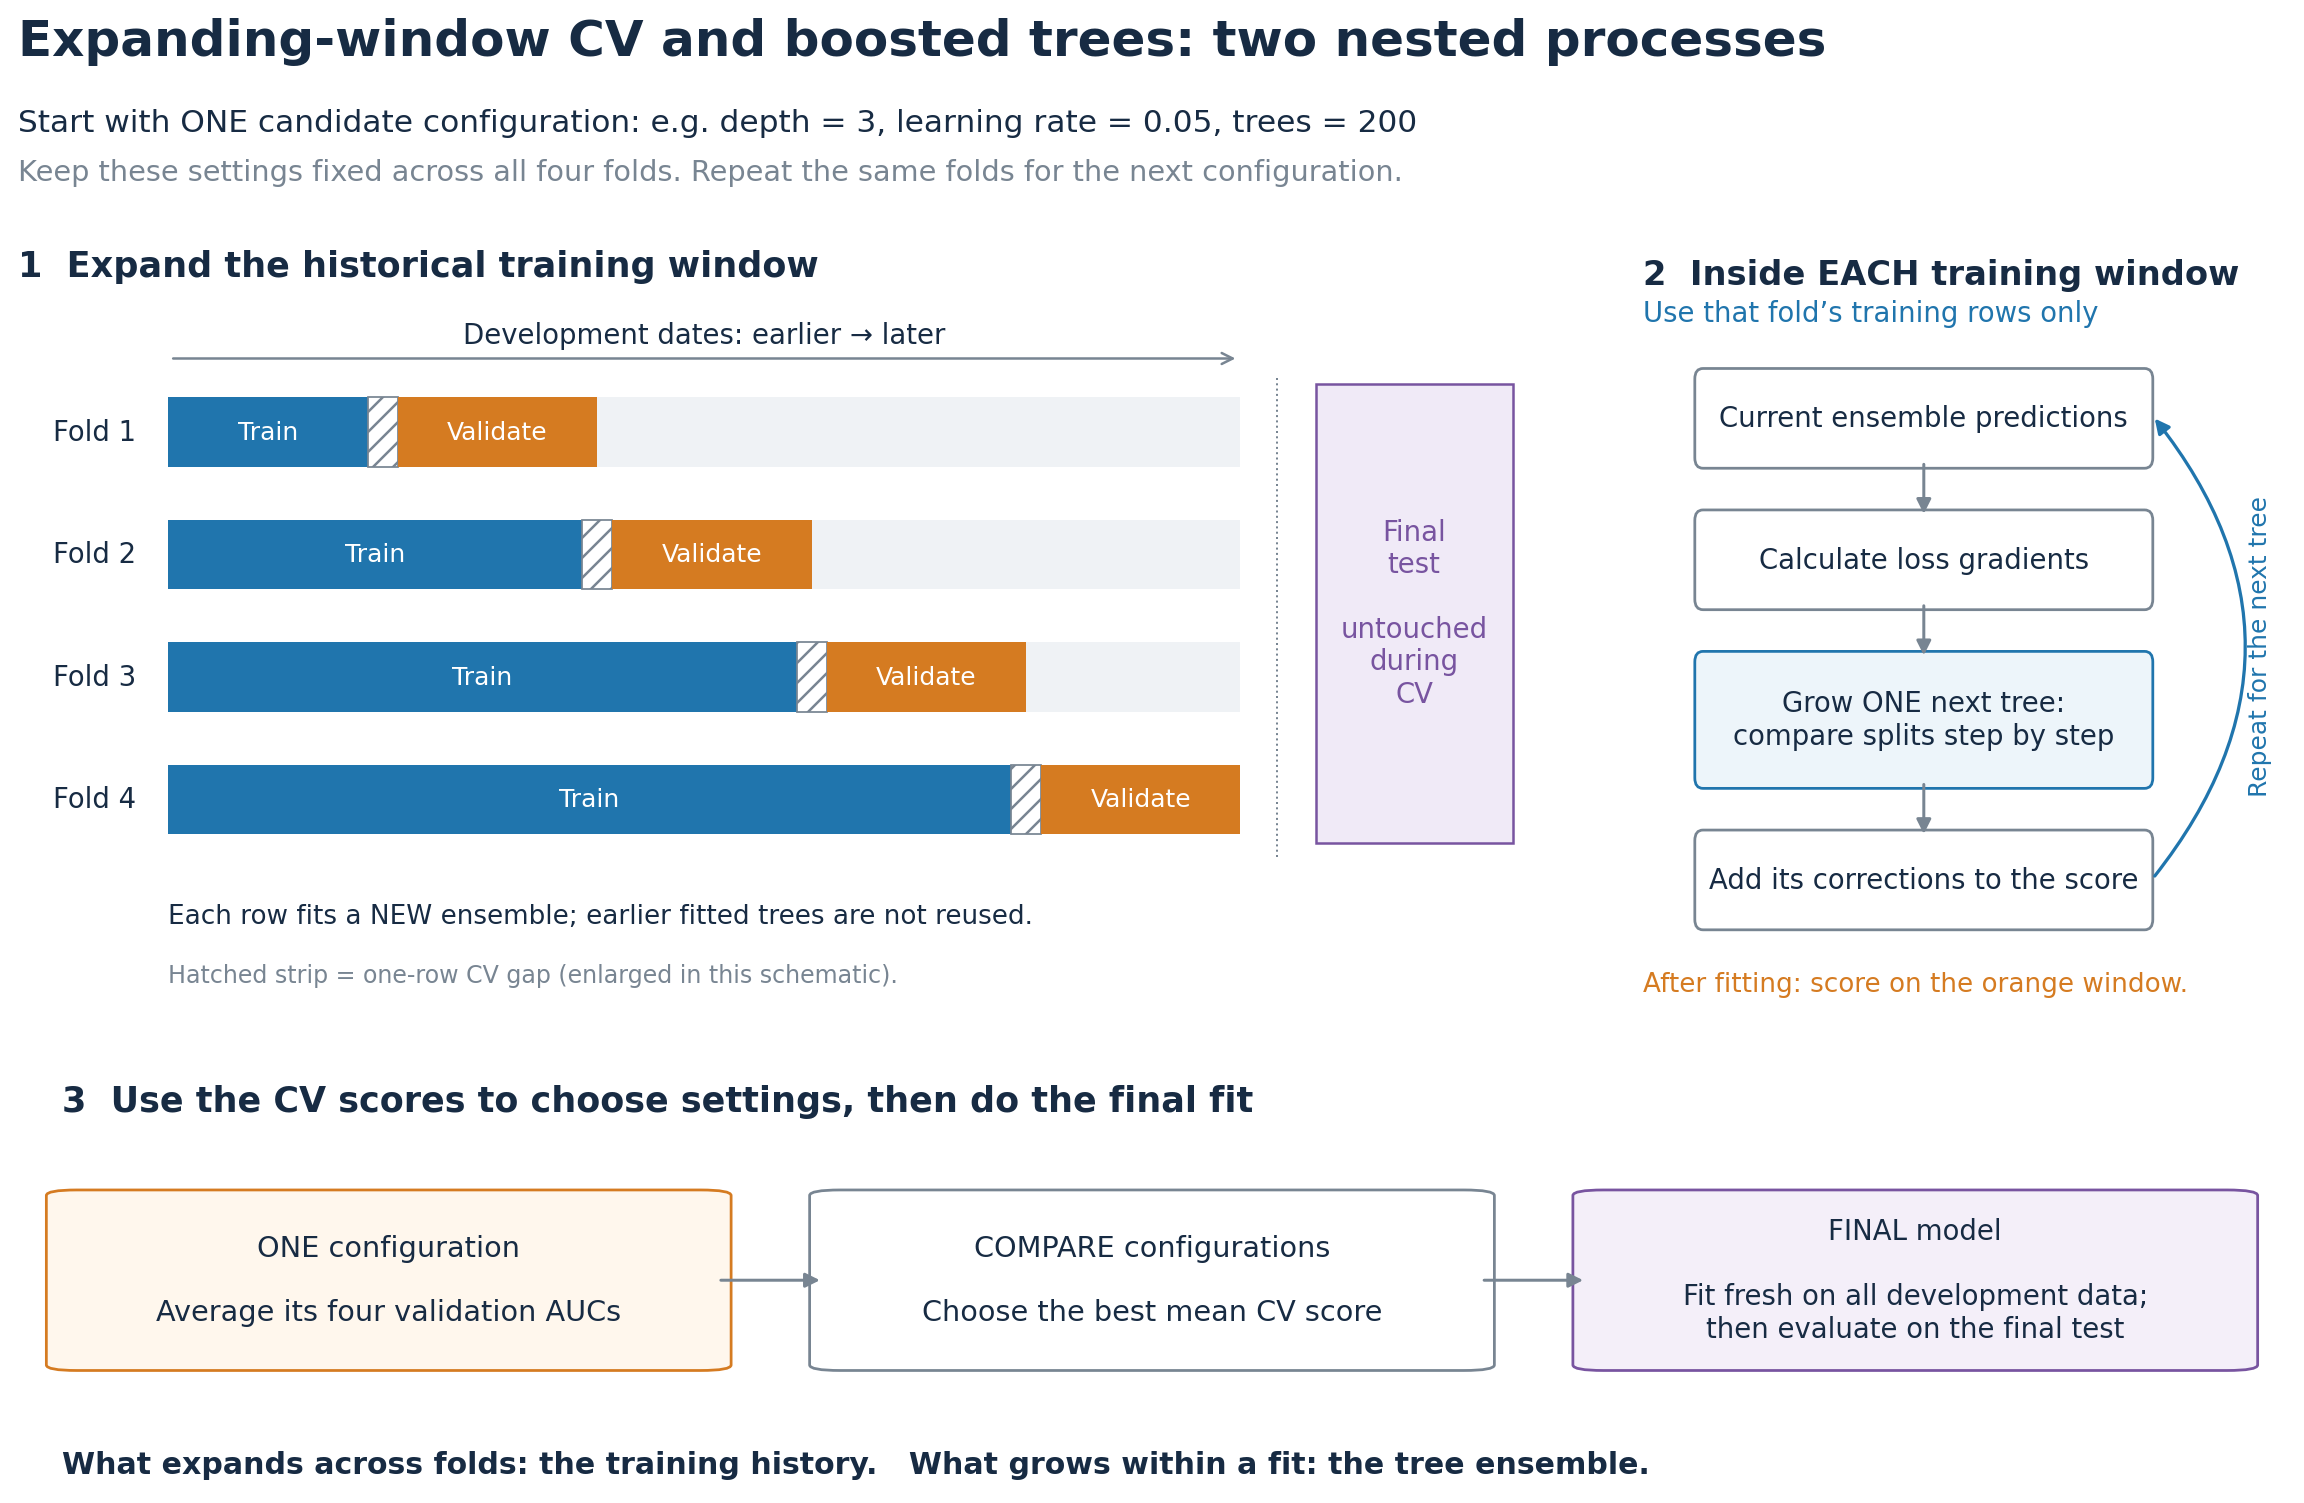

The diagram shows the idea, not the actual window sizes. Here the training windows have **572, 667, 762 and 857 rows**. Each validation window has **95 rows**, with a one-row gap. The first training/screening window is therefore about 60% of development data. “Ensemble” in the diagram means the model made from many trees.

**2. Which settings I try**

I try 24 configurations per library: the Q2(a) baseline and 23 different choices sampled from a grid. A fixed seed makes the choices repeatable. Each library gets the same number of configurations and folds, although the running times can differ. The winner is the best of the settings tested [3].

| Model | Parameters varied | Why these settings matter |
|---|---|---|
| XGBoost | Depth 2–4; minimum child Hessian 5 or 15; L1 0 or 0.1; L2 1, 5 or 20; split penalty 0 or 0.1; 100, 200 or 400 trees; learning rate 0.03 or 0.05 | Restrict depth and weakly supported splits, and control leaf corrections. Histogram search and depthwise growth stay fixed. [8] |
| LightGBM | Depth 2–4; 4, 8 or 12 leaves, restricted to at most $2^{\mathrm{depth}}$; minimum leaf observations 15, 30 or 60; L1 0 or 0.1; L2 1, 5 or 20; minimum split gain 0 or 0.1; the same tree-count and learning-rate choices | Leaf-wise growth can concentrate depth in one branch. Leaf count and minimum leaf size therefore directly control complexity; the depth limit adds another restriction. [8] |
| CatBoost | Symmetric-tree depth 2–4; L2 leaf penalty 1, 5 or 15; 1 or 10 Newton leaf-estimation steps; the same tree-count and learning-rate choices | Depth controls a symmetric tree's size. The other settings control the strength and estimation of its corrections. Ordered boosting and chronological order stay fixed. [8] |

I choose these ranges for this relatively small daily dataset. The number of trees is part of the search, so I do not add a separate validation window for early stopping. All models use binary loss without class weights, and keep the CPU/thread settings from Q2(a).

**How I interpret the selected depth**

The best tested configuration for each library uses depth two. The search included depths two, three and four, although it sampled 24 complete configurations rather than testing every possible combination. I therefore say “depth two was selected among the configurations tested”, not that it is the uniquely optimal depth.

Depth two is a reasonable complexity limit with 953 development observations, and it can work with either seven or twelve features because many trees contribute to each prediction. The seven-feature follow-up reuses the settings chosen for twelve features: it does not independently tune the best depth for seven. Weak test performance alone does not show that a deeper tree is needed; the available inputs may contain little useful signal.

**3. Which leaf gets split next?**

Both methods search for useful splits, but choose where to grow the tree differently. The following equations express the policies described in the official XGBoost `grow_policy` and LightGBM leaf-wise documentation [8].

Let $\Delta_X(v,s)$ and $\Delta_L(v,s)$ be the gains for trying split $s$ at leaf $v$, as calculated by XGBoost and LightGBM. Larger gain means a better split by that library’s criterion. Their numerical gain scales can differ.

**XGBoost: process the tree level by level**

With `depthwise`, XGBoost processes nodes near the root before deeper nodes. $\mathcal N_d$ is the set of leaves considered at depth $d$, and $\mathcal S(v)$ contains the splits allowed at leaf $v$. Each leaf finds its best split:

$$
s_v^*
=
\arg\max_{s\in\mathcal S(v)}
\Delta_X(v,s),
\qquad v\in\mathcal N_d.
$$

Here, $\Delta_X$ is the estimated drop in the regularised objective from Q2(a). The split also needs to pass limits such as maximum depth and minimum child Hessian. Some nodes may stay unsplit. Nodes on one level can ask different questions.

**LightGBM: expand the most promising available leaf**

LightGBM compares candidate splits across all current eligible leaves $\mathcal L$:

$$
(v^*,s^*)
=
\arg\max_{\substack{v\in\mathcal L\\s\in\mathcal S(v)}}
\Delta_L(v,s).
$$

So LightGBM chooses both **which leaf to expand** and **which split to use there**. One branch can grow deeper while another stays shallow. This is why leaf count and minimum leaf size are useful limits [8].

**My understanding:** I think of XGBoost’s depthwise policy as working **floor by floor**, finding the best expansion for each eligible room on that floor. LightGBM instead keeps a **priority list of available expansions** and carries out the one offering the greatest improvement next. Both search for useful splits; the difference is how they prioritise where the tree grows.

This describes our chosen settings. XGBoost can also use `lossguide`; it does not always have to grow level by level [8].

**4. CatBoost: use earlier labels to describe a category**

CatBoost’s target statistics turn categories into numbers. The following explanation comes from Prokhorenkova et al. [7, §3.2]. I adapt their equation (5) using the earlier observations specified in their “Ordered TS” discussion.

For a category such as an industry sector, we could calculate the average label among rows in that category. But using all training rows would include the current row’s own label: its input would partly contain the answer. Ordered target statistics leave out that row and use only examples earlier in the ordering.

Let $\pi_k$ identify the observation at position $k$ in an ordering $\pi$. Its ordered target statistic is

$$
\operatorname{TS}_{\pi_k}
=
\frac{
\sum_{r<k}
\mathbf1(c_{\pi_r}=c_{\pi_k})y_{\pi_r}
+a p_0
}{
\sum_{r<k}
\mathbf1(c_{\pi_r}=c_{\pi_k})
+a
},
\qquad a>0.
$$

Here:

- $c_{\pi_k}$ is the current observation’s category.
- The indicator $\mathbf1(c_{\pi_r}=c_{\pi_k})$ selects preceding observations with the same category.
- The numerator adds their labels; the denominator counts them.
- $p_0$ is a prior estimate, and $a$ controls its influence when few preceding examples are available.

**$r<k$ is the key:** only earlier examples enter the sums. The current label and later labels are left out. A fixed prior such as $p_0=0.5$ also avoids using later labels to choose the prior. This is an example of how the formula works; we do not add an encoding step for our numerical SPY features.

**My understanding:** This is like answering a question using worked examples from earlier pages while covering the current answer and the pages that follow. Earlier examples from the same category provide useful context, but the current answer must not become part of its own input.

**Ordering is not automatically calendar time**

The paper uses random permutations, so “earlier” in that ordering may still be a later calendar date. Ordered statistics stop the current label entering its own encoding. For financial look-ahead, we also need calendar order and labels that would already be known when used.

We keep calendar order with `has_time=True`. The documentation says this disables random permutations for categorical transformation and tree-structure selection [8]. The CV splits also run from earlier to later dates.

`boosting_type="Ordered"` separately turns on ordered boosting. It forms training corrections using supporting models based on earlier examples [7, §§4–5]. Ordered boosting and ordered category encoding are related, but are separate mechanisms.

All our inputs are numerical. The target-statistics formula explains the categorical mechanism asked for in the exam; it is not another transformation applied to our features.

**5. How configurations are scored and chosen**

For a configuration $\theta$, fold $k$ trains a fresh model on $T_k$ and predicts the following validation period $V_k$. Define its validation AUC as

$$
A_k(\theta)
=
\operatorname{AUC}
\left(
y_{V_k},
\hat p_{V_k}^{(k)}(\theta)
\right).
$$

The primary comparison score is the average across the four folds:

$$
\overline A(\theta)
=
\frac1K\sum_{k=1}^{K}A_k(\theta),
\qquad K=4.
$$

I also record average validation log loss and the sample standard deviation of fold AUCs:

$$
\overline L(\theta)
=
\frac1K
\sum_{k=1}^{K}
\frac1{|V_k|}
\sum_{t\in V_k}
\ell\left(y_t,\hat p_t^{(k)}(\theta)\right),
$$

$$
s_A(\theta)
=
\sqrt{
\frac{
\sum_{k=1}^{K}
\left[A_k(\theta)-\overline A(\theta)\right]^2
}{
K-1
}
}.
$$

Higher average AUC indicates better ranking of positive and negative observations. Lower log loss indicates better probability predictions. The standard deviation describes how much AUC varies between the sampled periods. The metric definitions are given in Q2(c) [3].

I choose the highest average AUC. For an exact tie, I use lower average log loss, then lower AUC standard deviation, then lower candidate number. I set these rules for this notebook.

Each fold retains the one-row boundary gap and trains from scratch. XGBoost’s starting probability is recalculated from that fold’s training labels. CatBoost and LightGBM estimate their initial constants from their own training inputs. After selecting a configuration, I fit a fresh model on all development data.

The wrapper, L1 stage and tree search all use these validation periods to make choices. After trying many choices, the winning CV scores can look optimistic. I therefore treat them as **selection scores**, rather than an independent test of the complete process.

The original twelve-feature models are assessed on a separate, later final period, which was excluded from their feature and hyperparameter choices. Reusing CV for selection does not itself mean that final-test labels entered training. The seven-feature follow-up is different: it is added after the original test was seen and is labelled exploratory. W&B records every configuration, fold score, date boundary and chosen-model file.

In [52]:
from sklearn.model_selection import ParameterGrid
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, precision_score, recall_score,
    f1_score, roc_auc_score, roc_curve, precision_recall_curve,
)

SEARCH_CONFIGURATIONS = 24  # Includes the baseline configuration.
DECISION_THRESHOLD = 0.5
AUC_TOLERANCE = 0.01
BOOTSTRAP_REPETITIONS = 1000
BOOTSTRAP_BLOCK = 10

Q2B_DIR = RESULTS_DIR / "q2b_tuning"
Q2C_DIR = RESULTS_DIR / "q2c_evaluation"
for directory in [Q2B_DIR, Q2C_DIR]:
    directory.mkdir(exist_ok=True)

parameter_spaces = {
    "XGBoost": {
        "max_depth": [2, 3, 4], "min_child_weight": [5.0, 15.0],
        "reg_alpha": [0.0, 0.1], "reg_lambda": [1.0, 5.0, 20.0],
        "gamma": [0.0, 0.1], "learning_rate": [0.03, 0.05],
        "n_estimators": [100, 200, 400],
    },
    "LightGBM": {
        "max_depth": [2, 3, 4], "num_leaves": [4, 8, 12],
        "min_child_samples": [15, 30, 60], "reg_alpha": [0.0, 0.1],
        "reg_lambda": [1.0, 5.0, 20.0], "min_split_gain": [0.0, 0.1],
        "learning_rate": [0.03, 0.05], "n_estimators": [100, 200, 400],
    },
    "CatBoost": {
        "depth": [2, 3, 4], "l2_leaf_reg": [1.0, 5.0, 15.0],
        "leaf_estimation_iterations": [1, 10],
        "learning_rate": [0.03, 0.05], "iterations": [100, 200, 400],
    },
}


def make_booster(name, changes, positive_fraction):
    """Create a fresh model; derive its initial probability from this fit only."""
    parameters = baseline_params[name].copy()
    parameters.update(changes)
    if name == "XGBoost":
        parameters["base_score"] = float(positive_fraction)
        return XGBClassifier(**parameters)
    if name == "LightGBM":
        return lgb.LGBMClassifier(**parameters)
    return CatBoostClassifier(**parameters)


search_candidates = {}
for model_number, (name, space) in enumerate(parameter_spaces.items()):
    baseline_choice = {key: baseline_params[name][key] for key in space}
    pool = [
        candidate for candidate in ParameterGrid(space)
        if candidate != baseline_choice
        and (name != "LightGBM" or candidate["num_leaves"] <= 2 ** candidate["max_depth"])
    ]
    generator = np.random.default_rng(RANDOM_SEED + model_number)
    indices = generator.choice(len(pool), size=SEARCH_CONFIGURATIONS - 1, replace=False)
    search_candidates[name] = [baseline_choice] + [pool[int(i)] for i in indices]


def log_frame(run, key, frame):
    """Keep numerical columns numerical and represent missing table entries as None."""
    clean = frame.reset_index(drop=True).astype(object)
    clean = clean.where(pd.notna(clean), None)
    run.log({key: wandb.Table(dataframe=clean)})


def link_part_a(run):
    run.use_artifact(DATASET_ARTIFACT_REF, type="dataset")
    run.use_artifact(FEATURE_DATA_ARTIFACT_REF, type="dataset")
    run.use_artifact(SELECTION_ARTIFACT_REF, type="feature-selection")


def save_native_model(name, model, directory):
    if name == "XGBoost":
        path = directory / "xgboost_tuned.json"
        model.save_model(str(path))
    elif name == "LightGBM":
        path = directory / "lightgbm_tuned.txt"
        model.booster_.save_model(str(path))
    else:
        path = directory / "catboost_tuned.cbm"
        model.save_model(str(path))
    return path


comparison_policy = {
    "classification_threshold": DECISION_THRESHOLD,
    "auc_tolerance": AUC_TOLERANCE,
    "recommendation_rule": (
        "Report the highest observed final-test AUC; inspect the AUC shortlist, "
        "CV variation, log loss and classification-error rates."
    ),
    "scope": "Retrospective classifier comparison; optional portfolio add-on not attempted",
    "financial_risk_status": "Not measured: no execution backtest or risk-adjusted-return ranking",
}

# Save all candidate parameters before fitting or inspecting final-test results.
(Q2B_DIR / "search_design.json").write_text(json.dumps({
    "seed": RANDOM_SEED, "candidates": search_candidates,
    "cv_boundaries": fold_table.to_dict(orient="records"),
    "feature_columns": list(X_train_selected.columns),
    "comparison_policy": comparison_policy,
}, indent=2), encoding="utf-8")
display(fold_table)
print("Configurations per library:", {name: len(c) for name, c in search_candidates.items()})


,fold,train_start,train_end,validation_start,validation_end,train_rows,validation_rows,gap_rows
0,1,2021-12-28,2024-04-08,2024-04-10,2024-08-23,572,95,1
1,2,2021-12-28,2024-08-22,2024-08-26,2025-01-10,667,95,1
2,3,2021-12-28,2025-01-08,2025-01-13,2025-05-29,762,95,1
3,4,2021-12-28,2025-05-28,2025-05-30,2025-10-14,857,95,1


Configurations per library: {'XGBoost': 24, 'LightGBM': 24, 'CatBoost': 24}


**Code — fit fresh models in each fold, choose settings, then refit**

The loop reports one line per configuration. W&B receives one search run per library, including the complete candidate and fold tables. The chosen models remain in `tuned_models`.

In [53]:
tuned_models = {}
BEST_PARAMS = {}
TUNED_MODEL_ARTIFACT_REFS = {}
chosen_oof_probabilities = {}
search_result_frames = []
fold_result_frames = []
chosen_rows = []

for name, candidates in search_candidates.items():
    search_config = {
        "stage": "Q2b_chronological_tuning", "model": name,
        "random_seed": RANDOM_SEED, "package_versions": boosting_package_versions,
        "baseline_parameters": baseline_params[name], "search_candidates": candidates,
        "folds": fold_table.to_dict(orient="records"),
        "feature_columns": list(X_train_selected.columns),
        "selection_score": "mean validation ROC-AUC; log loss then std for exact ties",
        "comparison_policy": comparison_policy,
        "feature_dataset_artifact": FEATURE_DATA_ARTIFACT_REF,
        "selection_artifact": SELECTION_ARTIFACT_REF,
        "final_test_status": "not evaluated",
    }
    with wandb.init(
        project=WANDB_PROJECT, entity=WANDB_ENTITY,
        job_type="model-tuning", name=f"q2b-{name.lower()}-search", config=search_config,
    ) as tuning_run:
        link_part_a(tuning_run)
        candidate_rows, fold_rows, candidate_oof = [], [], {}

        for candidate_id, changes in enumerate(candidates):
            aucs, losses, fit_times = [], [], []
            oof = pd.Series(np.nan, index=X_train_selected.index, name=name)

            for fold, (train_idx, validation_idx) in enumerate(cv_splits, start=1):
                X_fit = X_train_selected.iloc[train_idx]
                y_fit = y_train.iloc[train_idx]
                X_validation = X_train_selected.iloc[validation_idx]
                y_validation = y_train.iloc[validation_idx]
                model = make_booster(name, changes, y_fit.mean())

                started = perf_counter()
                model.fit(X_fit, y_fit)
                fit_time = perf_counter() - started
                probabilities = model.predict_proba(X_validation)[:, 1]
                auc = roc_auc_score(y_validation, probabilities)
                loss = log_loss(y_validation, probabilities, labels=[0, 1])
                aucs.append(float(auc))
                losses.append(float(loss))
                fit_times.append(fit_time)
                oof.iloc[validation_idx] = probabilities
                fold_rows.append({
                    "model": name, "candidate": candidate_id, "fold": fold,
                    "roc_auc": float(auc), "log_loss": float(loss), "fit_seconds": fit_time,
                    "initial_positive_fraction": float(y_fit.mean()),
                    **fold_table.iloc[fold - 1].to_dict(),
                    "parameters_json": json.dumps(changes, sort_keys=True),
                })

            row = {
                "model": name, "candidate": candidate_id,
                "mean_cv_auc": float(np.mean(aucs)),
                "std_cv_auc": float(np.std(aucs, ddof=1)),
                "mean_cv_log_loss": float(np.mean(losses)),
                "mean_fold_fit_seconds": float(np.mean(fit_times)),
                "parameters_json": json.dumps(changes, sort_keys=True),
            }
            candidate_rows.append(row)
            candidate_oof[candidate_id] = oof
            tuning_run.log({
                "candidate": candidate_id, "cv/mean_auc": row["mean_cv_auc"],
                "cv/std_auc": row["std_cv_auc"],
                "cv/mean_log_loss": row["mean_cv_log_loss"],
            })
            print(f"{name} {candidate_id + 1}/{len(candidates)}: CV AUC={row['mean_cv_auc']:.4f}")

        search_table = pd.DataFrame(candidate_rows)
        fold_results = pd.DataFrame(fold_rows)
        ranking = search_table.sort_values(
            ["mean_cv_auc", "mean_cv_log_loss", "std_cv_auc", "candidate"],
            ascending=[False, True, True, True],
        )
        chosen = ranking.iloc[0]
        chosen_id = int(chosen["candidate"])
        BEST_PARAMS[name] = candidates[chosen_id]
        chosen_oof_probabilities[name] = candidate_oof[chosen_id]

        # This is a new fit on all development data, after choosing the configuration.
        model = make_booster(name, BEST_PARAMS[name], y_train.mean())
        started = perf_counter()
        model.fit(X_train_selected, y_train)
        refit_seconds = perf_counter() - started
        tuned_models[name] = model
        model_file = save_native_model(name, model, Q2B_DIR)

        chosen_row = {
            **chosen.to_dict(), "refit_seconds": refit_seconds,
            "baseline_cv_auc": float(search_table.iloc[0]["mean_cv_auc"]),
            "model_file": str(model_file),
        }
        chosen_rows.append(chosen_row)
        search_result_frames.append(search_table)
        fold_result_frames.append(fold_results)
        search_file = Q2B_DIR / f"{name.lower()}_search.csv"
        folds_file = Q2B_DIR / f"{name.lower()}_fold_scores.csv"
        oof_file = Q2B_DIR / f"{name.lower()}_chosen_oof.csv"
        search_table.to_csv(search_file, index=False)
        fold_results.to_csv(folds_file, index=False)
        chosen_oof_probabilities[name].dropna().to_csv(oof_file, index_label="Date")
        metadata = {
            **search_config, "chosen_parameters": BEST_PARAMS[name],
            "chosen_candidate": chosen_id, "chosen_results": chosen_row,
            "training_start": str(X_train_selected.index.min().date()),
            "training_end": str(X_train_selected.index.max().date()),
            "initial_positive_fraction": float(y_train.mean()),
        }
        metadata_file = Q2B_DIR / f"{name.lower()}_chosen_metadata.json"
        metadata_file.write_text(json.dumps(metadata, indent=2), encoding="utf-8")
        log_frame(tuning_run, "candidate_scores", search_table)
        log_frame(tuning_run, "fold_scores", fold_results)
        tuning_run.summary.update({
            "chosen_candidate": chosen_id, "chosen_cv_auc": chosen_row["mean_cv_auc"],
            "chosen_cv_log_loss": chosen_row["mean_cv_log_loss"],
            "chosen_cv_auc_std": chosen_row["std_cv_auc"], "refit_seconds": refit_seconds,
        })
        artifact = wandb.Artifact(f"spy-{name.lower()}-tuned", type="model", metadata=metadata)
        for file in [model_file, metadata_file, search_file, folds_file, oof_file,
                     Q2B_DIR / "search_design.json"]:
            artifact.add_file(str(file))
        logged = tuning_run.log_artifact(artifact)
        logged.wait()
        TUNED_MODEL_ARTIFACT_REFS[name] = (
            f"{tuning_run.entity}/{tuning_run.project}/spy-{name.lower()}-tuned:{logged.version}"
        )
        tuning_run.summary["model_artifact"] = TUNED_MODEL_ARTIFACT_REFS[name]

cv_search_results = pd.concat(search_result_frames, ignore_index=True)
cv_fold_results = pd.concat(fold_result_frames, ignore_index=True)
best_summary = pd.DataFrame(chosen_rows).set_index("model")
cv_search_results.to_csv(Q2B_DIR / "all_search_scores.csv", index=False)
cv_fold_results.to_csv(Q2B_DIR / "all_fold_scores.csv", index=False)
best_summary.to_csv(Q2B_DIR / "chosen_configurations.csv")
display(best_summary[["candidate", "mean_cv_auc", "std_cv_auc", "mean_cv_log_loss", "baseline_cv_auc", "refit_seconds"]])
display(pd.DataFrame(BEST_PARAMS).T)

b_lines = [
    "**Q2(b) — results from this run**",
    f"Each library was compared using {SEARCH_CONFIGURATIONS} configurations and {len(cv_splits)} chronological folds.",
]
for name, row in best_summary.iterrows():
    b_lines.append(
        f"- **{name}:** candidate {int(row['candidate'])}, mean CV AUC {row['mean_cv_auc']:.4f}, "
        f"fold standard deviation {row['std_cv_auc']:.4f}, mean log loss {row['mean_cv_log_loss']:.4f}. "
        f"The baseline AUC was {row['baseline_cv_auc']:.4f}. Chosen settings: `{BEST_PARAMS[name]}`."
    )
b_lines.append("These scores guided selection; independent final-period benchmarking follows in Q2(c).")
Q2B_INTERPRETATION = "\n\n".join(b_lines)
(Q2B_DIR / "tuning_interpretation.md").write_text(Q2B_INTERPRETATION, encoding="utf-8")
display(Markdown(Q2B_INTERPRETATION))


XGBoost 1/24: CV AUC=0.5172
XGBoost 2/24: CV AUC=0.5392
XGBoost 3/24: CV AUC=0.5495
XGBoost 4/24: CV AUC=0.5160
XGBoost 5/24: CV AUC=0.5196
XGBoost 6/24: CV AUC=0.5145
XGBoost 7/24: CV AUC=0.5065
XGBoost 8/24: CV AUC=0.5337
XGBoost 9/24: CV AUC=0.5286
XGBoost 10/24: CV AUC=0.5410
XGBoost 11/24: CV AUC=0.5070
XGBoost 12/24: CV AUC=0.5158
XGBoost 13/24: CV AUC=0.5329
XGBoost 14/24: CV AUC=0.5503
XGBoost 15/24: CV AUC=0.5404
XGBoost 16/24: CV AUC=0.5115
XGBoost 17/24: CV AUC=0.4947
XGBoost 18/24: CV AUC=0.5189
XGBoost 19/24: CV AUC=0.5213
XGBoost 20/24: CV AUC=0.5130
XGBoost 21/24: CV AUC=0.5189
XGBoost 22/24: CV AUC=0.5435
XGBoost 23/24: CV AUC=0.5286
XGBoost 24/24: CV AUC=0.5122


LightGBM 1/24: CV AUC=0.5184
LightGBM 2/24: CV AUC=0.5347
LightGBM 3/24: CV AUC=0.5014
LightGBM 4/24: CV AUC=0.5172
LightGBM 5/24: CV AUC=0.5248
LightGBM 6/24: CV AUC=0.5097
LightGBM 7/24: CV AUC=0.5158
LightGBM 8/24: CV AUC=0.5150
LightGBM 9/24: CV AUC=0.5052
LightGBM 10/24: CV AUC=0.5145
LightGBM 11/24: CV AUC=0.4905
LightGBM 12/24: CV AUC=0.5060
LightGBM 13/24: CV AUC=0.5244
LightGBM 14/24: CV AUC=0.5099
LightGBM 15/24: CV AUC=0.5068
LightGBM 16/24: CV AUC=0.5235
LightGBM 17/24: CV AUC=0.5150
LightGBM 18/24: CV AUC=0.5119
LightGBM 19/24: CV AUC=0.5158
LightGBM 20/24: CV AUC=0.5259
LightGBM 21/24: CV AUC=0.5135
LightGBM 22/24: CV AUC=0.4977
LightGBM 23/24: CV AUC=0.5330
LightGBM 24/24: CV AUC=0.5037


CatBoost 1/24: CV AUC=0.5124
CatBoost 2/24: CV AUC=0.4836
CatBoost 3/24: CV AUC=0.5112
CatBoost 4/24: CV AUC=0.5278
CatBoost 5/24: CV AUC=0.4835
CatBoost 6/24: CV AUC=0.4844
CatBoost 7/24: CV AUC=0.4703
CatBoost 8/24: CV AUC=0.5165
CatBoost 9/24: CV AUC=0.4884
CatBoost 10/24: CV AUC=0.5152
CatBoost 11/24: CV AUC=0.5035
CatBoost 12/24: CV AUC=0.5080
CatBoost 13/24: CV AUC=0.5113
CatBoost 14/24: CV AUC=0.4904
CatBoost 15/24: CV AUC=0.4934
CatBoost 16/24: CV AUC=0.4740
CatBoost 17/24: CV AUC=0.4586
CatBoost 18/24: CV AUC=0.5010
CatBoost 19/24: CV AUC=0.5242
CatBoost 20/24: CV AUC=0.5261
CatBoost 21/24: CV AUC=0.5014
CatBoost 22/24: CV AUC=0.4997
CatBoost 23/24: CV AUC=0.5052
CatBoost 24/24: CV AUC=0.4952


,candidate,mean_cv_auc,std_cv_auc,mean_cv_log_loss,baseline_cv_auc,refit_seconds
model,,,,,,
XGBoost,13,0.550310,0.039114,0.706149,0.517234,0.158684
LightGBM,1,0.534744,0.027018,0.712266,0.518402,0.075224
CatBoost,3,0.527778,0.080660,0.700954,0.512369,0.542776


,gamma,learning_rate,max_depth,min_child_weight,n_estimators,reg_alpha,reg_lambda,min_child_samples,min_split_gain,num_leaves,depth,iterations,l2_leaf_reg,leaf_estimation_iterations
XGBoost,0.1,0.05,2.0,15.0,400.0,0.1,20.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
LightGBM,NaN,0.05,2.0,NaN,400.0,0.0,20.0,60.0,0.1,4.0,NaN,NaN,NaN,NaN
CatBoost,NaN,0.03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,200.0,15.0,10.0


**Q2(b) — results from this run**

Each library was compared using 24 configurations and 4 chronological folds.

- **XGBoost:** candidate 13, mean CV AUC 0.5503, fold standard deviation 0.0391, mean log loss 0.7061. The baseline AUC was 0.5172. Chosen settings: `{'gamma': 0.1, 'learning_rate': 0.05, 'max_depth': 2, 'min_child_weight': 15.0, 'n_estimators': 400, 'reg_alpha': 0.1, 'reg_lambda': 20.0}`.

- **LightGBM:** candidate 1, mean CV AUC 0.5347, fold standard deviation 0.0270, mean log loss 0.7123. The baseline AUC was 0.5184. Chosen settings: `{'learning_rate': 0.05, 'max_depth': 2, 'min_child_samples': 60, 'min_split_gain': 0.1, 'n_estimators': 400, 'num_leaves': 4, 'reg_alpha': 0.0, 'reg_lambda': 20.0}`.

- **CatBoost:** candidate 3, mean CV AUC 0.5278, fold standard deviation 0.0807, mean log loss 0.7010. The baseline AUC was 0.5124. Chosen settings: `{'depth': 2, 'iterations': 200, 'l2_leaf_reg': 15.0, 'leaf_estimation_iterations': 10, 'learning_rate': 0.03}`.

These scores guided selection; independent final-period benchmarking follows in Q2(c).

**Check the probability scores against a simple benchmark**

In the saved SPY run, the constant benchmark's mean CV log loss is about 0.6970. The selected tree configurations give:

| Model | Mean CV AUC | Mean CV log loss |
|---|---:|---:|
| Constant benchmark | 0.5000 | 0.6970 |
| XGBoost | 0.5503 | 0.7061 |
| LightGBM | 0.5347 | 0.7123 |
| CatBoost | 0.5278 | 0.7010 |

All three have higher observed average AUC than the constant model, but worse log loss. This is possible because the search chooses primarily by AUC: ranking and probability quality are different. The more complicated models have not beaten the simple benchmark on this probability score. This is a result to report, rather than a reason to change the scoring rule after seeing it.

The constant model learns each fold's training proportion of label 1; it is not a separate financial pricing formula. A simple benchmark can outperform a more flexible ML model. The code below calculates the comparison from the current run. Its log-loss improvement uses the same sign convention as Q2(c): positive means lower loss.

In [54]:
# Compare every selected tree configuration with the same fold-wise constant benchmark.
cv_probability_rows = [{
    "model": "Constant benchmark", "mean_cv_auc": 0.5,
    "mean_cv_log_loss": baseline_cv_loss,
    "cv_log_loss_improvement": 0.0,
}]
for name, row in best_summary.iterrows():
    cv_probability_rows.append({
        "model": name, "mean_cv_auc": float(row["mean_cv_auc"]),
        "mean_cv_log_loss": float(row["mean_cv_log_loss"]),
        "cv_log_loss_improvement": baseline_cv_loss - float(row["mean_cv_log_loss"]),
    })

cv_probability_check = pd.DataFrame(cv_probability_rows).set_index("model")
cv_probability_check.to_csv(Q2B_DIR / "cv_probability_benchmark.csv")
display(cv_probability_check)

better_loss_count = int(
    (cv_probability_check.loc[list(tuned_models), "cv_log_loss_improvement"] > 0).sum()
)
display(Markdown(
    f"**CV probability check:** {better_loss_count} of {len(tuned_models)} selected tree "
    f"configurations have lower average log loss than the constant benchmark "
    f"({baseline_cv_loss:.4f}). A positive improvement means lower loss. "
    "The search selected primarily by AUC, so improved ranking need not come with "
    "improved probability scores."
))


,mean_cv_auc,mean_cv_log_loss,cv_log_loss_improvement
model,,,
Constant benchmark,0.500000,0.696953,0.000000
XGBoost,0.550310,0.706149,-0.009195
LightGBM,0.534744,0.712266,-0.015313
CatBoost,0.527778,0.700954,-0.004001


**CV probability check:** 0 of 3 selected tree configurations have lower average log loss than the constant benchmark (0.6970). A positive improvement means lower loss. The search selected primarily by AUC, so improved ranking need not come with improved probability scores.

#### (c)

Evaluate and compare the prediction quality of all three frameworks. Your analysis must include out-of-sample benchmarking utilizing the Area Under the Receiver Operating Characteristic (ROC-AUC) curve, Confusion Matrices (analyzing Precision-Recall trade-offs for trading execution), and comprehensive Classification Reports. Formally write out the mathematical definitions for all performance metrics used.

Provide a definitive, data-driven recommendation on which specific algorithm is best suited for this predictive task, balancing statistical predictive power, operational stability, and risk metrics.

**Answer — compare predictions on the reserved final period**

**1. Test the fitted models**

Q2(b) chose settings and fitted each model again on development data. I now use those models on the same final test dates. The constant benchmark always predicts the fraction of development labels equal to $1$. At threshold $0.5$, it always predicts the development-majority class.

All models use the same selected feature order. I make one set of probability predictions per model and retain them for all classification metrics and plots. Final-test results are not fed back into feature selection, hyperparameter tuning or threshold choice.

**2. Turn probabilities into labels, then count errors**

Using the fixed threshold $\tau=0.5$,

$$\hat y_t=\mathbf1(\hat p_t\ge\tau).$$

With $TP,TN,FP,FN$ denoting true positives, true negatives, false positives and false negatives, the confusion matrix has actual labels in rows and predicted labels in columns:

$$C=\begin{pmatrix}TN&FP\\FN&TP\end{pmatrix}.$$

The reported metrics are [3]

$$
\operatorname{Accuracy}=\frac{TP+TN}{N},\qquad
\operatorname{Precision}=\frac{TP}{TP+FP},\qquad
\operatorname{Recall}=\operatorname{TPR}=\frac{TP}{TP+FN},
$$

$$
\operatorname{Specificity}=\frac{TN}{TN+FP},\qquad
\operatorname{FPR}=\frac{FP}{FP+TN},\qquad
\operatorname{FNR}=\frac{FN}{FN+TP},\qquad
F_1=\frac{2TP}{2TP+FP+FN},
$$

$$\operatorname{BalancedAccuracy}=\frac{\operatorname{Recall}+\operatorname{Specificity}}2.$$

I also report the positive-signal fraction $(TP+FP)/N$ and the actual positive-label fraction $(TP+FN)/N$. FPR and FNR measure false alarms and missed positive events; they do not measure the size of financial losses.

Precision asks how many positive signals correspond to our positive-move label. Recall asks how many such events we identify. A stricter threshold usually trades fewer signals for higher precision and lower recall, although precision need not improve monotonically in a finite sample. I show the precision–recall curve to inspect this trade-off while keeping the implemented threshold fixed.

Label $0$ also contains small positive returns below the cutoff. Therefore, a false-positive classification is not necessarily a losing trade, and classification precision is not the strategy's realised win rate.

**3. Compare probability ranking and probability loss**

The ROC curve plots TPR against FPR as the threshold varies. AUC can be written as the fraction of positive–negative pairs ranked correctly, with half credit for ties:

$$
\operatorname{AUC}=\frac1{N_1N_0}
\sum_{i:y_i=1}\sum_{j:y_j=0}
\left[\mathbf1(\hat p_i>\hat p_j)+\tfrac12\mathbf1(\hat p_i=\hat p_j)\right].
$$

An AUC of $0.5$ corresponds to chance-level ranking. AUC is not the proportion of correct predicted labels. For example, probabilities 0.1 for an actual 0 and 0.4 for an actual 1 give perfect ranking, but only 50% accuracy at threshold 0.5. AUC does not assess whether probability values themselves are accurate, so I also report average log loss:

$$\operatorname{LogLoss}=-\frac1N\sum_t\left[y_t\log\hat p_t+(1-y_t)\log(1-\hat p_t)\right].$$

Higher AUC and lower log loss are preferable. I compare both against the constant-probability benchmark, rather than judging classification accuracy alone. The reported log-loss improvement is

$$
\Delta_{\mathrm{LL}}=\operatorname{LogLoss}_{\mathrm{constant}}-\operatorname{LogLoss}_{\mathrm{model}}.
$$

A positive value means the model has lower loss than the constant benchmark; a negative value means it has higher loss.

**4. Classification reports and uncertainty**

For each class $c$, its support $n_c$ is its actual observation count. Precision, recall and F1 are calculated by treating that class as positive. For any class-wise metric $m_c$, the report includes

$$\operatorname{Macro}(m)=\frac12\sum_{c=0}^{1}m_c,\qquad
\operatorname{Weighted}(m)=\sum_{c=0}^{1}\frac{n_c}{N}m_c.$$

When a precision/recall/F1 denominator is zero, the code reports zero using `zero_division=0`. The report therefore remains readable when a model produces no signals for a class.

I estimate an AUC interval with 1,000 moving-block bootstrap samples of the saved predictions and their actual labels. For each sample, the code draws consecutive blocks of 10 observations, joins them and cuts the result to the original test length. The 2.5th and 97.5th percentiles give the interval [9]. Keeping blocks preserves some short-term dependence. This checks uncertainty for these fitted models; it does not repeat feature selection or tuning. The 10-row block length is a fixed choice, and block resampling still assumes enough stability in the data.

**5. How I compare the models**

I compare test AUC, log loss, classification errors, variation across CV folds and fitting/prediction times. Fold variation tells us how much performance changes across these periods. For the timings,

$$
T_{\mathrm{fit}}=t_{\mathrm{fit,end}}-t_{\mathrm{fit,start}},\qquad
T_{\mathrm{predict}}=t_{\mathrm{predict,end}}-t_{\mathrm{predict,start}}.
$$

The code measures elapsed seconds with `perf_counter()`. Fitting times exclude saving files and W&B uploads. Prediction times cover the probability prediction call and storing its result. These measurements describe this machine and workload.

The original rule groups models within $0.01$ of the highest test AUC. Only CatBoost falls in that group here. I then discuss its probability loss, CV variation and error rates. The optional portfolio add-on is omitted, so there are no Sharpe or drawdown results to use as tie-breaks.

The models and threshold are fixed before testing. However, I use these test results to recommend one library, so a later unused period would be needed to check that choice again. The risk measures here count wrong or missed signals; they do not measure financial losses.

In [55]:
# Hyperparameters and threshold are fixed before this first final-test evaluation.
test_probabilities = pd.DataFrame(index=X_test_selected.index)
test_probabilities.index.name = "Date"
prediction_times = {}
for name, model in tuned_models.items():
    started = perf_counter()
    test_probabilities[name] = model.predict_proba(X_test_selected)[:, 1]
    prediction_times[name] = perf_counter() - started
test_probabilities["Constant benchmark"] = float(y_train.mean())

test_labels = (test_probabilities >= DECISION_THRESHOLD).astype(int)
test_predictions = test_probabilities.add_suffix("_probability").join(
    test_labels.add_suffix("_predicted_label")
)
test_predictions.insert(0, "actual_label", y_test)
test_predictions.insert(1, "target_date", df_model.loc[X_test_selected.index, "target_date"])
test_predictions.to_csv(Q2C_DIR / "final_test_predictions.csv", index_label="Date")


def auc_block_interval(actual, probabilities, repetitions, block_length, seed):
    """Resample consecutive blocks of the already frozen test predictions."""
    actual = np.asarray(actual)
    probabilities = np.asarray(probabilities)
    n = len(actual)
    width = min(block_length, n)
    generator = np.random.default_rng(seed)
    estimates = []
    for _ in range(repetitions):
        starts = generator.integers(0, n - width + 1, size=int(np.ceil(n / width)))
        sample = np.concatenate([np.arange(start, start + width) for start in starts])[:n]
        if np.unique(actual[sample]).size == 2:
            estimates.append(roc_auc_score(actual[sample], probabilities[sample]))
    return np.quantile(estimates, [0.025, 0.975]) if estimates else np.array([np.nan, np.nan])


def classification_report_frame(report):
    # Accuracy is a single score, not a precision/recall/support row.
    return pd.DataFrame({
        name: metrics for name, metrics in report.items()
        if isinstance(metrics, dict)
    }).T


metric_rows = []
classification_reports = {}
confusion_matrices = {}
for name in test_probabilities:
    probabilities = test_probabilities[name].to_numpy()
    predicted = test_labels[name].to_numpy()
    tn, fp, fn, tp = confusion_matrix(y_test, predicted, labels=[0, 1]).ravel()
    lower, upper = auc_block_interval(
        y_test, probabilities, BOOTSTRAP_REPETITIONS, BOOTSTRAP_BLOCK, RANDOM_SEED,
    )
    metric_rows.append({
        "model": name, "roc_auc": roc_auc_score(y_test, probabilities),
        "auc_lower_95": float(lower), "auc_upper_95": float(upper),
        "log_loss": log_loss(y_test, probabilities, labels=[0, 1]),
        "accuracy": accuracy_score(y_test, predicted),
        "balanced_accuracy": balanced_accuracy_score(y_test, predicted),
        "precision": precision_score(y_test, predicted, zero_division=0),
        "recall": recall_score(y_test, predicted, zero_division=0),
        "f1": f1_score(y_test, predicted, zero_division=0),
        "specificity": tn / (tn + fp), "false_positive_rate": fp / (fp + tn),
        "false_negative_rate": fn / (fn + tp),
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
        "predicted_positive_fraction": float(predicted.mean()),
        "prediction_seconds": prediction_times.get(name, np.nan),
    })
    report = classification_report(
        y_test, predicted, labels=[0, 1],
        target_names=["0: other move", "1: positive event"],
        output_dict=True, zero_division=0,
    )
    classification_reports[name] = report
    confusion_matrices[name] = confusion_matrix(y_test, predicted, labels=[0, 1])
    report_table = classification_report_frame(report)
    report_table.to_csv(Q2C_DIR / f"{name.lower().replace(' ', '_')}_classification_report.csv")
    display(Markdown(
        f"**{name} — classification report**\n\n"
        f"Accuracy: **{report['accuracy']:.4f}**."
    ))
    display(report_table)

test_comparison = pd.DataFrame(metric_rows).set_index("model")
test_comparison = test_comparison.join(best_summary[[
    "mean_cv_auc", "std_cv_auc", "mean_cv_log_loss", "refit_seconds",
]])
test_comparison.to_csv(Q2C_DIR / "final_test_comparison.csv")
(Q2C_DIR / "classification_reports.json").write_text(
    json.dumps(classification_reports, indent=2), encoding="utf-8",
)
display(test_comparison[[
    "roc_auc", "auc_lower_95", "auc_upper_95", "log_loss", "precision", "recall",
    "f1", "balanced_accuracy", "std_cv_auc", "refit_seconds", "prediction_seconds",
]])

classification_risk = test_comparison.loc[list(tuned_models), [
    "false_positive_rate", "false_negative_rate", "predicted_positive_fraction",
]]
classification_risk.to_csv(Q2C_DIR / "classification_error_risk.csv")
display(classification_risk)

# This names a relative classification winner, not a profitable trading strategy.
RECOMMENDED_MODEL = test_comparison.loc[list(tuned_models), "roc_auc"].idxmax()
recommended = test_comparison.loc[RECOMMENDED_MODEL]
auc_shortlist = test_comparison.loc[list(tuned_models)]
auc_shortlist = auc_shortlist[
    auc_shortlist["roc_auc"] >= recommended["roc_auc"] - AUC_TOLERANCE
]

c_lines = [
    "**Q2(c) — final-period classification results**",
    f"The frozen models were evaluated on {len(y_test)} observations, from "
    f"{X_test_selected.index.min().date()} to {X_test_selected.index.max().date()}. "
    f"The positive-label fraction was {y_test.mean():.3f}; the fixed decision threshold was {DECISION_THRESHOLD:.2f}.",
]
benchmark_loss = test_comparison.loc["Constant benchmark", "log_loss"]
for name in tuned_models:
    row = test_comparison.loc[name]
    c_lines.append(
        f"- **{name}:** test AUC {row['roc_auc']:.4f} "
        f"(block-bootstrap interval {row['auc_lower_95']:.4f}–{row['auc_upper_95']:.4f}), "
        f"log loss {row['log_loss']:.4f}, precision {row['precision']:.3f}, recall {row['recall']:.3f}. "
        f"Its log-loss improvement over the constant benchmark was {benchmark_loss - row['log_loss']:+.4f} "
        "(positive means lower loss)."
    )
c_lines.append(
    "The plots describe ranking and threshold trade-offs. No threshold or model was retuned after these results. "
    "The recommendation below compares classifiers; no execution backtest is included."
)
c_lines.append(
    f"**Relative classifier choice: {RECOMMENDED_MODEL}.** "
    f"It has the highest observed test AUC ({recommended['roc_auc']:.4f}). "
    f"Models within {AUC_TOLERANCE:.2f} AUC of that value: {', '.join(auc_shortlist.index)}. "
    f"Its CV AUC standard deviation is {recommended['std_cv_auc']:.4f}; "
    f"false-positive rate {recommended['false_positive_rate']:.2%}; "
    f"false-negative rate {recommended['false_negative_rate']:.2%}. "
    "These are sample-based comparisons of prediction and classification-error risk. "
    "They do not establish profitability or financial risk-adjusted performance. "
    "Confirmation of the chosen architecture requires a later, unused period."
)
c_lines.append(
    "The comparison concerns complete library configurations, rather than isolating one tree-building mechanism. "
    "All inputs are numerical, so categorical Target Statistics are not used. Ordered boosting is separately enabled for CatBoost. "
    "These results alone cannot attribute a performance difference to that mechanism."
)
Q2C_INTERPRETATION = "\n\n".join(c_lines)
(Q2C_DIR / "classification_interpretation.md").write_text(Q2C_INTERPRETATION, encoding="utf-8")
display(Markdown(Q2C_INTERPRETATION))


**XGBoost — classification report**

Accuracy: **0.5230**.

,precision,recall,f1-score,support
0: other move,0.542105,0.792308,0.643750,130.0
1: positive event,0.448980,0.201835,0.278481,109.0
macro avg,0.495542,0.497071,0.461116,239.0
weighted avg,0.499634,0.523013,0.477163,239.0


**LightGBM — classification report**

Accuracy: **0.5021**.

,precision,recall,f1-score,support
0: other move,0.529101,0.769231,0.626959,130.0
1: positive event,0.400000,0.183486,0.251572,109.0
macro avg,0.464550,0.476359,0.439266,239.0
weighted avg,0.470222,0.502092,0.455758,239.0


**CatBoost — classification report**

Accuracy: **0.5523**.

...

**Constant benchmark — classification report**

Accuracy: **0.5439**.

,precision,recall,f1-score,support
0: other move,0.543933,1.000000,0.704607,130.0
1: positive event,0.000000,0.000000,0.000000,109.0
macro avg,0.271967,0.500000,0.352304,239.0
weighted avg,0.295863,0.543933,0.383259,239.0


,roc_auc,auc_lower_95,auc_upper_95,log_loss,precision,recall,f1,balanced_accuracy,std_cv_auc,refit_seconds,prediction_seconds
model,,,,,,,,,,,
XGBoost,0.444954,0.369550,0.516350,0.744195,0.448980,0.201835,0.278481,0.497071,0.039114,0.158684,0.007883
LightGBM,0.454834,0.381893,0.530785,0.741694,0.400000,0.183486,0.251572,0.476359,0.027018,0.075224,0.006073
CatBoost,0.522936,0.456585,0.598212,0.688808,0.527778,0.174312,0.262069,0.521771,0.080660,0.542776,0.003885
Constant benchmark,0.500000,0.500000,0.500000,0.689975,0.000000,0.000000,0.000000,0.500000,NaN,NaN,NaN


,false_positive_rate,false_negative_rate,predicted_positive_fraction
model,,,
XGBoost,0.207692,0.798165,0.205021
LightGBM,0.230769,0.816514,0.209205
CatBoost,0.130769,0.825688,0.150628


**Q2(c) — final-period classification results**

The frozen models were evaluated on 239 observations, from 2025-10-16 to 2026-09-29. The positive-label fraction was 0.456; the fixed decision threshold was 0.50.

- **XGBoost:** test AUC 0.4450 (block-bootstrap interval 0.3695–0.5164), log loss 0.7442, precision 0.449, recall 0.202. Its log-loss improvement over the constant benchmark was -0.0542 (positive means lower loss).

- **LightGBM:** test AUC 0.4548 (block-bootstrap interval 0.3819–0.5308), log loss 0.7417, precision 0.400, recall 0.183. Its log-loss improvement over the constant benchmark was -0.0517 (positive means lower loss).

- **CatBoost:** test AUC 0.5229 (block-bootstrap interval 0.4566–0.5982), log loss 0.6888, precision 0.528, recall 0.174. Its log-loss improvement over the constant benchmark was +0.0012 (positive means lower loss).

The plots describe ranking and threshold trade-offs. No threshold or model was retuned after these results. The recommendation below compares classifiers; no execution backtest is included.

**Relative classifier choice: CatBoost.** It has the highest observed test AUC (0.5229). Models within 0.01 AUC of that value: CatBoost. Its CV AUC standard deviation is 0.0807; false-positive rate 13.08%; false-negative rate 82.57%. These are sample-based comparisons of prediction and classification-error risk. They do not establish profitability or financial risk-adjusted performance. Confirmation of the chosen architecture requires a later, unused period.

The comparison concerns complete library configurations, rather than isolating one tree-building mechanism. All inputs are numerical, so categorical Target Statistics are not used. Ordered boosting is separately enabled for CatBoost. These results alone cannot attribute a performance difference to that mechanism.

**Code — compare the predictions in plots**

The ROC and precision–recall curves use the saved test probabilities. Confusion matrices use the fixed threshold. The CV plot shows how the chosen settings performed in each development fold.

In the final time plot, grey points are the realised next-day 0/1 labels, blue lines are the predicted probabilities, and the red line is the classification threshold. All are plotted at the decision date: the actual next-day outcome is learned later. A probability curve is not expected to touch every binary outcome; the aggregate metrics assess its quality.

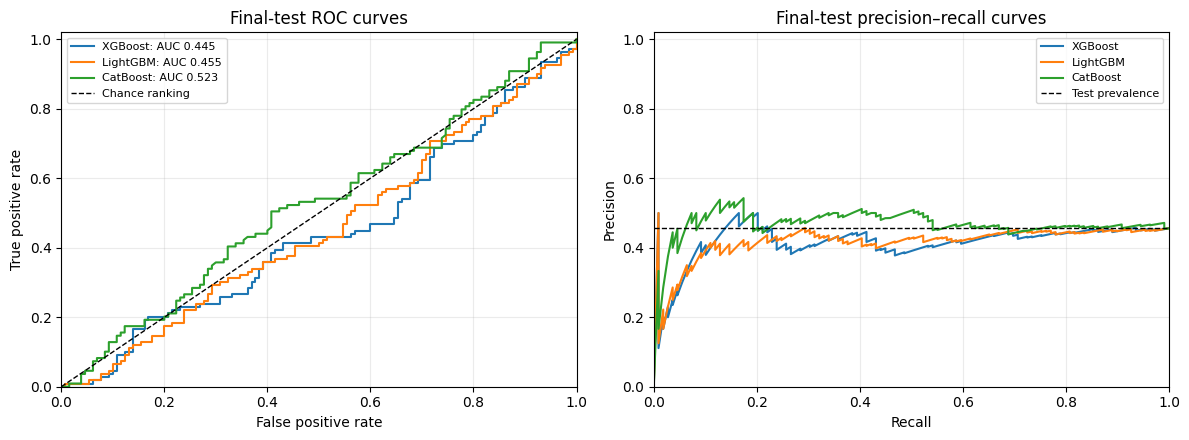

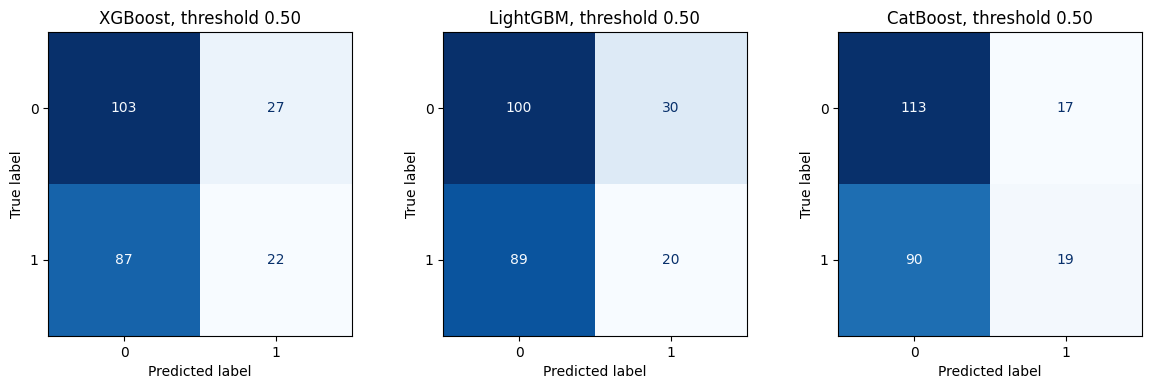

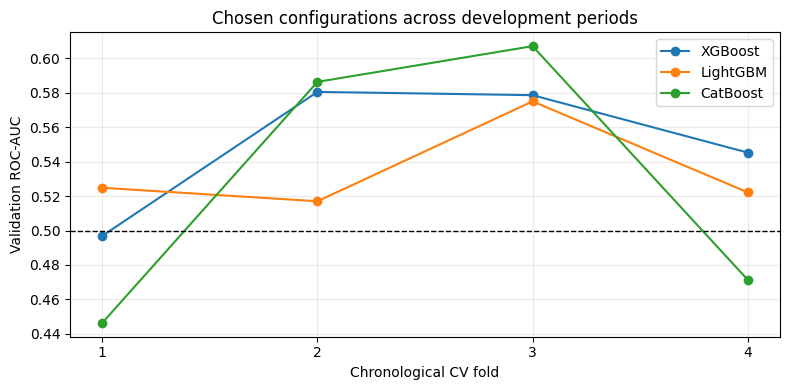

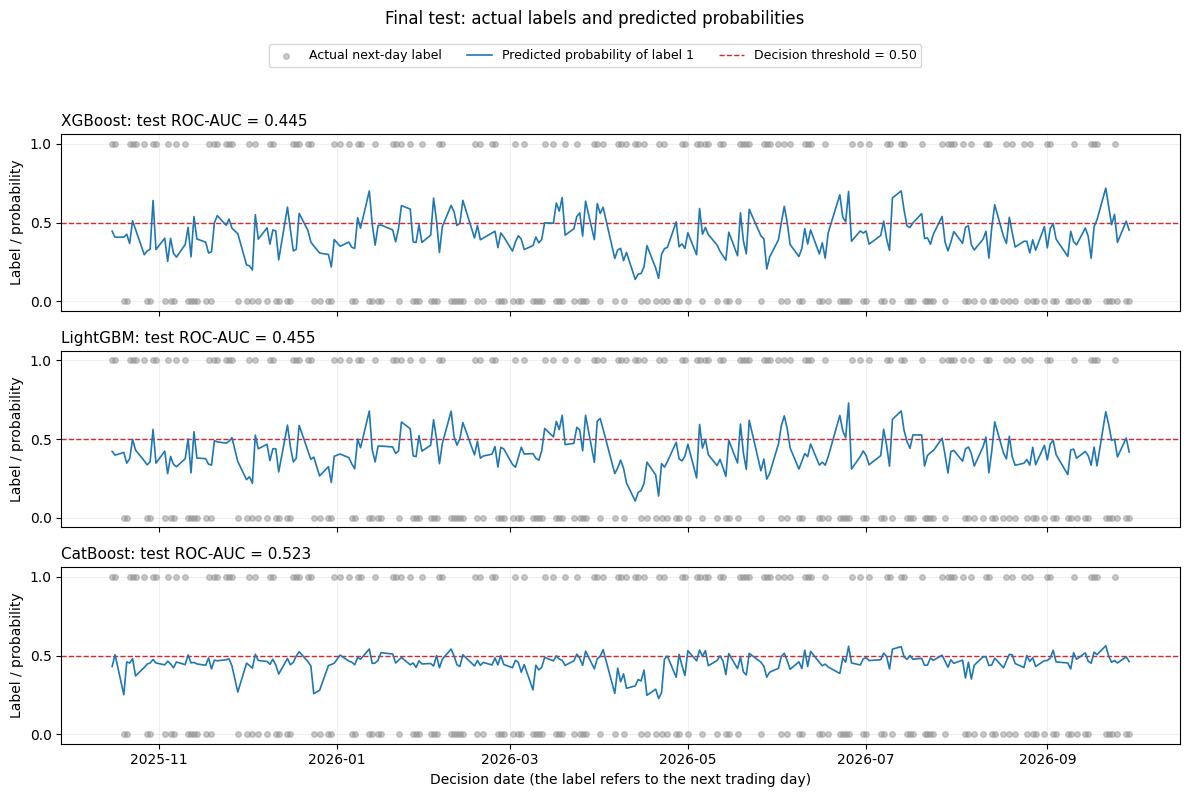

Classification HTML report: /content/results/q2c_evaluation/SPY_classification_report.html


Evaluation run: https://wandb.ai/leon-shawn-123/cqf-exam3-spy/runs/qekb834w


In [56]:
evaluation_plots = []

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name in tuned_models:
    fpr, tpr, _ = roc_curve(y_test, test_probabilities[name])
    axes[0].plot(fpr, tpr, label=f"{name}: AUC {test_comparison.loc[name, 'roc_auc']:.3f}")
    precision, recall, _ = precision_recall_curve(y_test, test_probabilities[name])
    axes[1].plot(recall, precision, label=name)
axes[0].plot([0, 1], [0, 1], "k--", linewidth=1, label="Chance ranking")
axes[0].set(xlabel="False positive rate", ylabel="True positive rate", title="Final-test ROC curves")
axes[1].axhline(y_test.mean(), color="black", linestyle="--", linewidth=1, label="Test prevalence")
axes[1].set(xlabel="Recall", ylabel="Precision", title="Final-test precision–recall curves")
for ax in axes:
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)
    ax.grid(alpha=0.25)
    ax.legend(fontsize=8)
fig.tight_layout()
path = Q2C_DIR / "roc_and_precision_recall.png"
fig.savefig(path, dpi=150, bbox_inches="tight")
evaluation_plots.append(path)
display(fig)
plt.close(fig)

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
for ax, name in zip(axes, tuned_models):
    ConfusionMatrixDisplay(confusion_matrices[name], display_labels=[0, 1]).plot(
        ax=ax, cmap="Blues", colorbar=False, values_format="d",
    )
    ax.set_title(f"{name}, threshold {DECISION_THRESHOLD:.2f}")
fig.tight_layout()
path = Q2C_DIR / "confusion_matrices.png"
fig.savefig(path, dpi=150, bbox_inches="tight")
evaluation_plots.append(path)
display(fig)
plt.close(fig)

fig, ax = plt.subplots(figsize=(8, 4))
for name in tuned_models:
    chosen_id = int(best_summary.loc[name, "candidate"])
    scores = cv_fold_results[
        (cv_fold_results["model"] == name) & (cv_fold_results["candidate"] == chosen_id)
    ].sort_values("fold")
    ax.plot(scores["fold"], scores["roc_auc"], marker="o", label=name)
ax.axhline(0.5, color="black", linestyle="--", linewidth=1)
ax.set(xlabel="Chronological CV fold", ylabel="Validation ROC-AUC", title="Chosen configurations across development periods")
ax.set_xticks(range(1, len(cv_splits) + 1))
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
path = Q2C_DIR / "chosen_cv_auc.png"
fig.savefig(path, dpi=150, bbox_inches="tight")
evaluation_plots.append(path)
display(fig)
plt.close(fig)

# Compare actual next-day labels with the stored test probabilities.
actual_labels = y_test.reindex(test_probabilities.index)

fig, axes = plt.subplots(
    3, 1, figsize=(12, 8), sharex=True, sharey=True
)

for ax, name in zip(axes, tuned_models):
    ax.scatter(
        actual_labels.index, actual_labels,
        color="0.55", s=16, alpha=0.45,
        label="Actual next-day label", zorder=2,
    )

    ax.plot(
        test_probabilities.index, test_probabilities[name],
        color="tab:blue", linewidth=1.2,
        label="Predicted probability of label 1", zorder=3,
    )

    ax.axhline(
        DECISION_THRESHOLD,
        color="tab:red", linestyle="--", linewidth=1,
        label=f"Decision threshold = {DECISION_THRESHOLD:.2f}",
    )

    ax.set_title(
        f"{name}: test ROC-AUC = "
        f"{test_comparison.loc[name, 'roc_auc']:.3f}",
        loc="left", fontsize=11,
    )
    ax.set(ylabel="Label / probability", ylim=(-0.06, 1.06))
    ax.set_yticks([0, 0.5, 1])
    ax.grid(alpha=0.2)

axes[-1].set_xlabel(
    "Decision date (the label refers to the next trading day)"
)
fig.suptitle(
    "Final test: actual labels and predicted probabilities", y=0.99
)
fig.legend(
    *axes[0].get_legend_handles_labels(),
    loc="upper center", bbox_to_anchor=(0.5, 0.955),
    ncol=3, fontsize=9,
)
fig.tight_layout(rect=[0, 0, 1, 0.92])

path = Q2C_DIR / "actual_labels_and_probabilities.png"
fig.savefig(path, dpi=150, bbox_inches="tight")
evaluation_plots.append(path)

display(fig)
plt.close(fig)

with wandb.init(
    project=WANDB_PROJECT, entity=WANDB_ENTITY,
    job_type="final-evaluation", name="q2c-frozen-model-comparison",
    config={
        "stage": "Q2c_final_test", "model_artifacts": TUNED_MODEL_ARTIFACT_REFS,
        "chosen_parameters": BEST_PARAMS, "comparison_policy": comparison_policy,
        "test_start": str(X_test_selected.index.min().date()),
        "test_end": str(X_test_selected.index.max().date()),
        "test_rows": len(y_test), "feature_columns": list(X_test_selected.columns),
        "auc_bootstrap": {"repetitions": BOOTSTRAP_REPETITIONS, "block": BOOTSTRAP_BLOCK, "seed": RANDOM_SEED},
        "package_versions": boosting_package_versions,
    },
) as evaluation_run:
    link_part_a(evaluation_run)
    for ref in TUNED_MODEL_ARTIFACT_REFS.values():
        evaluation_run.use_artifact(ref, type="model")
    log_frame(evaluation_run, "test_comparison", test_comparison.reset_index())
    for name, row in test_comparison.iterrows():
        for metric in ["roc_auc", "log_loss", "precision", "recall", "f1", "balanced_accuracy"]:
            evaluation_run.summary[f"{name}/{metric}"] = float(row[metric])
    for file in evaluation_plots:
        evaluation_run.log({file.stem: wandb.Image(str(file))})
    evaluation_run.summary["recommended_classifier"] = RECOMMENDED_MODEL
    evaluation_run.summary["financial_risk_status"] = "not assessed; optional portfolio omitted"
    for name, row in classification_risk.iterrows():
        evaluation_run.summary[f"{name}/false_positive_rate"] = float(row["false_positive_rate"])
        evaluation_run.summary[f"{name}/false_negative_rate"] = float(row["false_negative_rate"])

    # Save a classification-only HTML report alongside the evaluation tables.
    # This uses the existing predictions and metrics; it does not fit or tune models.
    import base64
    import html

    image_sections = []
    for figure_file in evaluation_plots:
        encoded = base64.b64encode(figure_file.read_bytes()).decode("ascii")
        image_sections.append(
            f'<img alt="{html.escape(figure_file.stem)}" '
            f'src="data:image/png;base64,{encoded}">'
        )

    report_sections = []
    for model_name, report in classification_reports.items():
        report_sections.append(
            f'<h3>{html.escape(model_name)}</h3>'
            f'<p>Accuracy: {report["accuracy"]:.4f}</p>'
            + classification_report_frame(report).to_html()
        )

    REPORT_HTML = Q2C_DIR / "SPY_classification_report.html"
    REPORT_HTML.write_text(
        '<!doctype html><html><head><meta charset="utf-8">'
        '<title>SPY classification comparison</title>'
        '<style>body{max-width:1200px;margin:32px auto;padding:0 20px;'
        'font:15px Arial;line-height:1.5}table{border-collapse:collapse;font-size:12px}'
        'th,td{padding:6px;border:1px solid #ccc}.table-wrap{overflow-x:auto}'
        'img{max-width:100%;height:auto}pre{white-space:pre-wrap;font:inherit}</style>'
        '</head><body><h1>SPY: comparison of three boosted-tree classifiers</h1>'
        '<p>This report compares fixed classifiers on the reserved final period. '
        'The optional execution backtest is not attempted; financial risk-adjusted '
        'performance is not measured.</p>'
        '<h2>Chosen hyperparameters and development CV</h2><div class="table-wrap">'
        + best_summary.to_html() + '</div>'
        '<h2>Final-period metrics</h2><div class="table-wrap">'
        + test_comparison.to_html() + '</div>'
        '<h2>Classification reports</h2>' + ''.join(report_sections)
        + '<h2>Interpretation</h2><pre>' + html.escape(Q2C_INTERPRETATION) + '</pre>'
        + ''.join(image_sections) + '</body></html>',
        encoding="utf-8",
    )
    print("Classification HTML report:", REPORT_HTML.resolve())

    artifact = wandb.Artifact(
        "spy-final-test-evaluation", type="evaluation",
        metadata={"model_artifacts": TUNED_MODEL_ARTIFACT_REFS, "threshold": DECISION_THRESHOLD},
    )
    for file in sorted(Q2C_DIR.iterdir()):
        if file.is_file():
            artifact.add_file(str(file))
    logged = evaluation_run.log_artifact(artifact)
    logged.wait()
    EVALUATION_ARTIFACT_REF = f"{evaluation_run.entity}/{evaluation_run.project}/spy-final-test-evaluation:{logged.version}"
    WANDB_EVALUATION_URL = evaluation_run.url
print("Evaluation run:", WANDB_EVALUATION_URL)


**Results — which model worked best here?**

**1. CV results versus the final test**

After choosing hyperparameters in Q2(b), I evaluated the three fitted models on 239 reserved observations, dated 16 October 2025 to 29 September 2026. The test set contains 109 positive events and 130 observations labelled “other move”.

| Model | Mean CV AUC | CV AUC standard deviation | Final-test AUC | Final-test log loss |
|---|---:|---:|---:|---:|
| XGBoost | 0.5503 | 0.0391 | 0.4450 | 0.7442 |
| LightGBM | 0.5347 | 0.0270 | 0.4548 | 0.7417 |
| CatBoost | 0.5278 | 0.0807 | 0.5229 | 0.6888 |
| Constant benchmark | — | — | 0.5000 | 0.6900 |

XGBoost had the highest selected CV AUC, but CatBoost had the highest test AUC. XGBoost and LightGBM both scored below the constant benchmark’s AUC of $0.5$. So the CV winner did not stay the winner on later dates.

There are several possible reasons. Picking the best of many settings can make CV scores look better than future performance. The test period can also differ by chance, or market relationships may have changed. These results cannot tell us which explanation matters most. The CV scores also came after feature selection using those same validation periods.

**2. How much better was CatBoost?**

CatBoost’s test AUC is $0.5229$, only a little above $0.5$. Its approximate 95% block-bootstrap interval is $[0.4566,\,0.5982]$, which includes $0.5$. The XGBoost and LightGBM intervals also include $0.5$. With these intervals, we do not have clear evidence that any model ranks better than chance.

CatBoost also has the lowest test log loss, but its improvement over the constant-probability benchmark is small:

$$
0.689975-0.688808=0.001167.
$$

XGBoost and LightGBM had higher log loss than the constant benchmark. Their probabilities therefore scored worse on this final period.

CatBoost’s accuracy is $55.23\%$, versus $54.39\%$ for always predicting label $0$. That is only **two extra correct predictions** out of 239. Its balanced accuracy is $0.5218$, versus $0.5$ for the constant classifier. CatBoost did better, but the improvement is small.

**3. Which events did the models catch or miss?**

At the fixed probability threshold of $0.5$, the confusion-matrix counts are:

| Model | True negatives | False positives | False negatives | True positives |
|---|---:|---:|---:|---:|
| XGBoost | 103 | 27 | 87 | 22 |
| LightGBM | 100 | 30 | 89 | 20 |
| CatBoost | 113 | 17 | 90 | 19 |

All three models produce relatively few positive predictions and miss most positive events.

CatBoost gives **36 positive signals**, of which 19 correspond to actual positive events. Its positive-class precision is therefore $19/36=52.78\%$, the highest of the three. However, it identifies only $19/109=17.43\%$ of all positive events, missing the remaining 90.

XGBoost identifies slightly more positive events: 22, giving recall of $20.18\%$. It also produces more false positives, reducing precision to $44.90\%$. LightGBM identifies 20 positive events, with precision of $40.00\%$ and recall of $18.35\%$.

CatBoost gives fewer positive signals, with higher precision. XGBoost catches slightly more positive events and has the highest positive-class F1. The F1 scores are still low: $0.2785$, $0.2516$ and $0.2621$ for XGBoost, LightGBM and CatBoost. CatBoost does not win on every metric.

These counts concern the specified positive-move label, not realised trading profits. Label $0$ can include small positive returns, and execution timing and transaction costs also affect whether a signal earns money.

**4. Variation across periods and running time**

LightGBM’s CV AUC varies least, with standard deviation $0.0270$. XGBoost is next at $0.0391$, and CatBoost varies most at $0.0807$. CatBoost’s better test result therefore does not make it the most stable across these periods.

Fitting again on all development data took about $0.078$ seconds for LightGBM, $0.153$ seconds for XGBoost and $0.551$ seconds for CatBoost. All are fast enough for this small dataset. These timings depend on the machine.

**5. What this comparison can explain**

This compares particular library configurations on one SPY dataset. All three chosen configurations use depth-two trees, which limits how strongly their different growth policies can express themselves. The models also differ in several settings and internal procedures at once. We have not isolated the effect of leaf-wise growth, symmetric trees or ordered boosting.

The inputs are numerical, so CatBoost's categorical Target Statistics are not used here and cannot explain its observed advantage. Ordered boosting is still enabled; it is a separate mechanism. The Target Statistics formula in Q2(b) answers the mathematical question, but describes a categorical mechanism that this dataset does not exercise [7, 8]. A controlled comparison changing one mechanism at a time would be needed to attribute the result to that mechanism.

**6. My choice**

**CatBoost is my best observed choice in the main twelve-feature comparison.** It has the highest test AUC, lowest test log loss and highest positive-class precision. It is also the only model within $0.01$ of the highest test AUC.

I give final-period ranking and probability loss the most weight here because all three models are fast enough for this task. CatBoost also has fewer false alarms at the fixed threshold. The trade-off is that it misses more positive events and varies more across the CV periods than the other two. This is why I choose it for further checking, while keeping those weaknesses visible.

The log-loss gain over the constant benchmark is only about $0.0012$, its AUC interval includes $0.5$, and it has the greatest CV variation of the three. Thus, the recommendation is relative to these models and this test period. We have not established dependable predictive performance. The follow-up below checks another feature count without replacing this main comparison or treating the same test period as a new independent test.

CatBoost’s false-positive rate is $17/130=13.08\%$, versus $20.77\%$ for XGBoost and $23.08\%$ for LightGBM. Its false-negative rate is $90/109=82.57\%$. It makes fewer false alarms but misses most positive events. These rates count classification errors, not money lost. I do not attempt the optional portfolio add-on, so profitability, Sharpe, Sortino and drawdown are not measured. A later unused period is needed to check whether CatBoost remains the better choice.

**Follow-up — seven features versus twelve**

The logistic wrapper scored best with seven features in the saved run. I now check whether that preference also appears in the tree models. This is an additional feature-count experiment within Q2(c), not the optional portfolio backtest.

I use the **first seven features in the wrapper's selection order**, not the seven largest L1 coefficients. Each library keeps the settings already chosen in Q2(b), and uses the same dates, labels, four CV folds, one-row gaps and threshold. Its original twelve-feature scores are reused. For seven features, I fit a fresh model in each fold, then refit on all development data and predict the existing final period once: **15 additional fits** across the three libraries.

The comparison asks whether seven or twelve does better under these fixed settings, and whether the tree CV preference agrees with the final-period preference. The settings were tuned for twelve features, so this does not establish the best possible seven-feature model. Better logistic CV performance need not mean better tree performance.

**This is an exploratory follow-up:** we have already inspected the original test results. The experiment does not change Part A's final list or the main model recommendation. A new choice made from this comparison would need a later unused period for independent assessment. No further parameter or threshold search is performed here.

For either CV or the final period, I report

$$
\Delta A=A_7-A_{\mathrm{original}},\qquad
\Delta L=L_{\mathrm{original}}-L_7.
$$

Here $A$ is AUC and $L$ is average log loss. Positive values favour seven features: higher AUC or lower loss. The code generates the score tables, interpretation and plots when run. All new models, settings, feature names, dates, fold scores, predictions and reports are saved and recorded with W&B.

In [57]:
# Run after the main Q2(c) evaluation. Original models and scores are reused unchanged.
SEVEN_FEATURE_COUNT = 7
if len(wrapper_features) < SEVEN_FEATURE_COUNT:
    raise ValueError("This comparison needs at least seven wrapper features.")

seven_features = wrapper_features[:SEVEN_FEATURE_COUNT].copy()
main_feature_count = X_train_selected.shape[1]
if main_feature_count <= SEVEN_FEATURE_COUNT:
    raise ValueError("The original feature list must contain more than seven features for this comparison.")
X_train_seven = X_train[seven_features].copy()
X_test_seven = X_test[seven_features].copy()

SENSITIVITY_DIR = Q2C_DIR / "feature_count_comparison"
SENSITIVITY_MODEL_DIR = SENSITIVITY_DIR / "seven_feature_models"
SENSITIVITY_MODEL_DIR.mkdir(parents=True, exist_ok=True)

sensitivity_design = {
    "stage": "Q2c_exploratory_feature_count_comparison",
    "status": "Follow-up designed after inspecting the original final-test results",
    "seven_features": seven_features,
    "original_features": list(X_train_selected.columns),
    "parameters_fixed_from_original_search": BEST_PARAMS,
    "baseline_parameters": baseline_params,
    "cv_folds": fold_table.to_dict(orient="records"),
    "depth_comparison": "Settings, including depth, were tuned for the original features and reused for seven",
    "decision_threshold": DECISION_THRESHOLD,
    "seed": RANDOM_SEED,
    "package_versions": boosting_package_versions,
    "original_model_artifacts": TUNED_MODEL_ARTIFACT_REFS,
    "original_evaluation_artifact": EVALUATION_ARTIFACT_REF,
    "training_rows": len(y_train), "test_rows": len(y_test),
    "training_start": str(X_train.index.min().date()),
    "training_end": str(X_train.index.max().date()),
    "test_start": str(X_test.index.min().date()),
    "test_end": str(X_test.index.max().date()),
    "fit_count": len(tuned_models) * (len(cv_splits) + 1),
    "interpretation": (
        "Feature-set comparison under settings tuned for the original feature list; "
        "no extra hyperparameter search or change to the main recommendation."
    ),
}
(SENSITIVITY_DIR / "comparison_design.json").write_text(
    json.dumps(sensitivity_design, indent=2), encoding="utf-8",
)

print("Seven-feature list:", seven_features)
print("Original feature count:", main_feature_count)
print("New fits:", sensitivity_design["fit_count"])

sensitivity_models_seven = {}
sensitivity_rows = []
sensitivity_fold_rows = []
seven_test_probabilities = pd.DataFrame(index=X_test.index)
seven_oof_probabilities = pd.DataFrame(index=X_train.index)

for name in tuned_models:
    # Reuse the original chosen configuration's four fold scores and final-test scores.
    original_cv = best_summary.loc[name]
    original_test = test_comparison.loc[name]
    sensitivity_rows.append({
        "model": name, "feature_count": main_feature_count,
        "mean_cv_auc": float(original_cv["mean_cv_auc"]),
        "std_cv_auc": float(original_cv["std_cv_auc"]),
        "mean_cv_log_loss": float(original_cv["mean_cv_log_loss"]),
        "test_auc": float(original_test["roc_auc"]),
        "test_log_loss": float(original_test["log_loss"]),
        "test_precision": float(original_test["precision"]),
        "test_recall": float(original_test["recall"]),
        "test_f1": float(original_test["f1"]),
        "refit_seconds": float(original_cv["refit_seconds"]),
        "source": "original results reused",
    })
    original_folds = cv_fold_results[
        (cv_fold_results["model"] == name)
        & (cv_fold_results["candidate"] == int(original_cv["candidate"]))
    ].copy()
    original_folds["feature_count"] = main_feature_count
    original_folds["source"] = "original results reused"
    sensitivity_fold_rows.extend(original_folds.to_dict(orient="records"))

    aucs, losses = [], []
    oof = pd.Series(np.nan, index=X_train.index, name=name)
    for fold, (train_idx, validation_idx) in enumerate(cv_splits, start=1):
        X_fit = X_train_seven.iloc[train_idx]
        y_fit = y_train.iloc[train_idx]
        model = make_booster(name, BEST_PARAMS[name], y_fit.mean())
        started = perf_counter()
        model.fit(X_fit, y_fit)
        elapsed = perf_counter() - started
        probabilities = model.predict_proba(X_train_seven.iloc[validation_idx])[:, 1]
        auc = float(roc_auc_score(y_train.iloc[validation_idx], probabilities))
        loss = float(log_loss(y_train.iloc[validation_idx], probabilities, labels=[0, 1]))
        aucs.append(auc)
        losses.append(loss)
        oof.iloc[validation_idx] = probabilities
        sensitivity_fold_rows.append({
            **fold_table.iloc[fold - 1].to_dict(),
            "model": name, "feature_count": SEVEN_FEATURE_COUNT, "fold": fold,
            "roc_auc": auc, "log_loss": loss, "fit_seconds": elapsed,
            "initial_positive_fraction": float(y_fit.mean()),
            "parameters_json": json.dumps(BEST_PARAMS[name], sort_keys=True),
            "source": "seven-feature follow-up",
        })
        print(f"{name}, seven features, fold {fold}: AUC={auc:.4f}, log loss={loss:.4f}")

    # Refit once on all development rows. Only then predict the existing final period.
    model = make_booster(name, BEST_PARAMS[name], y_train.mean())
    started = perf_counter()
    model.fit(X_train_seven, y_train)
    refit_seconds = perf_counter() - started
    probabilities = model.predict_proba(X_test_seven)[:, 1]
    predicted = (probabilities >= DECISION_THRESHOLD).astype(int)
    sensitivity_models_seven[name] = model
    seven_test_probabilities[name] = probabilities
    seven_oof_probabilities[name] = oof
    save_native_model(name, model, SENSITIVITY_MODEL_DIR)
    sensitivity_rows.append({
        "model": name, "feature_count": SEVEN_FEATURE_COUNT,
        "mean_cv_auc": float(np.mean(aucs)),
        "std_cv_auc": float(np.std(aucs, ddof=1)),
        "mean_cv_log_loss": float(np.mean(losses)),
        "test_auc": float(roc_auc_score(y_test, probabilities)),
        "test_log_loss": float(log_loss(y_test, probabilities, labels=[0, 1])),
        "test_precision": float(precision_score(y_test, predicted, zero_division=0)),
        "test_recall": float(recall_score(y_test, predicted, zero_division=0)),
        "test_f1": float(f1_score(y_test, predicted, zero_division=0)),
        "refit_seconds": refit_seconds, "source": "seven-feature follow-up",
    })

sensitivity_summary = pd.DataFrame(sensitivity_rows).sort_values(["model", "feature_count"])
sensitivity_folds = pd.DataFrame(sensitivity_fold_rows)
sensitivity_summary.to_csv(SENSITIVITY_DIR / "feature_count_scores.csv", index=False)
sensitivity_folds.to_csv(SENSITIVITY_DIR / "feature_count_fold_scores.csv", index=False)
cv_probability_check.to_csv(SENSITIVITY_DIR / "cv_probability_benchmark.csv")

seven_predictions = test_predictions[["actual_label", "target_date"]].join(
    seven_test_probabilities.add_suffix("_probability")
).join((seven_test_probabilities >= DECISION_THRESHOLD).astype(int).add_suffix("_predicted_label"))
seven_predictions.to_csv(SENSITIVITY_DIR / "seven_feature_test_predictions.csv", index_label="Date")
seven_oof_probabilities.join(y_train.rename("actual_label")).dropna().to_csv(
    SENSITIVITY_DIR / "seven_feature_oof_predictions.csv", index_label="Date",
)

# Positive changes favour seven features: higher AUC or lower log loss.
sensitivity_changes_rows = []
for name in tuned_models:
    scores = sensitivity_summary[sensitivity_summary["model"] == name].set_index("feature_count")
    smaller, original = scores.loc[SEVEN_FEATURE_COUNT], scores.loc[main_feature_count]
    sensitivity_changes_rows.append({
        "model": name,
        "cv_auc_change": smaller["mean_cv_auc"] - original["mean_cv_auc"],
        "test_auc_change": smaller["test_auc"] - original["test_auc"],
        "cv_log_loss_improvement": original["mean_cv_log_loss"] - smaller["mean_cv_log_loss"],
        "test_log_loss_improvement": original["test_log_loss"] - smaller["test_log_loss"],
    })
sensitivity_changes = pd.DataFrame(sensitivity_changes_rows).set_index("model")
sensitivity_changes.to_csv(SENSITIVITY_DIR / "changes_favouring_seven.csv")
display(sensitivity_summary.set_index(["model", "feature_count"]))
display(sensitivity_changes)

sensitivity_lines = [
    "**Seven-feature follow-up — results from this run**",
    f"Compared the first seven wrapper features with the original {main_feature_count}, "
    "holding the chosen model settings, labels, dates and folds fixed. Positive changes "
    "in the change table favour seven features.",
]
for name in tuned_models:
    row = sensitivity_changes.loc[name]
    if abs(row["cv_auc_change"]) < 1e-12 or abs(row["test_auc_change"]) < 1e-12:
        agreement = "At least one AUC comparison is tied."
    elif row["cv_auc_change"] * row["test_auc_change"] > 0:
        agreement = "CV and final-period AUC favour the same feature count."
    else:
        agreement = "The CV AUC preference does not carry over to the final period."
    sensitivity_lines.append(
        f"- **{name}:** CV AUC change {row['cv_auc_change']:+.4f}; "
        f"final-period AUC change {row['test_auc_change']:+.4f}; "
        f"CV log-loss improvement {row['cv_log_loss_improvement']:+.4f}; "
        f"final-period log-loss improvement {row['test_log_loss_improvement']:+.4f}. {agreement}"
    )
sensitivity_lines.append(
    "Seven was preferred by the logistic wrapper in the saved original run. This does "
    "not guarantee that the tree models will prefer it. These comparisons describe this "
    "dataset and the fixed settings; small differences are not established as significant. "
    "The settings were tuned for the original feature list. This follow-up was added after "
    "the original test results were seen, so it is exploratory and leaves the main "
    "feature list, models and recommendation unchanged. A later unused period would be "
    "needed to assess a new choice made from these results."
)
SENSITIVITY_INTERPRETATION = "\n\n".join(sensitivity_lines)
(SENSITIVITY_DIR / "interpretation.md").write_text(SENSITIVITY_INTERPRETATION, encoding="utf-8")
display(Markdown(SENSITIVITY_INTERPRETATION))


Seven-feature list: ['OC7', 'VCHG28', 'VMA_DIST60', 'OC28', 'RET_LAG5', 'OC14', 'RET_LAG10']
Original feature count: 12
New fits: 15
XGBoost, seven features, fold 1: AUC=0.4796, log loss=0.7600
XGBoost, seven features, fold 2: AUC=0.5103, log loss=0.7064
XGBoost, seven features, fold 3: AUC=0.5519, log loss=0.6940
XGBoost, seven features, fold 4: AUC=0.5532, log loss=0.6964
LightGBM, seven features, fold 1: AUC=0.5089, log loss=0.7553
LightGBM, seven features, fold 2: AUC=0.4960, log loss=0.7110
LightGBM, seven features, fold 3: AUC=0.5605, log loss=0.6957
LightGBM, seven features, fold 4: AUC=0.5457, log loss=0.6973
CatBoost, seven features, fold 1: AUC=0.4783, log loss=0.7352
CatBoost, seven features, fold 2: AUC=0.4908, log loss=0.6954
CatBoost, seven features, fold 3: AUC=0.5506, log loss=0.7098
CatBoost, seven features, fold 4: AUC=0.5224, log loss=0.7009


mean_cv_auc  std_cv_auc  mean_cv_log_loss  test_auc  \
model    feature_count                                                        
CatBoost 7                 0.510526    0.032525          0.710335  0.460233   
         12                0.527778    0.080660          0.700954  0.522936   
LightGBM 7                 0.527765    0.030345          0.714839  0.480734   
         12                0.534744    0.027018          0.712266  0.454834   
XGBoost  7                 0.523769    0.035562          0.714198  0.472265   
         12                0.550310    0.039114          0.706149  0.444954   

                        test_log_loss  test_precision  test_recall   test_f1  \
model    feature_count                                                         
CatBoost 7                   0.693773        0.562500     0.082569  0.144000   
         12                  0.688808        0.527778     0.174312  0.262069   
LightGBM 7                   0.722009        0.431373     0.201835  0.275000   
         12                  0.741694        0.400000     0.183486  0.251572   
XGBoost  7                   0.720541        0.480000     0.220183  0.301887   
         12                  0.744195        0.448980     0.201835  0.278481   

                        refit_seconds                   source  
model    feature_count                                          
CatBoost 7                   0.474830  seven-feature follow-up  
         12                  0.542776  original results reused  
LightGBM 7                   0.109364  seven-feature follow-up  
         12                  0.075224  original results reused  
XGBoost  7                   1.119225  seven-feature follow-up  
         12                  0.158684  original results reused

,cv_auc_change,test_auc_change,cv_log_loss_improvement,test_log_loss_improvement
model,,,,
XGBoost,-0.026541,0.027311,-0.008049,0.023653
LightGBM,-0.006979,0.025900,-0.002573,0.019685
CatBoost,-0.017252,-0.062703,-0.009380,-0.004965


**Seven-feature follow-up — results from this run**

Compared the first seven wrapper features with the original 12, holding the chosen model settings, labels, dates and folds fixed. Positive changes in the change table favour seven features.

- **XGBoost:** CV AUC change -0.0265; final-period AUC change +0.0273; CV log-loss improvement -0.0080; final-period log-loss improvement +0.0237. The CV AUC preference does not carry over to the final period.

- **LightGBM:** CV AUC change -0.0070; final-period AUC change +0.0259; CV log-loss improvement -0.0026; final-period log-loss improvement +0.0197. The CV AUC preference does not carry over to the final period.

- **CatBoost:** CV AUC change -0.0173; final-period AUC change -0.0627; CV log-loss improvement -0.0094; final-period log-loss improvement -0.0050. CV and final-period AUC favour the same feature count.

Seven was preferred by the logistic wrapper in the saved original run. This does not guarantee that the tree models will prefer it. These comparisons describe this dataset and the fixed settings; small differences are not established as significant. The settings were tuned for the original feature list. This follow-up was added after the original test results were seen, so it is exploratory and leaves the main feature list, models and recommendation unchanged. A later unused period would be needed to assess a new choice made from these results.

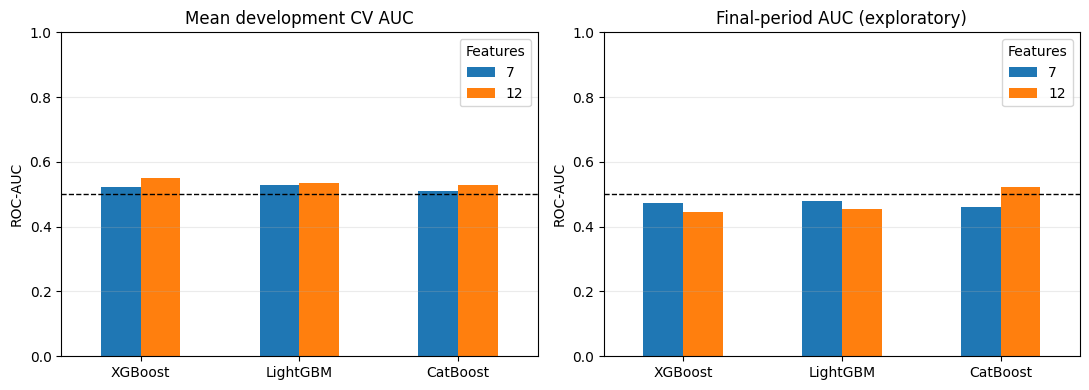

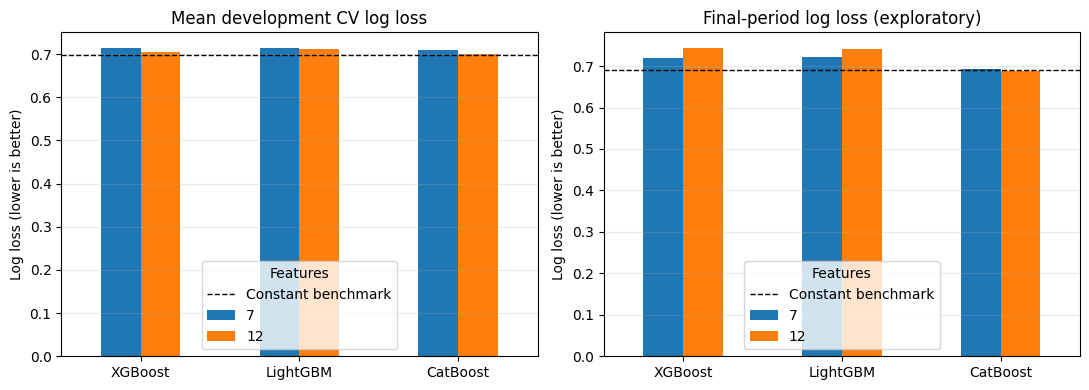

Feature-count W&B run: https://wandb.ai/leon-shawn-123/cqf-exam3-spy/runs/2vdi2li1
Feature-count HTML report: /content/results/q2c_evaluation/feature_count_comparison/SPY_feature_count_comparison.html


In [58]:
# Show both feature counts under the same settings, then record the complete follow-up.
feature_count_plot_files = []
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric, title in zip(
    axes, ["mean_cv_auc", "test_auc"], ["Mean development CV AUC", "Final-period AUC (exploratory)"],
):
    comparison = sensitivity_summary.pivot(index="model", columns="feature_count", values=metric)
    comparison = comparison.reindex(list(tuned_models))
    comparison.plot.bar(ax=ax, rot=0)
    ax.axhline(0.5, color="black", linestyle="--", linewidth=1)
    ax.set(xlabel="", ylabel="ROC-AUC", title=title, ylim=(0, 1))
    ax.legend(title="Features")
    ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
feature_count_plot = SENSITIVITY_DIR / "seven_vs_original_auc.png"
fig.savefig(feature_count_plot, dpi=150, bbox_inches="tight")
feature_count_plot_files.append(feature_count_plot)
display(fig)
plt.close(fig)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, metric, title in zip(
    axes, ["mean_cv_log_loss", "test_log_loss"],
    ["Mean development CV log loss", "Final-period log loss (exploratory)"],
):
    comparison = sensitivity_summary.pivot(index="model", columns="feature_count", values=metric)
    comparison = comparison.reindex(list(tuned_models))
    comparison.plot.bar(ax=ax, rot=0)
    benchmark = baseline_cv_loss if metric == "mean_cv_log_loss" else benchmark_loss
    ax.axhline(benchmark, color="black", linestyle="--", linewidth=1, label="Constant benchmark")
    ax.set(xlabel="", ylabel="Log loss (lower is better)", title=title)
    ax.legend(title="Features")
    ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
feature_count_plot = SENSITIVITY_DIR / "seven_vs_original_log_loss.png"
fig.savefig(feature_count_plot, dpi=150, bbox_inches="tight")
feature_count_plot_files.append(feature_count_plot)
display(fig)
plt.close(fig)

import base64
import html

sensitivity_images = []
for file in feature_count_plot_files:
    encoded = base64.b64encode(file.read_bytes()).decode("ascii")
    sensitivity_images.append(
        f'<img alt="{html.escape(file.stem)}" src="data:image/png;base64,{encoded}" '
        'style="max-width:100%;height:auto">'
    )
SENSITIVITY_HTML = SENSITIVITY_DIR / "SPY_feature_count_comparison.html"
SENSITIVITY_HTML.write_text(
    '<!doctype html><html><head><meta charset="utf-8"><title>SPY feature-count follow-up</title>'
    '<style>body{max-width:1150px;margin:30px auto;padding:0 20px;font:15px Arial;line-height:1.5}'
    'table{border-collapse:collapse;font-size:12px}th,td{border:1px solid #ccc;padding:6px}'
    'pre{white-space:pre-wrap;font:inherit}.wide{overflow-x:auto}</style></head><body>'
    '<h1>Seven features versus the original feature list</h1>'
    '<p>Exploratory follow-up after the original final-test evaluation. Hyperparameters are '
    'fixed from the original search. The primary model comparison is preserved.</p>'
    '<h2>Feature lists and fixed settings</h2><pre>'
    + html.escape(json.dumps(sensitivity_design, indent=2)) + '</pre>'
    '<h2>Scores</h2><div class="wide">' + sensitivity_summary.to_html(index=False) + '</div>'
    '<h2>Changes: positive favours seven features</h2><div class="wide">'
    + sensitivity_changes.to_html() + '</div><h2>Interpretation</h2><pre>'
    + html.escape(SENSITIVITY_INTERPRETATION) + '</pre>' + ''.join(sensitivity_images)
    + '</body></html>', encoding="utf-8",
)

with wandb.init(
    project=WANDB_PROJECT, entity=WANDB_ENTITY,
    job_type="feature-count-comparison", name="q2c-seven-vs-original-features",
    config=sensitivity_design,
) as sensitivity_run:
    link_part_a(sensitivity_run)
    for ref in TUNED_MODEL_ARTIFACT_REFS.values():
        sensitivity_run.use_artifact(ref, type="model")
    sensitivity_run.use_artifact(EVALUATION_ARTIFACT_REF, type="evaluation")
    log_frame(sensitivity_run, "feature_count_scores", sensitivity_summary)
    log_frame(sensitivity_run, "feature_count_fold_scores", sensitivity_folds)
    log_frame(sensitivity_run, "changes_favouring_seven", sensitivity_changes.reset_index())
    log_frame(sensitivity_run, "cv_probability_benchmark", cv_probability_check.reset_index())
    for row in sensitivity_summary.to_dict(orient="records"):
        prefix = f"{row['model']}/{row['feature_count']}_features"
        for metric in ["mean_cv_auc", "std_cv_auc", "mean_cv_log_loss", "test_auc", "test_log_loss"]:
            sensitivity_run.summary[f"{prefix}/{metric}"] = float(row[metric])
    sensitivity_run.summary["new_fit_count"] = sensitivity_design["fit_count"]
    sensitivity_run.summary["status"] = "exploratory; original test period already inspected"
    for file in feature_count_plot_files:
        sensitivity_run.log({file.stem: wandb.Image(str(file))})
    sensitivity_artifact = wandb.Artifact(
        "spy-feature-count-comparison", type="feature-comparison", metadata=sensitivity_design,
    )
    for file in sorted(SENSITIVITY_DIR.rglob("*")):
        if file.is_file():
            sensitivity_artifact.add_file(str(file), name=str(file.relative_to(SENSITIVITY_DIR)))
    logged_sensitivity = sensitivity_run.log_artifact(sensitivity_artifact)
    logged_sensitivity.wait()
    FEATURE_COUNT_ARTIFACT_REF = (
        f"{sensitivity_run.entity}/{sensitivity_run.project}/spy-feature-count-comparison:"
        f"{logged_sensitivity.version}"
    )
    WANDB_FEATURE_COUNT_URL = sensitivity_run.url
print("Feature-count W&B run:", WANDB_FEATURE_COUNT_URL)
print("Feature-count HTML report:", SENSITIVITY_HTML.resolve())


**Interpretation — what the seven-feature comparison tells us**

The logistic wrapper preferred seven features, but **all three tree models prefer twelve in CV**, on both AUC and log loss. The feature count preferred by one selector therefore need not be preferred by a different model.

| Model | CV AUC: 7 | CV AUC: 12 | Test AUC: 7 | Test AUC: 12 |
|---|---:|---:|---:|---:|
| XGBoost | 0.5238 | 0.5503 | 0.4723 | 0.4450 |
| LightGBM | 0.5278 | 0.5347 | 0.4807 | 0.4548 |
| CatBoost | 0.5105 | 0.5278 | 0.4602 | 0.5229 |

**XGBoost and LightGBM:** seven features give worse CV scores but better final-period AUC and log loss. XGBoost's final log loss falls from 0.7442 to 0.7205; LightGBM's falls from 0.7417 to 0.7220. This gives a concrete example of the CV preference failing to carry over to later dates. However, both seven-feature AUCs remain below 0.5 and both losses remain worse than the constant benchmark's 0.6900. Their improvement is relative to their twelve-feature versions, not evidence of a reliable forecasting edge.

**CatBoost:** twelve features do better in both CV and final testing. With seven, its test AUC falls from 0.5229 to 0.4602 and log loss rises from 0.6888 to 0.6938. Seven features give higher positive-class precision (0.5625 versus 0.5278), but recall falls from 0.1743 to 0.0826. A higher precision alone does not make the seven-feature model the better overall classifier.

**Depth and fairness of this comparison:** all seven-feature models reuse the depth-two settings tuned for twelve features. We have not shown that depth two is the best depth for seven, or found the best possible seven-feature configuration. The experiment compares feature counts under fixed settings; it does not independently optimise both feature sets.

The best observed classifier remains **twelve-feature CatBoost**, with the same small and uncertain advantage described above. The seven-feature follow-up was designed after inspecting the original test results. It is exploratory and does not turn that period into a fresh independent test. We keep the main feature list and model recommendation, rather than retuning them from these comparisons. A later unused period would be needed to assess a new choice based on these results.


### References and reading guide

**Start with [5, §2] for the tree maths:** how to add a tree, estimate the loss change, calculate leaf outputs and compare splits. Then read [6] for LightGBM and [7, §§3–5] for CatBoost. Use [8] to look up the parameter names in the code.

The other sources cover feature selection, stationarity and evaluation. The threshold, feature limits, search ranges and CV design are choices made for this notebook.

1. **Guyon, I. & Elisseeff, A. (2003).** *An Introduction to Variable and Feature Selection*. Journal of Machine Learning Research, **3**, 1157–1182. [Paper](https://jmlr.org/papers/volume3/guyon03a/guyon03a.pdf). Sections 2.2 and 2.4 explain correlation and mutual information; §4 describes filters, wrappers and embedded methods, with greedy search in §4.1. Background for the three selection stages.

2. **Hyndman, R. J. & Athanasopoulos, G.** *Forecasting: Principles and Practice*, 3rd edition, §9.1: [Stationarity and differencing](https://otexts.com/fpp3/arima.html#stationarity-and-differencing). Explains why changes and log differences can be more stable than price levels. Background for the log-return example in Q1(b).

3. **scikit-learn 1.7.2 documentation.** [Logistic regression](https://scikit-learn.org/1.7/modules/linear_model.html#logistic-regression), [mutual information estimation](https://scikit-learn.org/1.7/modules/generated/sklearn.feature_selection.mutual_info_classif.html), [classification metrics](https://scikit-learn.org/1.7/modules/model_evaluation.html), [TimeSeriesSplit](https://scikit-learn.org/1.7/modules/generated/sklearn.model_selection.TimeSeriesSplit.html) and [ParameterGrid](https://scikit-learn.org/1.7/modules/generated/sklearn.model_selection.ParameterGrid.html). Documents the penalty scaling, MI options, metrics and chronological splits used here. Sampling configurations from ParameterGrid is our own explicit loop.

4. **statsmodels 0.14.6 documentation.** [ADF](https://www.statsmodels.org/v0.14.6/generated/statsmodels.tsa.stattools.adfuller.html) and [KPSS](https://www.statsmodels.org/v0.14.6/generated/statsmodels.tsa.stattools.kpss.html). Explains the null hypotheses, lag settings and p-values. The combined screening rule is our design choice.

5. **Chen, T. & Guestrin, C. (2016).** *XGBoost: A Scalable Tree Boosting System*. Proceedings of KDD 2016. [Paper](https://arxiv.org/pdf/1603.02754); [DOI](https://doi.org/10.1145/2939672.2939785). Section 2, equations (1)–(7), gives the main tree derivation. The paper displays L2 and leaf-count penalties; the L1 extension in our answer is derived by adding the documented L1 leaf-weight penalty [8]. Section 2.3 explains learning-rate shrinkage.

6. **Ke, G. et al. (2017).** *LightGBM: A Highly Efficient Gradient Boosting Decision Tree*. Advances in Neural Information Processing Systems **30**. [Paper](https://proceedings.neurips.cc/paper_files/paper/2017/file/6449f44a102fde848669bdd9eb6b76fa-Paper.pdf). Explains the GBDT background and LightGBM's efficiency techniques. GOSS is not enabled in this notebook; the exact leaf-wise growth policy is documented in [8].

7. **Prokhorenkova, L. et al. (2018).** *CatBoost: unbiased boosting with categorical features*. Advances in Neural Information Processing Systems **31**. [Paper](https://proceedings.neurips.cc/paper_files/paper/2018/file/14491b756b3a51daac41c24863285549-Paper.pdf). Section 3.2, equation (5) and the ordered-TS discussion, explains the categorical-statistics equation used here. Sections 4–5 explain ordered boosting. A permutation's order is distinct from calendar time.

8. **Official tree-library documentation.** XGBoost [parameters](https://xgboost.readthedocs.io/en/release_3.1.0/parameter.html); LightGBM 4.6.0 [leaf-wise growth](https://lightgbm.readthedocs.io/en/v4.6.0/Features.html#leaf-wise-best-first-tree-growth) and [parameters](https://lightgbm.readthedocs.io/en/v4.6.0/Parameters.html); CatBoost [common parameters](https://catboost.ai/docs/en/references/training-parameters/common). Documents L1/L2, growth limits, starting scores, `has_time` and ordered boosting. The split-choice equations in Q2(b) express these growth policies in our own notation.

9. **Künsch, H. R. (1989).** *The Jackknife and the Bootstrap for General Stationary Observations*. Annals of Statistics, **17**(3), 1217–1241. [DOI](https://doi.org/10.1214/aos/1176347265). Background for block resampling when observations are dependent. The 10-row block size is our choice.


10. **López de Prado, M. (2018).** *Advances in Financial Machine Learning*. Wiley, Chapter 3, particularly §3.3, “Computing Dynamic Thresholds”. [Chapter preview](https://www.oreilly.com/library/view/advances-in-financial/9781119482086/c03.xhtml). The related daily-volatility example is described in the [mlfinlab volatility-function documentation](https://github.com/hudson-and-thames/mlfinlab/blob/master/mlfinlab/util/volatility.py), which refers to Snippet 3.1, page 44. This supports the general use of volatility-scaled return barriers. Our binary next-day rule, simple 20-day standard deviation and 0.2 multiplier are project choices; we do not implement triple-barrier labeling.

Course-code starting points: Python Labs `12_linearregression_wandb.ipynb`, `13_logisticregression_wandb-2.ipynb` and `14_gradientboosting_wandb.ipynb`. The table near the start explains how I use them.

**Running these notes again**

Run from the beginning in a fresh Colab session. Q1 selects the features. Q2(a) fits the starting models, Q2(b) compares settings with CV and fits the chosen models on all development data, and Q2(c) tests them. Running only the plotting cell reuses the saved predictions in memory.

W&B links the data versions and results between stages. Files are saved in:

- `data`: raw data and its plot.
- `results`: feature-selection results.
- `results/q2b_tuning`: tuning results.
- `results/q2c_evaluation`: classification tables, plots and `SPY_classification_report.html`.
- `results/q2c_evaluation/feature_count_comparison`: the exploratory seven-feature models, fold scores, predictions, comparison plots and `SPY_feature_count_comparison.html`.

The numerical discussion and saved result tables use the **final recorded Colab run on 18 October 2026**, with raw dataset version `leon-shawn-123/cqf-exam3-spy/spy-raw:v8`. The feature counts, final twelve-feature list, chosen model settings and final-period classification scores remain the same as in the preceding run. Small changes in intermediate scores and elapsed times do not change the conclusions. These tables are a record of the supplied execution; their source is noted in cell metadata. Running the code regenerates its results and requires the preceding cells to execute. The comparison makes 15 new fits and records them in its own W&B run and Artifact. It reuses the twelve-feature scores and keeps the main models and recommendation.

Old installation output and W&B console banners have been cleared from the saved view. The setup now pins compatible Quantmod/Blobfile versions, and W&B uses quieter progress messages while still recording data, settings, models and results.

The main result is that twelve-feature CatBoost has the highest observed final-period AUC and lowest log loss among the configurations tested, but the evidence of useful predictive performance remains weak. The seven-feature experiment is an exploratory follow-up. The tables and short generated summaries update when the code runs; check the written discussion again if the data or settings change.

**Check the submission format before uploading.** The supplied documents disagree:

- The paper (`Exam3_1.png`) asks for a compiled PDF analytical report, `.py` scripts, HTML reports and tracking links in `LASTNAME.zip`.
- The separate portal instructions (`Exam3_Instructions.png`) ask for one notebook (`.ipynb`, `.html` or `.pdf`) and the signed exam declaration in `FIRST NAME LASTNAME.zip`. They say not to submit separate Python files.

The earlier note followed only the paper. Check the live portal instructions and ask CQF Support which format applies if this conflict is still present. Keep one clear set of answers with the outputs and discussion arranged by question. Do not assume that extra `.py` files are wanted.